# Optuna run metadata: Phase B and Phase A
Scan the local SQLite studies and measured JSONL files, then reconcile them with cached W&B runs (optionally refreshed live) by **W&B ID**, never by study name alone. Each study is one run; directories can contain many runs and both phases.

Only runs with **at least 300 seconds of optimization wall time** enter the summaries. Prefer the recorded `optimization_wall_seconds`, then W&B's recorded optimization time, then the span from the first started trial to the last completed trial for terminal studies. W&B `_runtime` is a final fallback for terminal remote runs; it includes logging overhead. A trial span includes startup and gaps and is not GPU benchmark time. Unknown duration is excluded; running/queued trials cannot establish a finished span. JSONL `results.duration` is per benchmark and does not determine study eligibility. Synthetic runs are excluded by default.

The included-runs cell shows every contributing identity, path/URL, duration and timing source. Exclusions and source errors are also visible. This summarizes metadata and coverage, not validated performance winners. Install `llm-optimizer[notebook,wandb]` and authenticate with `wandb login` only for optional live W&B refresh. The bundled snapshot works offline. The public API is read-only: https://docs.wandb.ai/ref/python/public-api/api/.

Read the report in this order: **phase → framework → concurrency → objective → matching context**. Every run table and result plot belongs to one framework and phase. Exclusions and source issues appear in the final audit section.

**Run labels:** `s22` means optimizer seed 22; `r22` means repeat 22. Likewise, `r15` means repeat 15. A run appears only when it exists in the scanned sources and passes the five-minute filter. Each section lists the observed seeds/repeats and exact run names.

## Local data and analysis settings


In [3]:
from pathlib import Path
from collections import Counter
from contextlib import closing
import json
import html
import math
import sqlite3
import pandas as pd
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "experiment_results").exists():
    ROOT = ROOT.parent
assert (ROOT / "experiment_results").exists(), "Run from the repository root or docs directory"
RUN_ROOTS = [ROOT / "experiment_results", ROOT / "results"]
MIN_RUN_SECONDS = 300
INCLUDE_SYNTHETIC = False
# Cached W&B results are loaded automatically; enable this only to refresh live data.
LOAD_WANDB = False
WANDB_SNAPSHOT = ROOT / "experiment_results" / "wandb_run_snapshot.json"
WANDB_PROJECT = "maorblumberg-tel-aviv-university/inference-optimization"
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 160)

## Duration selection rules


In [4]:
def seconds(value):
    try:
        value = float(value)
        return value if math.isfinite(value) and value >= 0 else None
    except (TypeError, ValueError):
        return None


def duration_for(attrs, trials, remote_summary=None, remote_state=None):
    for label, value in [
        ("local optimization_wall_seconds", attrs.get("optimization_wall_seconds")),
        ("W&B optimization_wall_seconds", (remote_summary or {}).get("study", {}).get("optimization_wall_seconds", (remote_summary or {}).get("optimization_wall_seconds"))),
    ]:
        duration = seconds(value)
        if duration is not None:
            return duration, label
    started = [pd.Timestamp(t["datetime_start"]) for t in trials if t["datetime_start"]]
    ended = [pd.Timestamp(t["datetime_complete"]) for t in trials if t["datetime_complete"]]
    terminal = trials and all(t["state"] in {"COMPLETE", "FAIL", "PRUNED"} for t in trials)
    if terminal and started and ended:
        return seconds((max(ended) - min(started)).total_seconds()), "local terminal trial span"
    if remote_state in {"finished", "failed", "crashed", "killed"}:
        duration = seconds((remote_summary or {}).get("_runtime"))
        if duration is not None:
            return duration, "W&B terminal _runtime"
    return None, "unknown"


records, issues = [], []
for database in sorted({p for root in RUN_ROOTS for p in root.rglob("*.sqlite3")} |
                       {p for root in RUN_ROOTS for p in root.rglob("*.db")}):
    try:
        with closing(sqlite3.connect(database.resolve().as_uri() + "?mode=ro", uri=True)) as db:
            tables = {r[0] for r in db.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            if not {"studies", "study_user_attributes", "trials"} <= tables:
                continue
            for study_id, name in db.execute("SELECT study_id, study_name FROM studies"):
                attrs = {k: json.loads(v) for k, v in db.execute(
                    "SELECT key, value_json FROM study_user_attributes WHERE study_id=?", (study_id,))}
                contract = attrs.get("contract", {})
                if contract.get("phase") not in {"A", "B"}:
                    issues.append({"source": str(database), "issue": f"No Phase A/B contract: {name}"})
                    continue
                trials = [dict(zip(["state", "datetime_start", "datetime_complete"], row))
                          for row in db.execute("SELECT state, datetime_start, datetime_complete FROM trials WHERE study_id=?", (study_id,))]
                files = sorted(database.parent.glob(f"{name}-*-measured.jsonl"))
                measurements = valid = 0
                for file in files:
                    for line_number, line in enumerate(file.open(), 1):
                        if not line.strip():
                            continue
                        try:
                            result = json.loads(line).get("results", {})
                            measurements += 1
                            valid += result.get("benchmark_valid") is True
                        except (ValueError, TypeError):
                            issues.append({"source": str(file), "issue": f"Invalid JSONL line {line_number}"})
                duration, timing = duration_for(attrs, trials)
                locator = attrs.get("wandb", {})
                records.append(dict(study_name=name, phase=contract["phase"], framework=contract.get("framework"),
                    contract=contract, attrs=attrs, trials=trials, database=str(database.relative_to(ROOT)),
                    measured_files=[str(p.relative_to(ROOT)) for p in files], measurement_rows=measurements,
                    valid_measurement_rows=valid, duration_seconds=duration, duration_source=timing,
                    wandb_id=locator.get("id"), wandb_url=locator.get("url"), sources="local", remote_state=None))
    except (sqlite3.Error, ValueError) as exc:
        issues.append({"source": str(database), "issue": type(exc).__name__})
print(f"Discovered {len(records)} local Phase A/B studies")

Discovered 186 local Phase A/B studies


## Load cached W&B results and optionally refresh
The local `experiment_results/wandb_run_snapshot.json` contains exported Phase A/B run contracts and best/Pareto result summaries, including the Phase B vLLM E2E runs. It is loaded automatically without the W&B SDK, authentication or a network connection. The cache export timestamp and source are displayed. Set `LOAD_WANDB=True` for a live refresh; matching live IDs replace cached entries and are counted once. A failed refresh retains cached coverage. The snapshot contains candidate summaries, not complete remote trial histories.


## Cached W&B loading and source reconciliation


In [5]:
from types import SimpleNamespace


def normalize_wandb_summary(summary):
    # W&B can serialize nested study summaries as flattened dotted keys.
    result = dict(summary)
    study = dict(result.get("study") or {})
    for key, value in summary.items():
        if key.startswith("study."):
            parts = key.split(".")[1:]
            node = study
            for part in parts[:-1]:
                node = node.setdefault(part, {})
            node[parts[-1]] = value
    result["study"] = study
    return result


def read_wandb_snapshot(path, project):
    snapshot = json.loads(path.read_text())
    if snapshot.get("schema_version") != 1 or snapshot.get("project") != project:
        raise ValueError("Unexpected snapshot schema or W&B project")
    runs = []
    for row in snapshot["runs"]:
        run = dict(row)
        run["summary"] = normalize_wandb_summary(row["summary"])
        runs.append(SimpleNamespace(**run))
    return runs, snapshot["exported_at"]


remote_by_id, remote_sources = {}, {}
if WANDB_SNAPSHOT.exists():
    try:
        cached_runs, exported_at = read_wandb_snapshot(WANDB_SNAPSHOT, WANDB_PROJECT)
        for run in cached_runs:
            remote_by_id[run.id] = run
            remote_sources[run.id] = "wandb snapshot"
        print(f"Loaded {len(cached_runs)} cached W&B runs from {WANDB_SNAPSHOT.relative_to(ROOT)} (exported {exported_at})")
    except (ValueError, KeyError, TypeError) as exc:
        issues.append({"source": str(WANDB_SNAPSHOT), "issue": f"Invalid W&B snapshot ({type(exc).__name__})"})
else:
    issues.append({"source": str(WANDB_SNAPSHOT), "issue": "W&B snapshot missing"})
if LOAD_WANDB:
    try:
        import wandb
        live_runs = list(wandb.Api(timeout=30).runs(WANDB_PROJECT))
        for run in live_runs:
            remote_by_id[run.id] = run
            remote_sources[run.id] = "wandb live"
        print(f"Read {len(live_runs)} live W&B runs; live data replaces matching cached IDs")
    except Exception as exc:
        issues.append({"source": WANDB_PROJECT, "issue": f"Live W&B unavailable ({type(exc).__name__}); cached runs retained"})
        print("Live W&B unavailable; using the local snapshot and SQLite studies.")
else:
    print("Live W&B refresh disabled; cached results require no login or network connection.")
remote_runs = list(remote_by_id.values())

local_by_id = {}
for record in records:
    if record["wandb_id"]:
        local_by_id.setdefault(record["wandb_id"], []).append(record)
for run in remote_runs:
    contract, summary = dict(run.config), normalize_wandb_summary(dict(run.summary))
    matches = local_by_id.get(run.id, [])
    if matches:
        for record in matches:
            record.update(sources="local + " + remote_sources[run.id], wandb_url=run.url, remote_state=run.state, remote_summary=summary)
            record["duration_seconds"], record["duration_source"] = duration_for(record["attrs"], record["trials"], summary, run.state)
            for key in ["phase", "framework", "target_model", "concurrency", "workload", "sampler"]:
                if key in contract and contract[key] != record["contract"].get(key):
                    issues.append({"source": run.url, "issue": f"Local/W&B contract mismatch: {key}"})
    elif contract.get("phase") in {"A", "B"}:
        duration, timing = duration_for({}, [], summary, run.state)
        records.append(dict(study_name=contract.get("study_name", run.name), phase=contract["phase"],
            framework=contract.get("framework"), contract=contract, attrs={}, trials=[], database=None,
            measured_files=[], measurement_rows=None, valid_measurement_rows=None,
            duration_seconds=duration, duration_source=timing, wandb_id=run.id, wandb_url=run.url,
            sources=remote_sources[run.id], remote_state=run.state, remote_summary=summary))

# Duplicate copies of one W&B run contribute once, keeping the richest local copy.
unique = {}
for record in sorted(records, key=lambda r: len(r["trials"]), reverse=True):
    identity = record["wandb_url"] or (record["database"], record["study_name"])
    if identity in unique:
        issues.append({"source": record["database"], "issue": f"Duplicate run copy excluded: {record['study_name']}"})
    else:
        unique[identity] = record
records = list(unique.values())

Loaded 120 cached W&B runs from experiment_results/wandb_run_snapshot.json (exported 2026-10-12T20:41:06.402860+00:00)
Live W&B refresh disabled; cached results require no login or network connection.


## Five-minute run selection


In [6]:
def exclusion(record):
    if record["framework"] not in {"vllm", "sglang", "trtllm"}:
        return "missing or unsupported framework"
    if record["contract"].get("environment", {}).get("measurement") == "SYNTHETIC" and not INCLUDE_SYNTHETIC:
        return "synthetic"
    if record["duration_seconds"] is None:
        return "unknown duration"
    if record["duration_seconds"] < MIN_RUN_SECONDS:
        return "under five minutes"
    return None

included = [r for r in records if exclusion(r) is None]
excluded = [r for r in records if exclusion(r) is not None]
RUN_COLUMNS = ["phase", "framework", "study_name", "duration_minutes", "duration_source", "sources", "database", "wandb_id", "wandb_url", "remote_state", "run_group", "measured_files"]

def manifest(rows):
    return pd.DataFrame([{**{k: r.get(k) for k in RUN_COLUMNS},
                          "duration_minutes": None if r["duration_seconds"] is None else r["duration_seconds"] / 60}
                         for r in rows], columns=RUN_COLUMNS)

# Preserve original experiment group; identical study names can have distinct W&B IDs.
remote_groups = {run.id: run.group for run in remote_runs}
for record in records:
    record["run_group"] = remote_groups.get(record["wandb_id"]) or (
        Path(record["database"]).parent.name if record["database"] else "unknown")

# This cell is the complete list of runs used by every summary below.
runs_used = manifest(included).sort_values(["phase", "framework", "study_name"])
print(f"Runs used: {len(included)}; cutoff: {MIN_RUN_SECONDS / 60:g} minutes")

Runs used: 100; cutoff: 5 minutes


## Recorded run metadata


In [7]:
def metadata_row(record):
    c = record["contract"]
    env = c.get("environment", {})
    states = dict(Counter(t["state"] for t in record["trials"])) if record["database"] else record.get("remote_summary", {}).get("study", {}).get("states", {})
    return dict(phase=record["phase"], framework=record["framework"], study_name=record["study_name"],
        model=c.get("target_model", env.get("model")), concurrency=c.get("concurrency"),
        workload=c.get("workload"), measurement=env.get("measurement"), gpu=env.get("gpu_type"),
        gpu_count=env.get("gpu_count"), package_versions=env.get("package_versions"),
        framework_version=env.get("framework_version"), cuda_version=env.get("cuda_version"),
        driver_version=env.get("driver_version"), model_revision=env.get("model_revision"),
        sampler=c.get("sampler"), sampler_settings=c.get("sampler_settings"),
        target=c.get("target"), metrics=c.get("metrics"), directions=c.get("directions"),
        space_kind=c.get("space_kind"), sampling_menu=c.get("sampling_menu"),
        pruner=c.get("pruner_class"), budget_trials=c.get("budget_trials"),
        budget_gpu_seconds=c.get("budget_gpu_seconds"), constrained=c.get("constrained"),
        ttft_limit_ms=c.get("ttft_limit_ms"), e2e_limit_ms=c.get("e2e_limit_ms"),
        quick_demo=c.get("quick_demo"), trials=len(record["trials"]) if record["database"] else None,
        trial_states=states, measurement_rows=record["measurement_rows"],
        valid_measurement_rows=record["valid_measurement_rows"], duration_minutes=record["duration_seconds"] / 60)

metadata = pd.DataFrame([metadata_row(r) for r in included])

def distinct(values):
    return sorted({json.dumps(v, sort_keys=True, default=str) for v in values})

## Actual study results by objective

Objective sections show concise run tables with sampler, sampled trial parameters, optimization runtime, and best objective value. Pareto tables retain the paired objective values for each attainable candidate. Objective history plots use local trial records. Retrospective Optuna parameter importance uses the Ped-ANOVA evaluator with objective directions normalized from each stored Optuna study, where history and parameter variation are sufficient; W&B summaries alone do not contain full history.


## Objective trial results and study identities


In [8]:
def decode_param(value, distribution_json):
    distribution = json.loads(distribution_json)
    if distribution["name"] == "CategoricalDistribution":
        return distribution["attributes"]["choices"][int(value)]
    return int(value) if distribution["name"] == "IntDistribution" else value


RESULT_STUDY = "B-vllm-c128-pareto_throughput-gp-s11-r3"
result_rows, result_issues = [], []
for record in included:
    contract = record["contract"]
    metrics = contract.get("metrics", [])
    directions = [str(d).upper() for d in contract.get("directions", [])]
    if not metrics or len(metrics) != len(directions) or any(d not in {"MINIMIZE", "MAXIMIZE"} for d in directions):
        result_issues.append({"study_name": record["study_name"], "issue": "Missing or unsupported objective contract"})
        continue
    candidates = []
    if record["database"]:
        with closing(sqlite3.connect((ROOT / record["database"]).resolve().as_uri() + "?mode=ro", uri=True)) as db:
            study_id = db.execute("SELECT study_id FROM studies WHERE study_name=?", (record["study_name"],)).fetchone()[0]
            for trial_id, number, end in db.execute("SELECT trial_id, number, datetime_complete FROM trials WHERE study_id=? AND state='COMPLETE' ORDER BY number", (study_id,)):
                attrs = {k: json.loads(v) for k, v in db.execute("SELECT key, value_json FROM trial_user_attributes WHERE trial_id=?", (trial_id,))}
                vector = db.execute("SELECT objective, value, value_type FROM trial_values WHERE trial_id=? ORDER BY objective", (trial_id,)).fetchall()
                values = [v for _, v, _ in vector]
                if [i for i, _, _ in vector] != list(range(len(metrics))) or any(t != "FINITE" for _, _, t in vector):
                    continue
                candidates.append(dict(number=number, values=values, params={k: decode_param(v, distribution) for k, v, distribution in db.execute("SELECT param_name,param_value,distribution_json FROM trial_params WHERE trial_id=?", (trial_id,))}, config=attrs.get("config"), slo_feasible=attrs.get("slo_feasible"), constraint_values=attrs.get("constraint_values"), measurement=attrs.get("measurement", {}), datetime_complete=end))
        coverage_label = "all local COMPLETE trials"
    else:
        candidates = record.get("remote_summary", {}).get("best_or_pareto_trials", [])
        coverage_label = "W&B candidate summary only"
    usable = 0
    for trial in candidates:
        values = trial.get("values", [])
        if len(values) != len(metrics) or any(seconds(v) is None for v in values):
            continue
        measurement = trial.get("measurement") or {}
        if measurement.get("benchmark_valid") is False:
            continue
        feasible = trial.get("slo_feasible")
        constraints = trial.get("constraint_values")
        if feasible is None and isinstance(constraints, list) and constraints:
            feasible = all(isinstance(v, (int, float)) and math.isfinite(v) and v <= 0 for v in constraints)
        if contract.get("constrained") and feasible is not True:
            continue
        env = contract.get("environment", {})
        context = dict(phase=record["phase"], framework=record["framework"], concurrency=contract.get("concurrency"),
            target=contract.get("target"), model=contract.get("target_model"), workload=contract.get("workload"),
            gpu_type=env.get("gpu_type"), gpu_count=env.get("gpu_count"), package_versions=env.get("package_versions"),
            model_revision=env.get("model_revision"), cuda_version=env.get("cuda_version"), driver_version=env.get("driver_version"),
            constrained=contract.get("constrained"), metrics=metrics, directions=directions)
        if contract.get("constrained"):
            context.update(ttft_limit_ms=contract.get("ttft_limit_ms"), e2e_limit_ms=contract.get("e2e_limit_ms"))
        identity = record["wandb_url"] or record["database"] + "::" + record["study_name"]
        result_rows.append(dict(run_group=record.get("run_group"), wandb_id=record["wandb_id"], wandb_url=record["wandb_url"], run_identity=identity, study_name=record["study_name"],
            phase=record["phase"], framework=record["framework"], concurrency=contract.get("concurrency"),
            target=contract.get("target"), sampler=contract.get("sampler"), model=contract.get("target_model"),
            context_key=json.dumps(context, sort_keys=True, default=str), metrics=metrics, directions=directions,
            trial_number=trial.get("number"), values=list(map(float, values)),
            config=trial.get("config"), params=trial.get("params"), slo_feasible=feasible,
            coverage=coverage_label, **dict(zip(metrics, map(float, values)))))
        usable += 1
    if not usable:
        result_issues.append({"study_name": record["study_name"], "issue": "No eligible completed objective results"})

results = pd.DataFrame(result_rows)
print(f"Loaded {len(results)} objective vectors from {results['run_identity'].nunique() if not results.empty else 0} included runs")

Loaded 1530 objective vectors from 97 included runs


## Pareto frontier selection


In [9]:
def frontier_indices(values, directions):
    """Return nondominated row positions; preserve tied configurations."""
    transformed = [[v if direction == "MINIMIZE" else -v for v, direction in zip(row, directions)] for row in values]
    return [i for i, row in enumerate(transformed) if not any(
        all(a <= b for a, b in zip(other, row)) and any(a < b for a, b in zip(other, row))
        for j, other in enumerate(transformed) if i != j)]


candidate_parts = []
if not results.empty:
    context_keys = sorted(results["context_key"].unique())
    context_ids = {key: f"C{i+1:02d}" for i, key in enumerate(context_keys)}
    results["context_id"] = results["context_key"].map(context_ids)
    for identity, frame in results.groupby("run_identity", sort=False):
        indices = frontier_indices(frame["values"].tolist(), frame.iloc[0]["directions"])
        candidate_parts.append(frame.iloc[indices])
    study_candidates = pd.concat(candidate_parts, ignore_index=True)
    candidate_counts = study_candidates.groupby("run_identity").size()
    study_result_summary = results.groupby("run_identity", sort=False).agg(
        study_name=("study_name", "first"), phase=("phase", "first"), framework=("framework", "first"),
        concurrency=("concurrency", "first"), objective=("target", "first"), sampler=("sampler", "first"),
        context_id=("context_id", "first"), coverage=("coverage", "first"), available_trials=("trial_number", "size"))
    study_result_summary["best_or_pareto_count"] = candidate_counts
    # Includes metric values and the actual winning/Pareto configurations for every run.
    result_contexts = pd.DataFrame([{"context_id": context_ids[k], **json.loads(k)} for k in context_keys])
else:
    study_candidates = pd.DataFrame()
    print("No eligible objective results available.")

#### Plot libraries and report labels


In [10]:
import matplotlib.pyplot as plt
import re
import textwrap
import numpy as np
from IPython.display import Markdown

FRAMEWORK_NAMES = {"vllm": "vLLM", "trtllm": "TRT-LLM", "sglang": "SGLang"}
OBJECTIVE_ORDER = ["e2e", "ttft", "throughput", "pareto_latency", "pareto_throughput"]
OBJECTIVE_DESCRIPTION = {
    "e2e": "Minimize p95 end-to-end latency (ms)",
    "ttft": "Minimize p95 time to first token (ms)",
    "throughput": "Maximize output throughput (tokens/s)",
    "pareto_latency": "Minimize both p95 end-to-end latency and p95 TTFT (ms)",
    "pareto_throughput": "Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)",
}
OBJECTIVE_TITLES = {"e2e": "End-to-end latency", "ttft": "Time to first token",
                    "throughput": "Output throughput", "pareto_latency": "Latency Pareto frontier",
                    "pareto_throughput": "Throughput–latency Pareto frontier"}
METRIC_TITLES = {"p95_e2e_latency_ms": "p95 end-to-end latency (ms)",
                 "p95_ttft_ms": "p95 time to first token (ms)",
                 "output_throughput": "Output throughput (tokens/s)"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


#### Study repeat and seed labels


In [11]:
def run_tokens(name):
    match = re.search(r"-s(\d+)-r(\d+)$", name)
    return (f"s{match.group(1)}", f"r{match.group(2)}") if match else ("seed unknown", "repeat unknown")


#### Included run note formatter


In [12]:
def included_run_note(names, heading="Runs included"):
    names = sorted(set(names))
    seeds = sorted({run_tokens(name)[0] for name in names})
    repeats = sorted({run_tokens(name)[1] for name in names})
    lines = [f"**{heading}: {len(names)}.** Optimizer seeds: {', '.join(seeds)}. Repeats: {', '.join(repeats)}.",
             "`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute."]
    lines.extend(f"- `{name}`" for name in names)
    return "\n\n".join(lines[:2]) + "\n\n" + "\n".join(lines[2:])


#### Figure display helper


In [13]:
def finish_plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)


### Run and objective selection

In [14]:
def report_runs(phase, framework, concurrency=None, objective=None):
    return [r for r in included if r["phase"] == phase and r["framework"] == framework
            and (concurrency is None or r["contract"].get("concurrency") == concurrency)
            and (objective is None or r["contract"].get("target") == objective)]

### Framework coverage plots

In [15]:
def plot_framework_coverage(local_metadata, phase, framework):
    coverage = local_metadata.copy()
    coverage["target"] = coverage["target"].fillna("unknown")
    coverage["sampler_label"] = coverage["sampler"].fillna("unknown")
    targets = set(coverage["target"])
    objectives = [o for o in OBJECTIVE_ORDER if o in targets] + sorted(targets - set(OBJECTIVE_ORDER))
    concurrencies = sorted(coverage["concurrency"].dropna().unique())
    concurrency_labels = [f"c{int(c)}" for c in concurrencies]
    coverage["concurrency_label"] = coverage["concurrency"].map(lambda c: f"c{int(c)}" if pd.notna(c) else "unknown")
    if coverage["concurrency"].isna().any():
        concurrency_labels.append("unknown")
    counts = pd.crosstab(coverage["target"], coverage["concurrency_label"]).reindex(index=objectives, columns=concurrency_labels, fill_value=0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    counts.plot.bar(ax=axes[0], rot=25)
    axes[0].set(title=f"Objective coverage · Phase {phase} · {FRAMEWORK_NAMES[framework]}", xlabel="Objective", ylabel="Included runs")
    axes[0].legend(title="Concurrency", fontsize=8)
    # Use one global sampler palette across all framework coverage plots.
    palette_names = sorted(set(metadata["sampler"].fillna("unknown")) | set(coverage["sampler_label"]))
    colors = {s: plt.get_cmap("tab10")(i % 10) for i, s in enumerate(palette_names)}
    positions = {objective: i for i, objective in enumerate(objectives)}
    for sampler, group in coverage.groupby("sampler_label", sort=True):
        group = group.sort_values(["target", "study_name"])
        x = group["target"].map(positions).to_numpy(dtype=float)
        # Spread repeated points slightly, without plotting any run twice.
        for objective in objectives:
            mask = group["target"].eq(objective).to_numpy()
            count = int(mask.sum())
            if count > 1:
                x[mask] += np.linspace(-0.13, 0.13, count)
        axes[1].scatter(x, group["duration_minutes"], color=colors[sampler], alpha=0.7, s=35, label=sampler)
    axes[1].axhline(MIN_RUN_SECONDS / 60, color="#dc2626", linestyle="--", label=f"Cutoff: {MIN_RUN_SECONDS / 60:g} min")
    axes[1].set(title=f"Run duration · Phase {phase} · {FRAMEWORK_NAMES[framework]}",
                xticks=range(len(objectives)), xticklabels=objectives, xlabel="Objective",
                ylabel="Optimization minutes (log scale)", yscale="log")
    axes[1].tick_params(axis="x", rotation=25)
    axes[1].legend(title="Sampler / eligibility", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    return fig, axes

### Trial outcome summary

In [16]:
def show_trial_outcomes(local_metadata):
    states = Counter()
    missing_runs = 0
    for row in local_metadata.to_dict("records"):
        recorded = row["trial_states"]
        if not isinstance(recorded, dict) or not recorded:
            missing_runs += 1
        else:
            states.update(recorded)
    display(pd.DataFrame([{"state": state, "trials": count}
                          for state, count in sorted(states.items())]))
    print(f"Runs without recorded outcome counts: {missing_runs}")

### Objective candidate table

In [17]:
def objective_result_table(rows, frame, objective):
    metrics = rows[0]["contract"].get("metrics", []) if rows else []
    by_identity = {key: group for key, group in frame.groupby("run_identity", sort=False)} if not frame.empty else {}
    table_rows = []
    name_counts = Counter(run["study_name"] for run in rows)
    for run in rows:
        identity = run["wandb_url"] or run["database"] + "::" + run["study_name"]
        candidates = by_identity.get(identity)
        candidates = [None] if candidates is None else [candidate for _, candidate in candidates.iterrows()]
        for candidate in candidates:
            params = {} if candidate is None else candidate.get("params") or {}
            values = {} if candidate is None else {metric: candidate.get(metric) for metric in metrics}
            table_rows.append({
                "run": (f"{run['study_name']} [{run.get('run_group') or 'local'} / {run.get('wandb_id') or 'local'}]"
                        if name_counts[run["study_name"]] > 1 else run["study_name"]),
                "run_group": run.get("run_group"),
                "wandb_id": run.get("wandb_id"),
                "objective": run["contract"].get("target"),
                "context": None if candidate is None else candidate.get("context_id"),
                "sampler": run["contract"].get("sampler"),
                "runtime_minutes": None if run["duration_seconds"] is None else round(run["duration_seconds"] / 60, 2),
                "parameters": "<br>".join(
                    f"<b>{key}</b>: {html.escape(str(value))}"
                    for key, value in sorted(params.items())
                ) or "—",
                "trial": None if candidate is None else candidate.get("trial_number"),
                **{metric: values.get(metric) for metric in metrics},
                "SLO feasible": None if candidate is None else candidate.get("slo_feasible"),
                "result source": "no eligible result" if candidate is None else candidate.get("coverage"),
            })
    return pd.DataFrame(table_rows)

### Objective comparison plot

In [18]:
def plot_objective(context_id, frame):
    first = frame.iloc[0]
    metrics, directions = first["metrics"], first["directions"]
    colors = {s: plt.get_cmap("tab10")(i % 10) for i, s in enumerate(sorted(frame["sampler"].fillna("unknown").unique()))}
    fig, ax = plt.subplots(figsize=(10, 5))
    if len(metrics) == 1:
        for position, (sampler, group) in enumerate(frame.groupby("sampler", dropna=False)):
            label = str(sampler) if pd.notna(sampler) else "unknown"
            group = group.drop_duplicates("run_identity")
            offsets = np.linspace(-0.15, 0.15, len(group)) if len(group) > 1 else np.zeros(1)
            ax.scatter(position + offsets, group[metrics[0]], color=colors[label], s=40)
            for x, (_, trial) in zip(position + offsets, group.iterrows()):
                ax.annotate(" / ".join(run_tokens(trial["study_name"])) + " / " + str(trial["wandb_id"] or "local"), (x, trial[metrics[0]]), xytext=(3, 4), textcoords="offset points", fontsize=8)
        labels = [str(s) if pd.notna(s) else "unknown" for s, _ in frame.groupby("sampler", dropna=False)]
        ax.set(xticks=range(len(labels)), xticklabels=labels, xlabel="Sampler; dots are individual runs",
               ylabel=f"{METRIC_TITLES.get(metrics[0], metrics[0])} — {directions[0].lower()}")
    elif len(metrics) == 2:
        for identity, group in frame.groupby("run_identity", sort=False):
            ordered = group.sort_values(metrics[0])
            label = f"{ordered.iloc[0]['sampler']} / {' / '.join(run_tokens(ordered.iloc[0]['study_name']))} / {ordered.iloc[0]['wandb_id'] or 'local'}"
            sampler = ordered.iloc[0]["sampler"] or "unknown"
            ax.plot(ordered[metrics[0]], ordered[metrics[1]], "o-", color=colors[sampler], alpha=0.7, label=label)
        ax.set(xlabel=f"{METRIC_TITLES.get(metrics[0], metrics[0])} — {directions[0].lower()}", ylabel=f"{METRIC_TITLES.get(metrics[1], metrics[1])} — {directions[1].lower()}")
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_title(f"{OBJECTIVE_TITLES.get(first['target'], first['target'])}\nPhase {first['phase']} · {FRAMEWORK_NAMES[first['framework']]} · concurrency {first['concurrency']} · {context_id}")
    # Embed exact study names in the figure, so exported plots retain provenance.
    caption = "Included runs: " + "; ".join(sorted({f"{r.study_name} [{r.run_group}; {r.wandb_id or 'local'}]" for r in frame.itertuples()}))
    lines = textwrap.wrap(caption, width=105)
    fig.text(0.02, 0.01, "\n".join(lines), ha="left", va="bottom", fontsize=7)
    fig.tight_layout(rect=(0, 0.06 + 0.018 * len(lines), 1, 1))
    plt.show()
    plt.close(fig)
    return

### Objective values over trials

In [19]:
def plot_objective_trials(rows, objective, context_id):
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    history = results[(results["run_identity"].isin(identities)) & (results["context_id"] == context_id)] if not results.empty else pd.DataFrame()
    if history.empty:
        print("Trial history is unavailable for these W&B summary-only results.")
        return
    metrics = history.iloc[0]["metrics"]
    directions = history.iloc[0]["directions"]
    fig, axes = plt.subplots(1, len(metrics), figsize=(7 * len(metrics), 4), squeeze=False)
    samplers = sorted(history["sampler"].fillna("unknown").unique())
    colors = {sampler: plt.get_cmap("tab10")(i % 10) for i, sampler in enumerate(samplers)}
    for ax, metric, direction in zip(axes.flat, metrics, directions):
        for identity, run_history in history.groupby("run_identity", sort=False):
            run_history = run_history.sort_values("trial_number")
            first = run_history.iloc[0]
            label = f"{first['sampler']} · {run_tokens(first['study_name'])[1]} · {first['wandb_id'] or 'local'}"
            values = run_history[metric]
            ax.scatter(run_history["trial_number"], values, color=colors[first["sampler"] or "unknown"], alpha=0.5, s=24)
            best = values.cummin() if direction == "MINIMIZE" else values.cummax()
            ax.step(run_history["trial_number"], best, where="post", color=colors[first["sampler"] or "unknown"], label=label)
        ax.set(title=METRIC_TITLES.get(metric, metric), xlabel="Trial number",
               ylabel=f"{METRIC_TITLES.get(metric, metric)} — {direction.lower()}")
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"Objective values over trials · {objective} · {context_id}")
    finish_plot(fig)

### Retrospective Optuna feature importance

In [20]:
def parameter_importance(rows, objective):
    try:
        import optuna
    except ImportError:
        print("Feature importance unavailable: install Optuna.")
        return pd.DataFrame()
    importance_rows = []
    for run in rows:
        if not run.get("database"):
            continue
        contract = run["contract"]
        metrics = contract.get("metrics", [])
        try:
            study = optuna.load_study(
                study_name=run["study_name"],
                storage=f"sqlite:///{(ROOT / run['database']).resolve()}",
            )
            for index, metric in enumerate(metrics):
                values = [trial.values[index] for trial in study.trials
                          if trial.state.name == "COMPLETE" and trial.values
                          and index < len(trial.values) and math.isfinite(trial.values[index])]
                if len(values) < 2 or len(set(values)) < 2:
                    continue
                direction = contract["directions"][index].upper()
                sign = 1 if direction == "MINIMIZE" else -1
                evaluator = optuna.importance.PedAnovaImportanceEvaluator()
                scores = optuna.importance.get_param_importances(
                    study,
                    target=lambda trial, i=index, multiplier=sign: multiplier * trial.values[i],
                    evaluator=evaluator,
                )
                for rank, (param, score) in enumerate(scores.items(), 1):
                    importance_rows.append({"run": run["study_name"], "sampler": contract.get("sampler"),
                        "metric": metric, "rank": rank, "parameter": param, "importance": score})
        except (ImportError, ValueError, KeyError, RuntimeError) as exc:
            result_issues.append({"study_name": run["study_name"],
                                  "issue": f"Retrospective importance unavailable ({type(exc).__name__})"})
    return pd.DataFrame(importance_rows)


def show_parameter_importance(rows, objective):
    importance = parameter_importance(rows, objective)
    if importance.empty:
        print("No local runs have enough varied completed trials for retrospective importance.")
        print("W&B summary-only runs do not contain trial histories for this calculation.")
        return
    display(importance.sort_values(["run", "metric", "rank"]))
    for metric, frame in importance.groupby("metric", sort=False):
        fig, ax = plt.subplots(figsize=(9, max(3, 0.3 * len(frame))))
        for run, group in frame.groupby("run", sort=False):
            ax.plot(group["importance"], group["parameter"], "o", label=f"{run} / {group.iloc[0]['sampler']}")
        ax.set(title=f"Retrospective Optuna importance · {metric}", xlabel="Importance", ylabel="Trial parameter")
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
        finish_plot(fig)

### Matching-context results

In [21]:
def show_context_results(rows, objective, context_id):
    ids = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    frame = study_candidates[study_candidates["run_identity"].isin(ids)] if not study_candidates.empty else pd.DataFrame()
    frame = frame[frame["context_id"] == context_id] if not frame.empty else frame
    display(Markdown(f"##### Matching context {context_id}"))
    if frame.empty:
        display(objective_result_table(rows, frame, objective))
        print("No eligible objective candidates for this context.")
        return
    context = result_contexts[result_contexts["context_id"] == context_id].iloc[0]
    fields = ["model", "concurrency", "workload", "gpu_type", "gpu_count",
              "model_revision", "cuda_version", "driver_version"]
    details = [f"**{field.replace('_', ' ')}:** `{json.dumps(context[field], sort_keys=True, default=lambda value: value.item() if hasattr(value, "item") else str(value))}`"
               for field in fields if field in context and context[field] is not None]
    display(Markdown("**Matched workload and environment**\n\n" + " · ".join(details)))
    plot_objective(context_id, frame)
    plot_objective_trials(rows, objective, context_id)

### Objective section

In [22]:
def show_objective(phase, framework, concurrency, objective):
    rows = report_runs(phase, framework, concurrency, objective)
    display(Markdown(f"##### {OBJECTIVE_TITLES.get(objective, objective)} (`{objective}`)"))
    display(Markdown(OBJECTIVE_DESCRIPTION.get(objective, "Use the stored objective contract.")))
    display(Markdown(included_run_note([run["study_name"] for run in rows])))
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    candidates = study_candidates[study_candidates["run_identity"].isin(identities)] if not study_candidates.empty else pd.DataFrame()
    if candidates.empty:
        print("No eligible objective results; see audit issues.")
    else:
        display(HTML(objective_result_table(rows, candidates, objective).to_html(escape=False, index=False)))
        for context_id in sorted(candidates["context_id"].unique()):
            show_context_results(rows, objective, context_id)
    show_parameter_importance(rows, objective)

### Concurrency section

In [23]:
def show_concurrency(phase, framework, rows, concurrency):
    display(Markdown(f"#### Concurrency {concurrency} · Phase {phase} · {FRAMEWORK_NAMES[framework]}"))
    objectives = {run["contract"].get("target") for run in rows
                  if run["contract"].get("concurrency") == concurrency}
    ordered = [obj for obj in OBJECTIVE_ORDER if obj in objectives]
    ordered += sorted(obj for obj in objectives if obj not in OBJECTIVE_ORDER and obj is not None)
    for objective in ordered:
        show_objective(phase, framework, concurrency, objective)

### Framework section

In [24]:
def show_framework(phase, framework):
    rows = report_runs(phase, framework)
    print(f"Phase {phase} / {FRAMEWORK_NAMES[framework]}: {len(rows)} included runs; cutoff {MIN_RUN_SECONDS / 60:g} minutes")
    display(Markdown(included_run_note([run["study_name"] for run in rows])))
    if not rows:
        return
    local_metadata = pd.DataFrame([metadata_row(run) for run in rows])
    fig, _ = plot_framework_coverage(local_metadata, phase, framework)
    finish_plot(fig)
    show_trial_outcomes(local_metadata)
    concurrencies = sorted({run["contract"].get("concurrency") for run in rows},
                           key=lambda value: (value is None, value or 0))
    for concurrency in concurrencies:
        show_concurrency(phase, framework, rows, concurrency)

### Early Phase A vLLM latency inventory

In [25]:
def early_vllm_latency_runs():
    return [r for r in report_runs("A", "vllm")
            if run_tokens(r["study_name"])[1] == "r1"
            and r["contract"].get("target") in {"e2e", "ttft", "pareto_latency"}]

def show_early_vllm_latency():
    rows = early_vllm_latency_runs()
    display(Markdown("#### Phase A vLLM: early and first-repeat latency runs\n\nOriginal groups and W&B IDs distinguish runs sharing an `r1` study name. The earliest concurrency-128 E2E group is `optuna-inference-lab-idcgg3zn`; `optuna-inference-lab-p0lfaev2` contains later same-name repeats. These rows use the same five-minute inclusion rule and remain in the objective sections below; they are not counted twice."))
    if study_candidates.empty:
        return
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    selected = study_candidates[study_candidates["run_identity"].isin(identities)]
    display(Markdown("**Recorded best / Pareto results for these r1 runs**\n\nRemote-only entries are W&B candidate summaries; local entries use completed SQLite trials. Compare within the listed matching context, not across workloads."))
    if not selected.empty:
        columns = ["study_name", "run_group", "wandb_id", "wandb_url", "concurrency", "target", "context_id", "trial_number", "p95_e2e_latency_ms", "p95_ttft_ms", "coverage", "config"]
        result_tables = []
        for objective in sorted(selected["target"].unique()):
            objective_rows = [r for r in rows if r["contract"].get("target") == objective]
            identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in objective_rows}
            objective_candidates = selected[selected["run_identity"].isin(identities)]
            result_tables.append(objective_result_table(objective_rows, objective_candidates, objective))
        display(pd.concat(result_tables, ignore_index=True).sort_values(["objective", "run_group", "run"]))

## Phase B

Each framework has its own run list, metadata and objective-specific results. Compare samplers and repeats only within the matching context. Scalar plots show per-run best values; Pareto plots preserve paired trial values and configurations. Missing results, different search budgets and recorded environment placeholders limit comparisons. Search results are not independently validated recommendations.

### vLLM

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Phase B {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase B / vLLM: 11 included runs; cutoff 5 minutes


**Runs included: 11.** Optimizer seeds: s11. Repeats: r1, r2, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r3`
- `B-vllm-c128-e2e-tpe-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3`
- `B-vllm-c128-pareto_throughput-gp-s11-r3`
- `B-vllm-c128-pareto_throughput-nsga2-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe-s11-r2`
- `B-vllm-c128-pareto_throughput-tpe-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3`
- `B-vllm-c128-throughput-gp-s11-r1`
- `B-vllm-c128-throughput-tpe-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1`

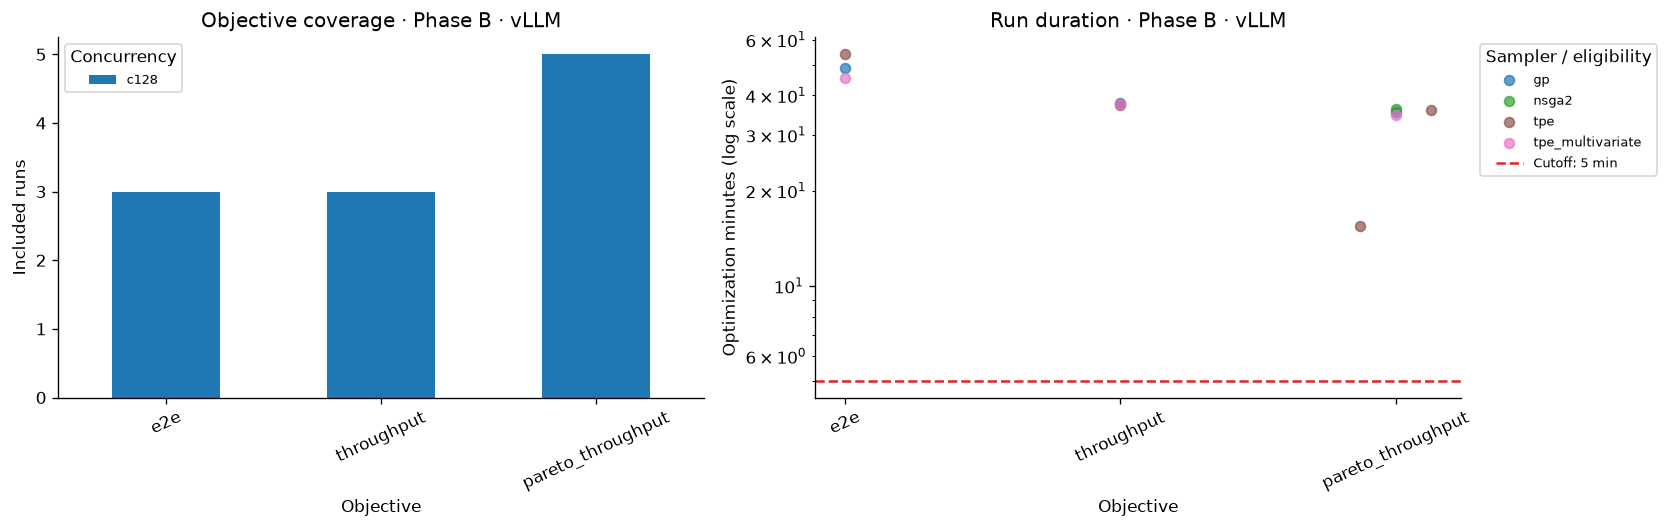

,state,trials
0,COMPLETE,216
1,RUNNING,1


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r3`
- `B-vllm-c128-e2e-tpe-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-tpe-s11-r3,optuna-inference-lab-ezy2i4mn,15gvekae,e2e,C21,tpe,54.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: balanced,11,2597.275879,False,W&B candidate summary only
B-vllm-c128-e2e-tpe_multivariate-s11-r3,optuna-inference-lab-ezy2i4mn,e31bigam,e2e,C21,tpe_multivariate,45.48,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 30976max_num_seqs: 128performance_mode: interactivity,15,2419.543139,False,W&B candidate summary only
B-vllm-c128-e2e-gp-s11-r3,optuna-inference-lab-ezy2i4mn,a8ktejgz,e2e,C21,gp,48.74,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,13,2318.987960,False,W&B candidate summary only


##### Matching context C21

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

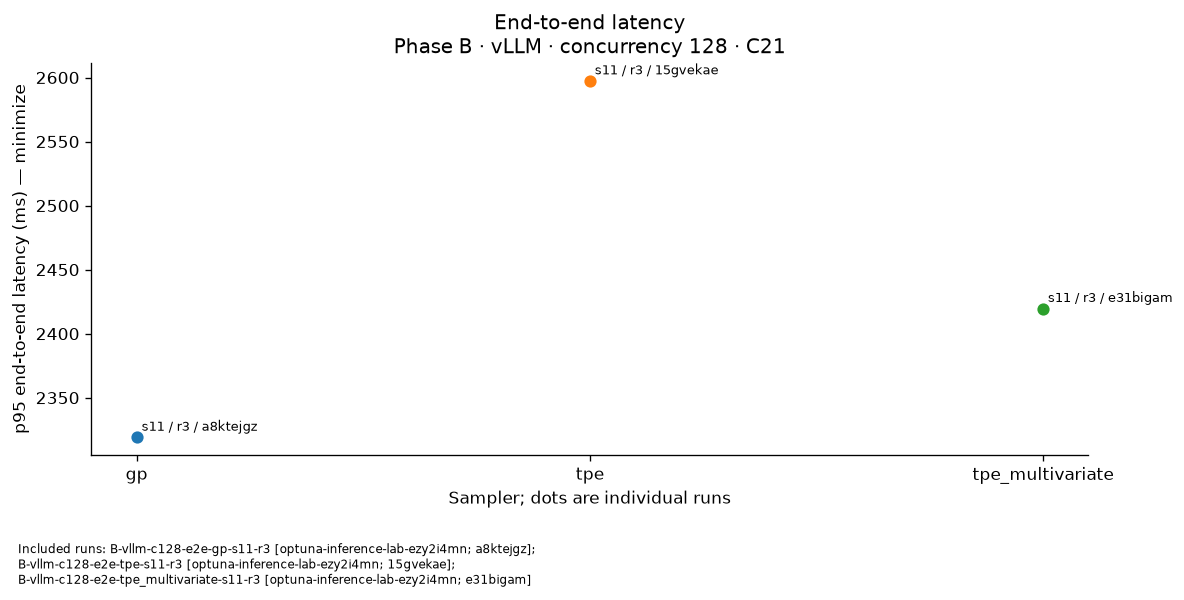

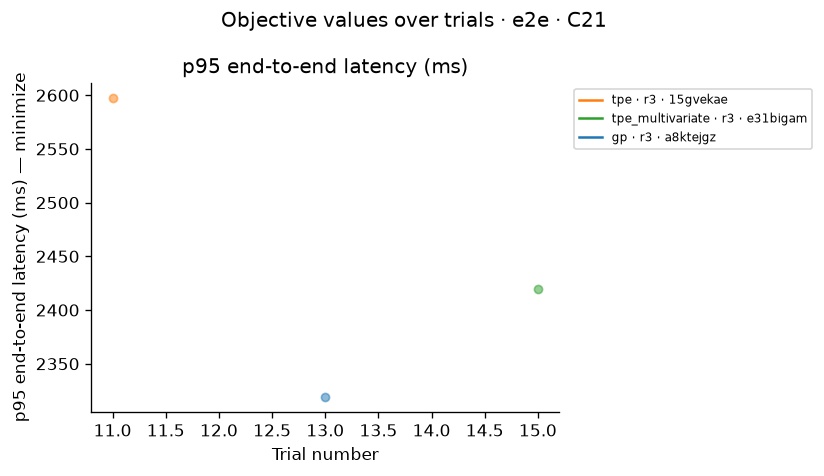

No local runs have enough varied completed trials for retrospective importance.
W&B summary-only runs do not contain trial histories for this calculation.


/home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r1`
- `B-vllm-c128-throughput-tpe-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-tpe-s11-r1,optuna-phase-b-v1,43sekwr7,throughput,C15,tpe,37.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 15104max_num_seqs: 128performance_mode: throughput,18,7216.036606,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,4hxfaxio,throughput,C15,tpe_multivariate,37.69,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: balanced,16,7338.657147,False,all local COMPLETE trials
B-vllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,2f2gjeil,throughput,C15,gp,37.70,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,17,7258.913112,False,all local COMPLETE trials


##### Matching context C15

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

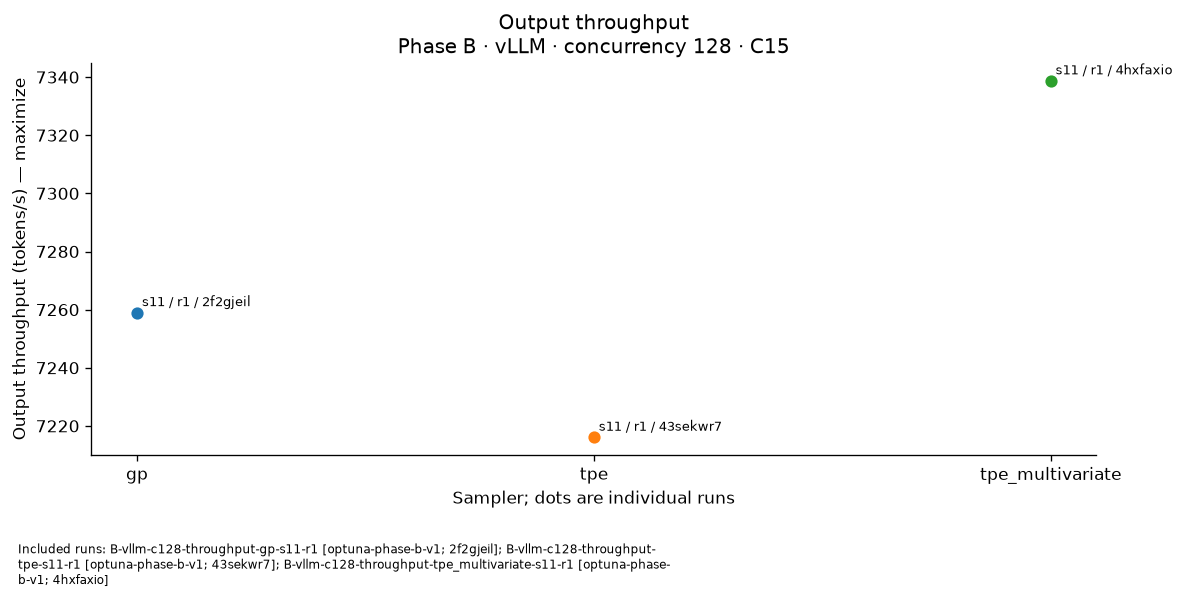

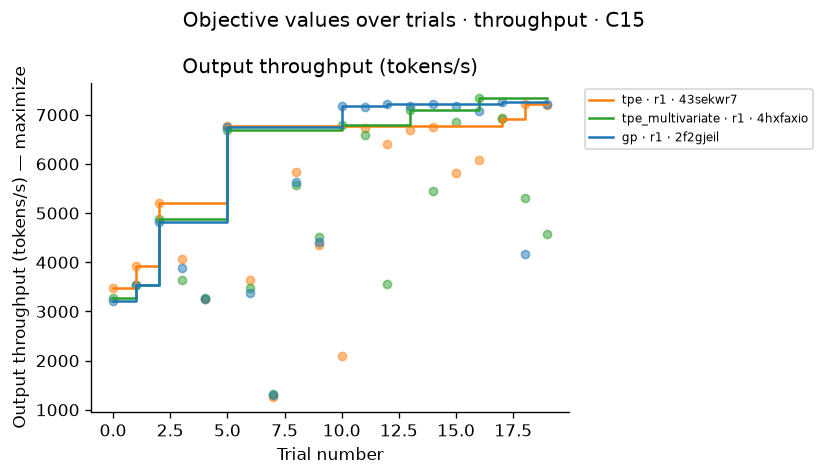

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
18,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,1,max_num_seqs,0.783386
19,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,2,gpu_memory_utilization,0.135532
20,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,3,max_num_batched_tokens,0.025262
21,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,4,attention_backend,0.017319
22,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,5,kv_cache_dtype,0.016181
23,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,6,graph_mode,0.008308
24,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,7,performance_mode,0.006503
25,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,8,async_scheduling,0.006189
26,B-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,9,enable_prefix_caching,0.001320
0,B-vllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,1,max_num_batched_tokens,0.760358


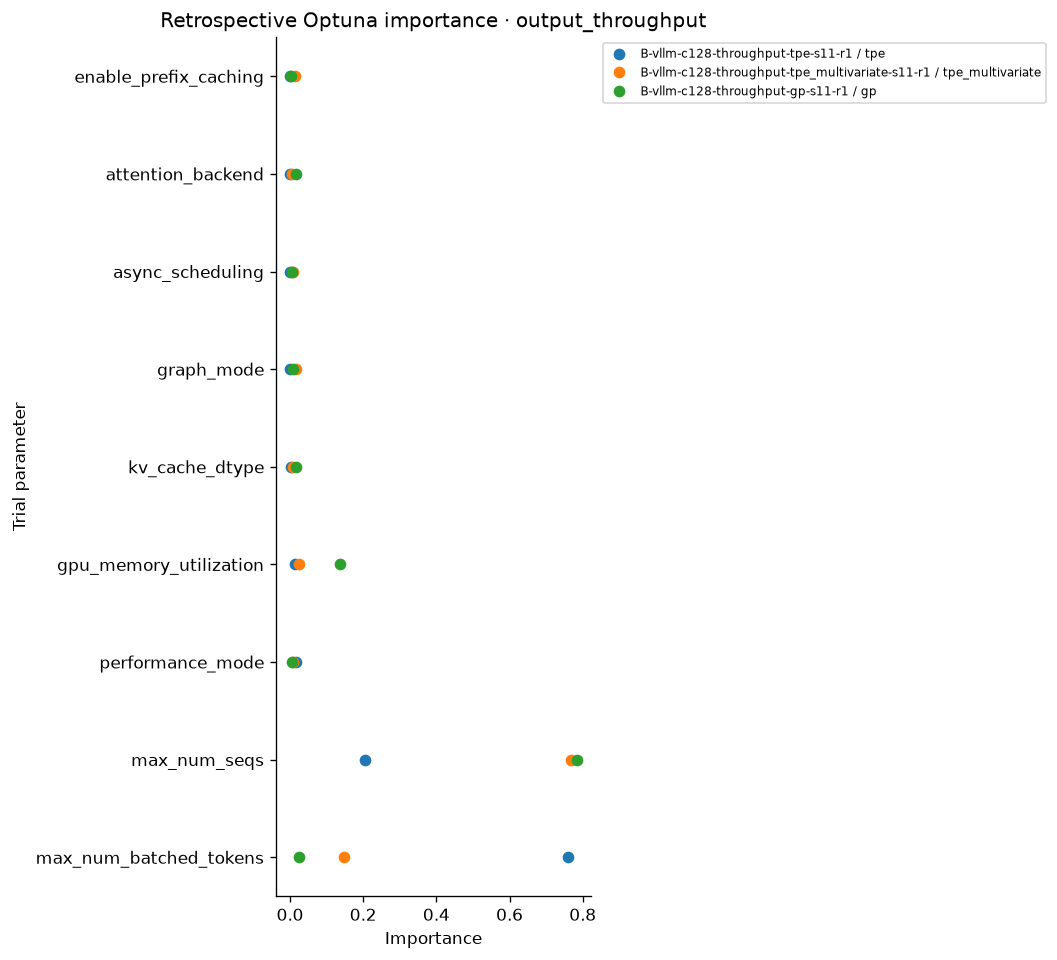

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: s11. Repeats: r2, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-pareto_throughput-gp-s11-r3`
- `B-vllm-c128-pareto_throughput-nsga2-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe-s11-r2`
- `B-vllm-c128-pareto_throughput-tpe-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C10,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,6774.959546,3398.543602,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C10,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 7424max_num_seqs: 96performance_mode: balanced,13,6553.758814,3299.040544,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C10,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 13312max_num_seqs: 72performance_mode: balanced,16,5927.288289,3176.463044,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C10,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 5376max_num_seqs: 112performance_mode: throughput,17,6983.615323,3409.441405,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3,optuna-phase-b-v1,x5yc2flo,pareto_throughput,C10,tpe_multivariate,34.69,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19456max_num_seqs: 104performance_mode: balanced,10,6795.390953,3474.930845,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3,optuna-phase-b-v1,x5yc2flo,pareto_throughput,C10,tpe_multivariate,34.69,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 16896max_num_seqs: 128performance_mode: balanced,13,6505.303470,2672.202992,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-gp-s11-r3,optuna-phase-b-v1,dpe6es0u,pareto_throughput,C10,gp,35.56,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 29184max_num_seqs: 128performance_mode: interactivity,11,7267.537112,2356.134052,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-nsga2-s11-r3,optuna-phase-b-v1,izfuyq9r,pareto_throughput,C10,nsga2,36.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,6709.988591,3588.033864,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-nsga2-s11-r3,optuna-phase-b-v1,izfuyq9r,pareto_throughput,C10,nsga2,36.22,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.85graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 88performance_mode: balanced,17,6072.547553,3407.458722,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r2,optuna-phas

##### Matching context C10

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

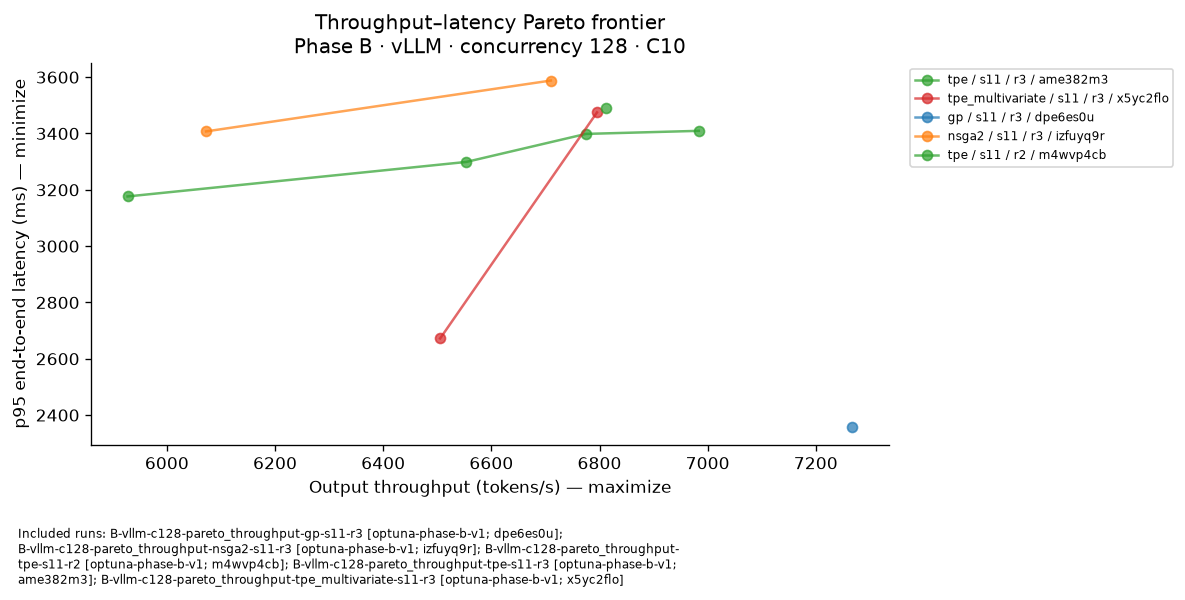

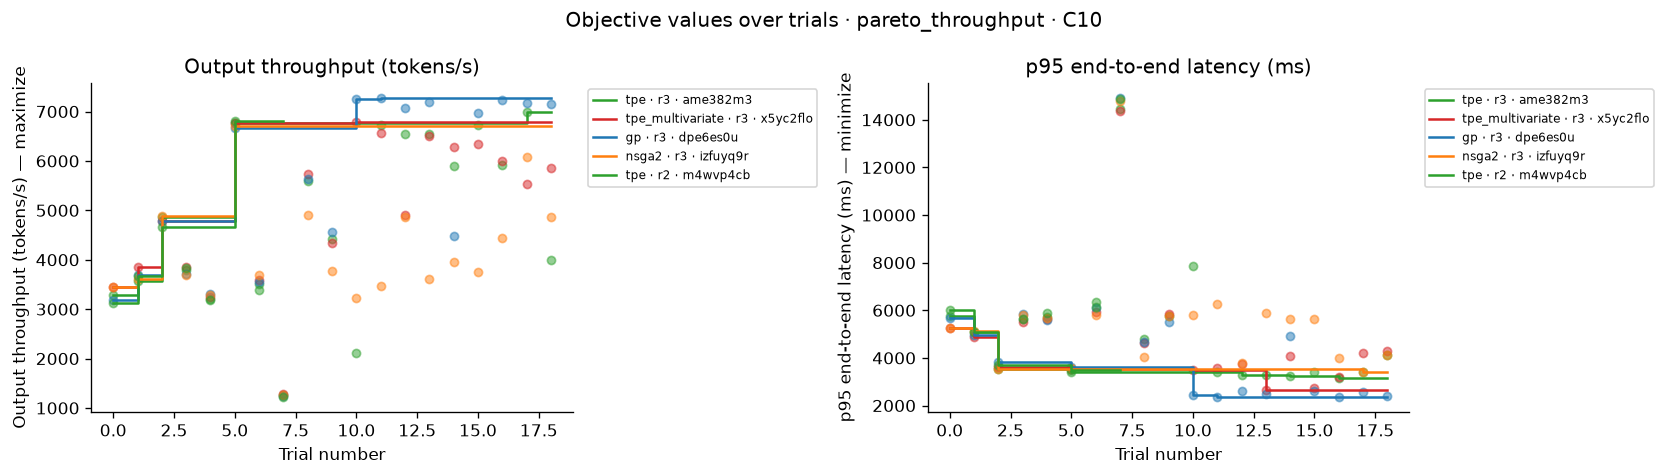

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
36,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,1,max_num_seqs,9.208684e-01
37,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,2,graph_mode,1.225834e-02
38,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,3,attention_backend,1.225834e-02
39,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,4,gpu_memory_utilization,1.155690e-02
40,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,5,performance_mode,1.079151e-02
41,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,6,kv_cache_dtype,8.570586e-03
42,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,7,enable_prefix_caching,8.570586e-03
43,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,8,async_scheduling,8.570586e-03
44,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,output_throughput,9,max_num_batched_tokens,6.554717e-03
45,B-vllm-c128-pareto_throughput-gp-s11-r3,gp,p95_e2e_latency_ms,1,max_num_seqs,6.110709e-01


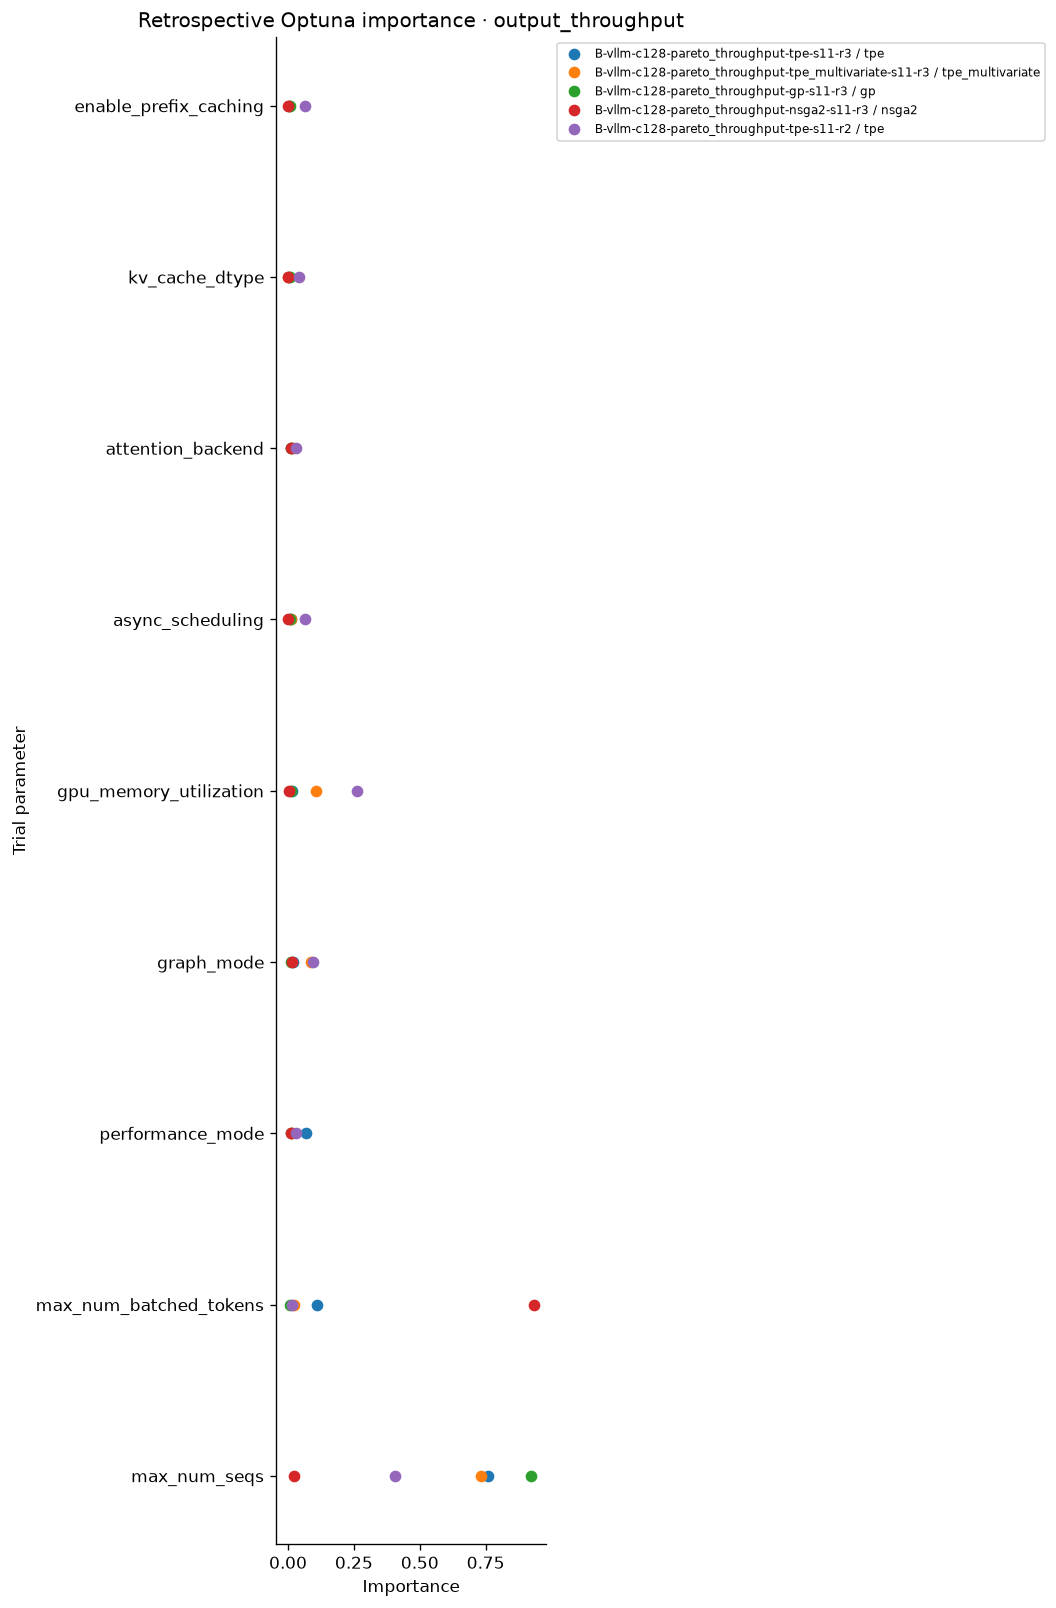

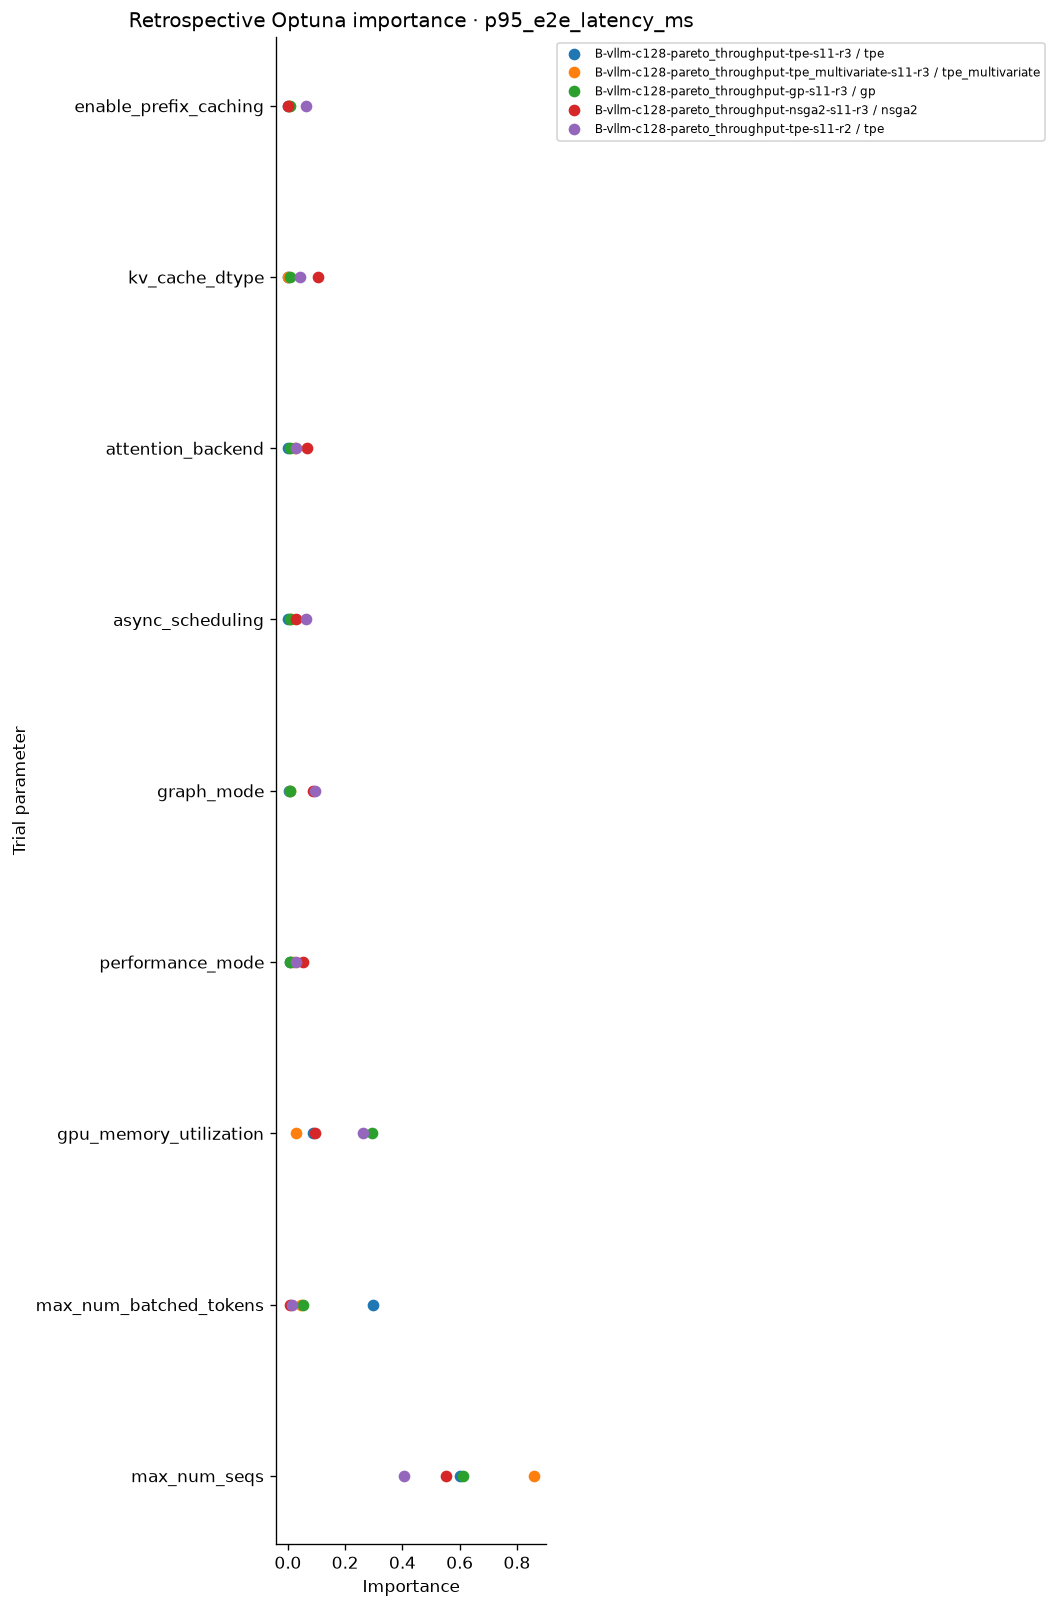

In [26]:
show_framework("B", "vllm")

### TRT-LLM

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Phase B {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase B / TRT-LLM: 19 included runs; cutoff 5 minutes


**Runs included: 18.** Optimizer seeds: s11. Repeats: r1, r2, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2`
- `B-trtllm-c128-e2e-gp-s11-r22`
- `B-trtllm-c128-e2e-tpe-s11-r1`
- `B-trtllm-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r22`
- `B-trtllm-c128-pareto_throughput-gp-s11-r1`
- `B-trtllm-c128-pareto_throughput-gp-s11-r22`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r22`
- `B-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r22`
- `B-trtllm-c128-throughput-gp-s11-r1`
- `B-trtllm-c128-throughput-gp-s11-r22`
- `B-trtllm-c128-throughput-tpe-s11-r22`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r22`

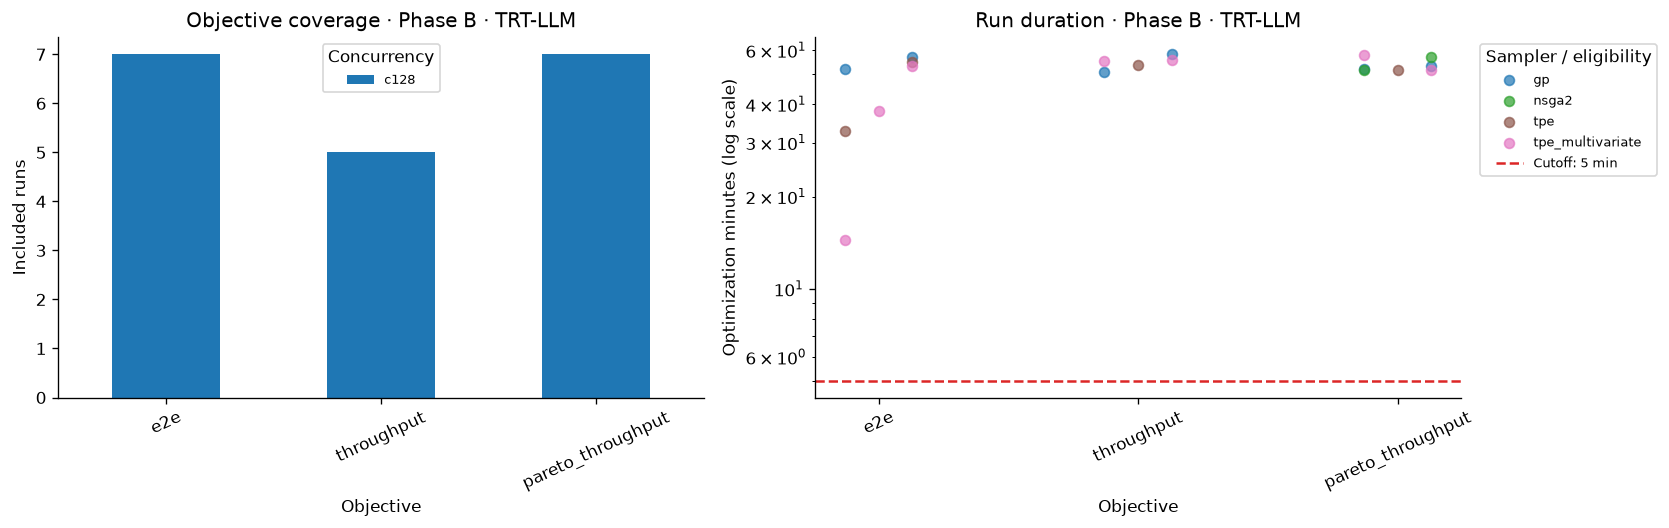

,state,trials
0,COMPLETE,325
1,FAIL,21


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1, r2, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2`
- `B-trtllm-c128-e2e-gp-s11-r22`
- `B-trtllm-c128-e2e-tpe-s11-r1`
- `B-trtllm-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-tpe_multivariate-s11-r2 [optuna-phase-b-v1 / ul1h9fbn],optuna-phase-b-v1,ul1h9fbn,e2e,C06,tpe_multivariate,14.41,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 32max_num_tokens: 6144,15.0,3752.892612,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r22,optuna-phase-b-v1,wkyxp7vs,e2e,C20,gp,57.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,10.0,2124.685405,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,nx5p83d3,e2e,C06,tpe,32.68,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,9.0,3816.721492,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r2,optuna-phase-b-v1,rigivcxx,e2e,C06,gp,52.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,5.0,3805.106405,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r22,optuna-phase-b-v1,hgilz7qb,e2e,C20,tpe,55.08,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5.0,2970.294046,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r22,optuna-phase-b-v1,gzn2ba1j,e2e,C20,tpe_multivariate,53.39,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 64max_num_tokens: 12032,10.0,2661.387811,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r2 [optuna-phase-b-v1 / es98j5kt],optuna-phase-b-v1,es98j5kt,e2e,NaN,tpe_multivariate,38.13,—,NaN,NaN,None,no eligible result


##### Matching context C06

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

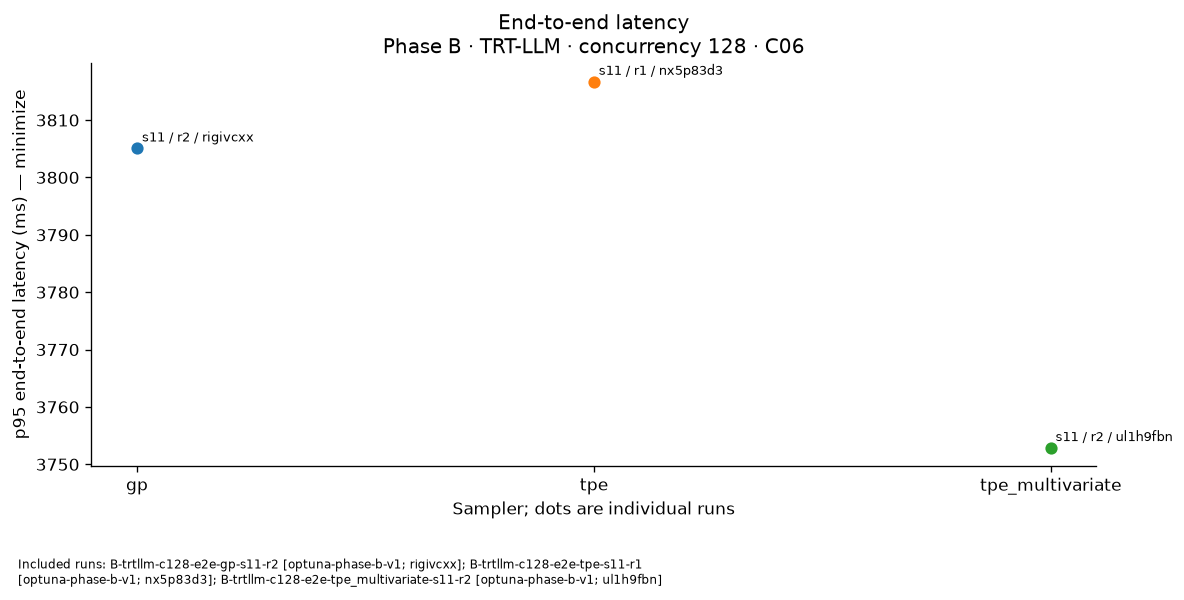

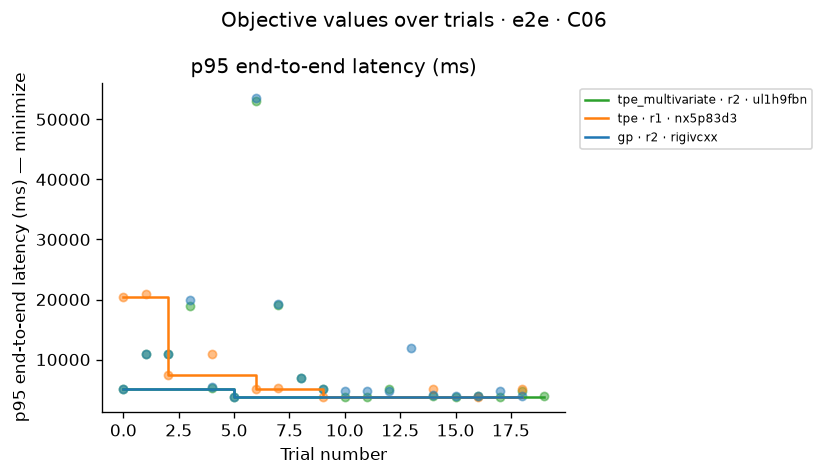

##### Matching context C20

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

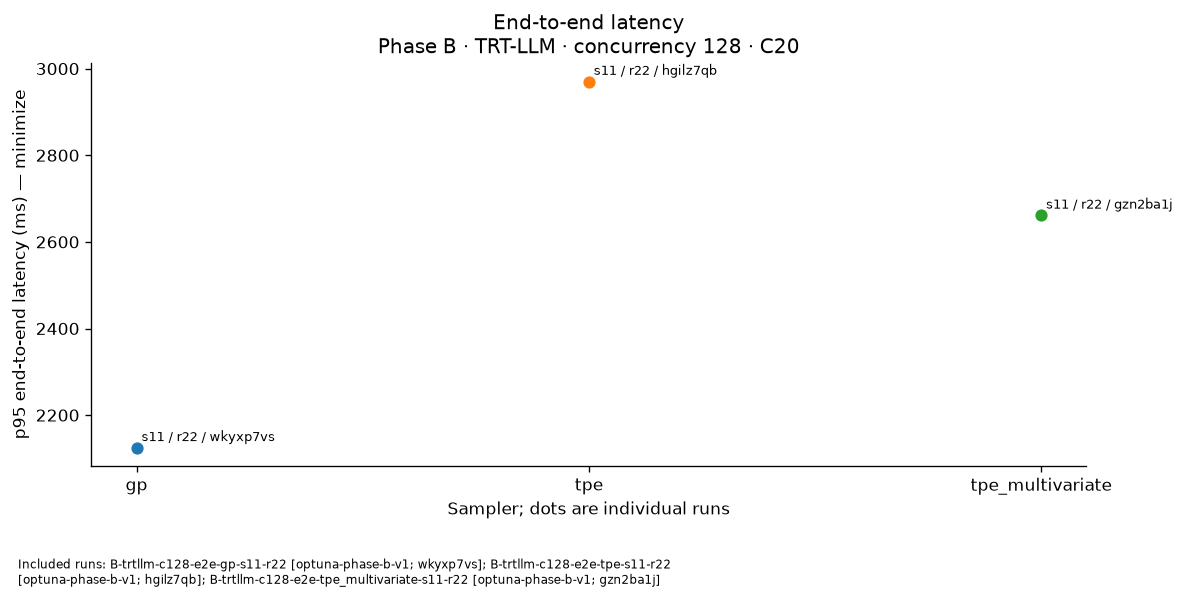

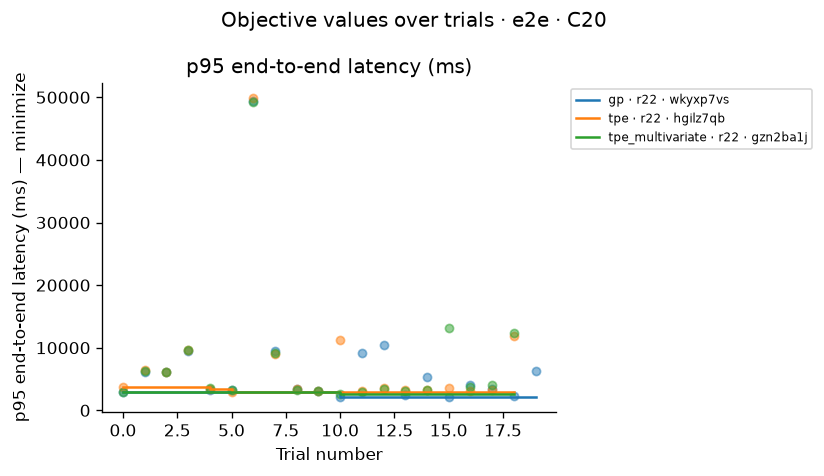

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
24,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,1,max_num_tokens,0.525155
25,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,2,max_batch_size,0.236975
26,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,3,enable_block_reuse,0.087552
27,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,4,kv_cache_free_gpu_memory_fraction,0.071534
28,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,5,capacity_scheduler_policy,0.061023
29,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,6,enable_chunked_prefill,0.015252
30,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,7,graph_enabled,0.002509
31,B-trtllm-c128-e2e-gp-s11-r2,gp,p95_e2e_latency_ms,8,attn_backend,0.000000
8,B-trtllm-c128-e2e-gp-s11-r22,gp,p95_e2e_latency_ms,1,max_num_tokens,0.747027
9,B-trtllm-c128-e2e-gp-s11-r22,gp,p95_e2e_latency_ms,2,max_batch_size,0.186155


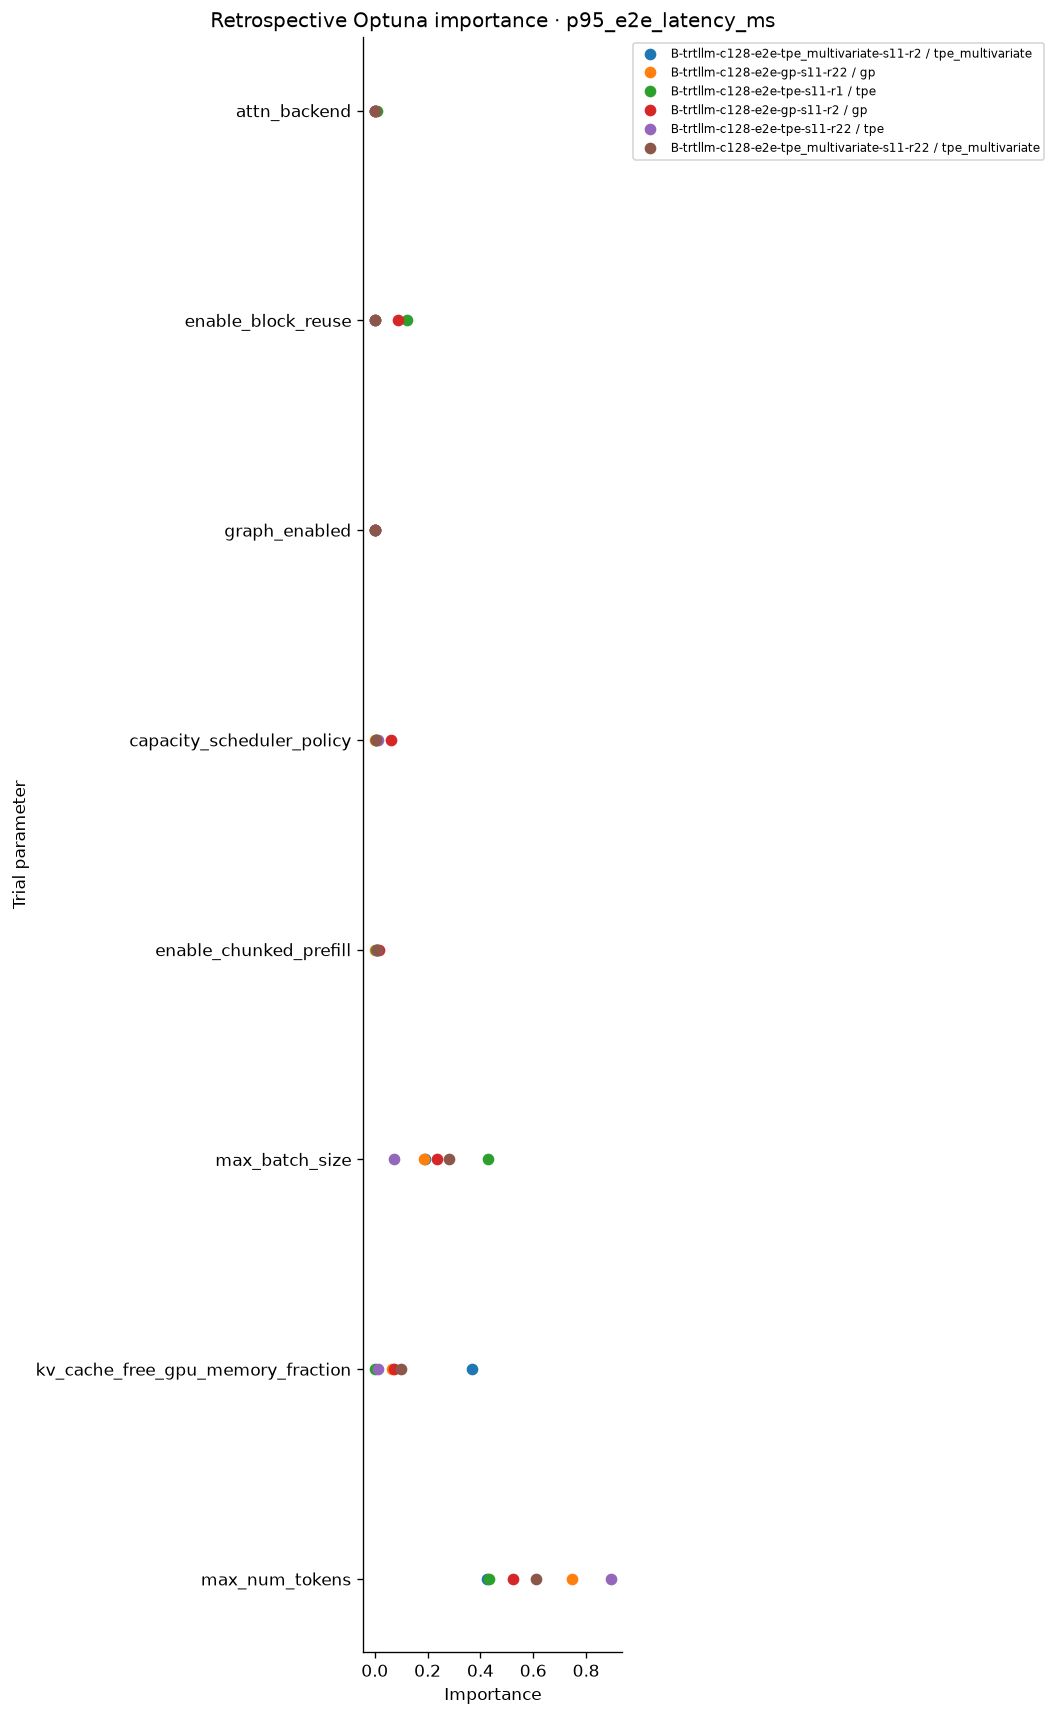

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 5.** Optimizer seeds: s11. Repeats: r1, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-gp-s11-r1`
- `B-trtllm-c128-throughput-gp-s11-r22`
- `B-trtllm-c128-throughput-tpe-s11-r22`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-gp-s11-r22,optuna-phase-b-v1,9y5kjcb9,throughput,C14,gp,58.51,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 22016,13,7911.503773,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cwsqjp3c,throughput,C05,tpe_multivariate,55.45,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,10,4311.995156,False,all local COMPLETE trials
B-trtllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,4qkrby5x,throughput,C05,gp,51.10,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,13,4310.002299,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r22,optuna-phase-b-v1,oggia3g4,throughput,C14,tpe,53.66,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 28672,17,7798.318941,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r22,optuna-phase-b-v1,qbbdfr6u,throughput,C14,tpe_multivariate,55.65,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 25856,10,7756.766881,False,all local COMPLETE trials


##### Matching context C05

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

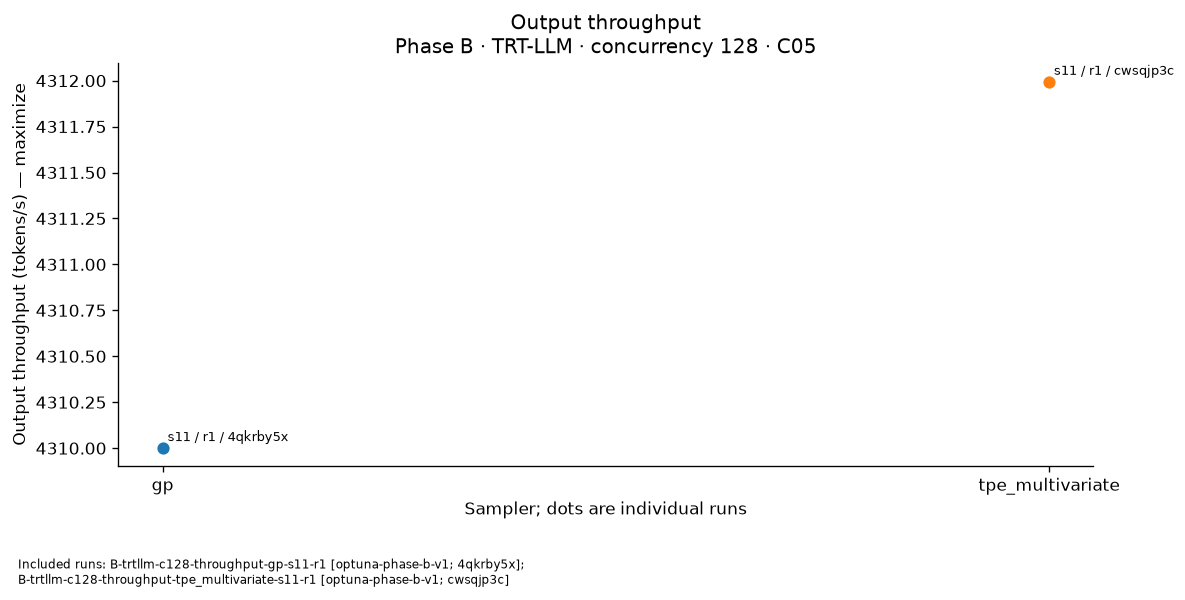

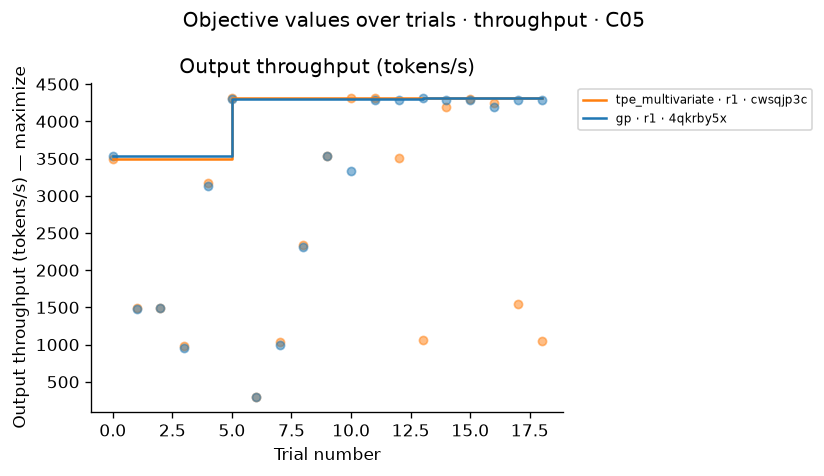

##### Matching context C14

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

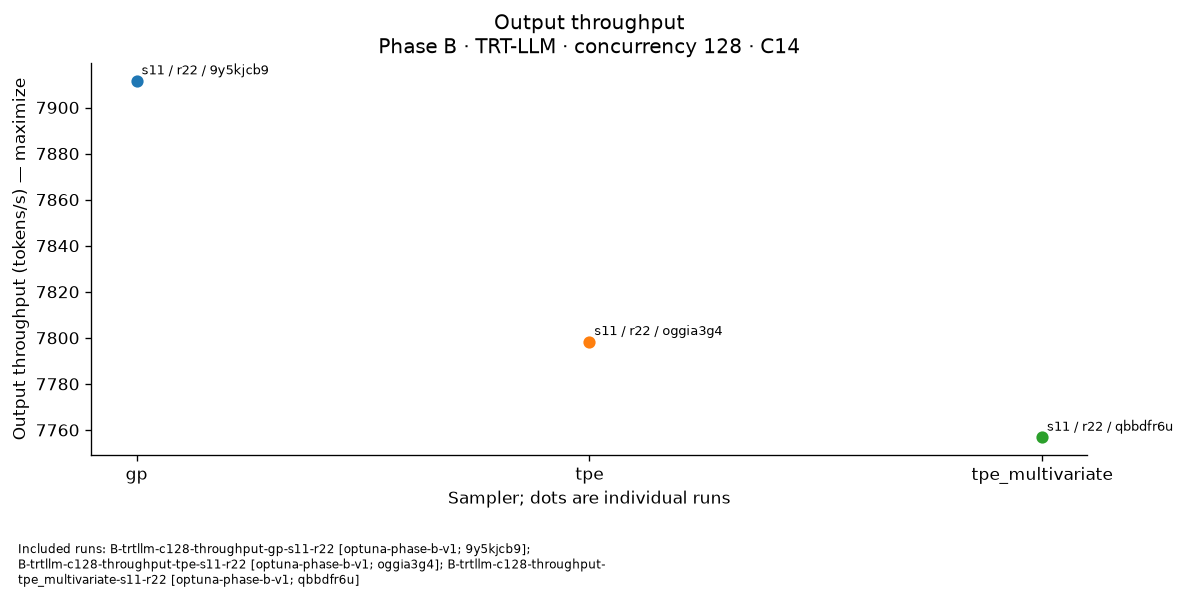

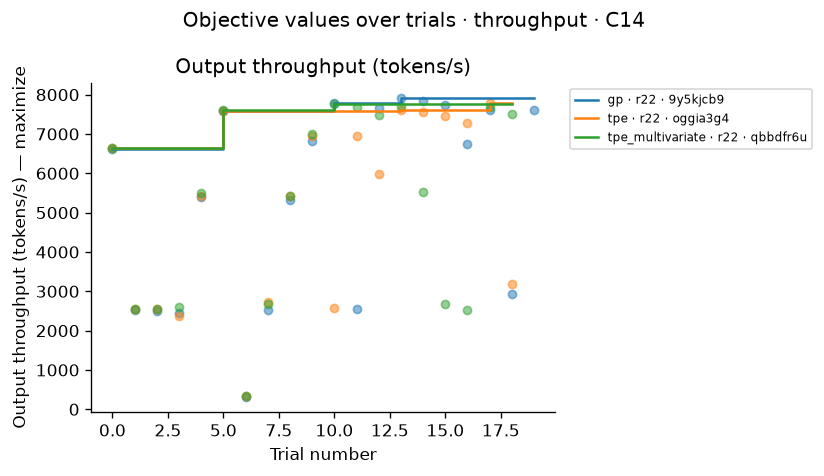

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
16,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,1,max_num_tokens,0.306714
17,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,2,max_batch_size,0.306714
18,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,3,enable_block_reuse,0.297011
19,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,4,capacity_scheduler_policy,0.042733
20,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,5,kv_cache_free_gpu_memory_fraction,0.031974
21,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,6,enable_chunked_prefill,0.010149
22,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,7,graph_enabled,0.004707
23,B-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,8,attn_backend,0.000000
0,B-trtllm-c128-throughput-gp-s11-r22,gp,output_throughput,1,max_num_tokens,0.768963
1,B-trtllm-c128-throughput-gp-s11-r22,gp,output_throughput,2,max_batch_size,0.185220


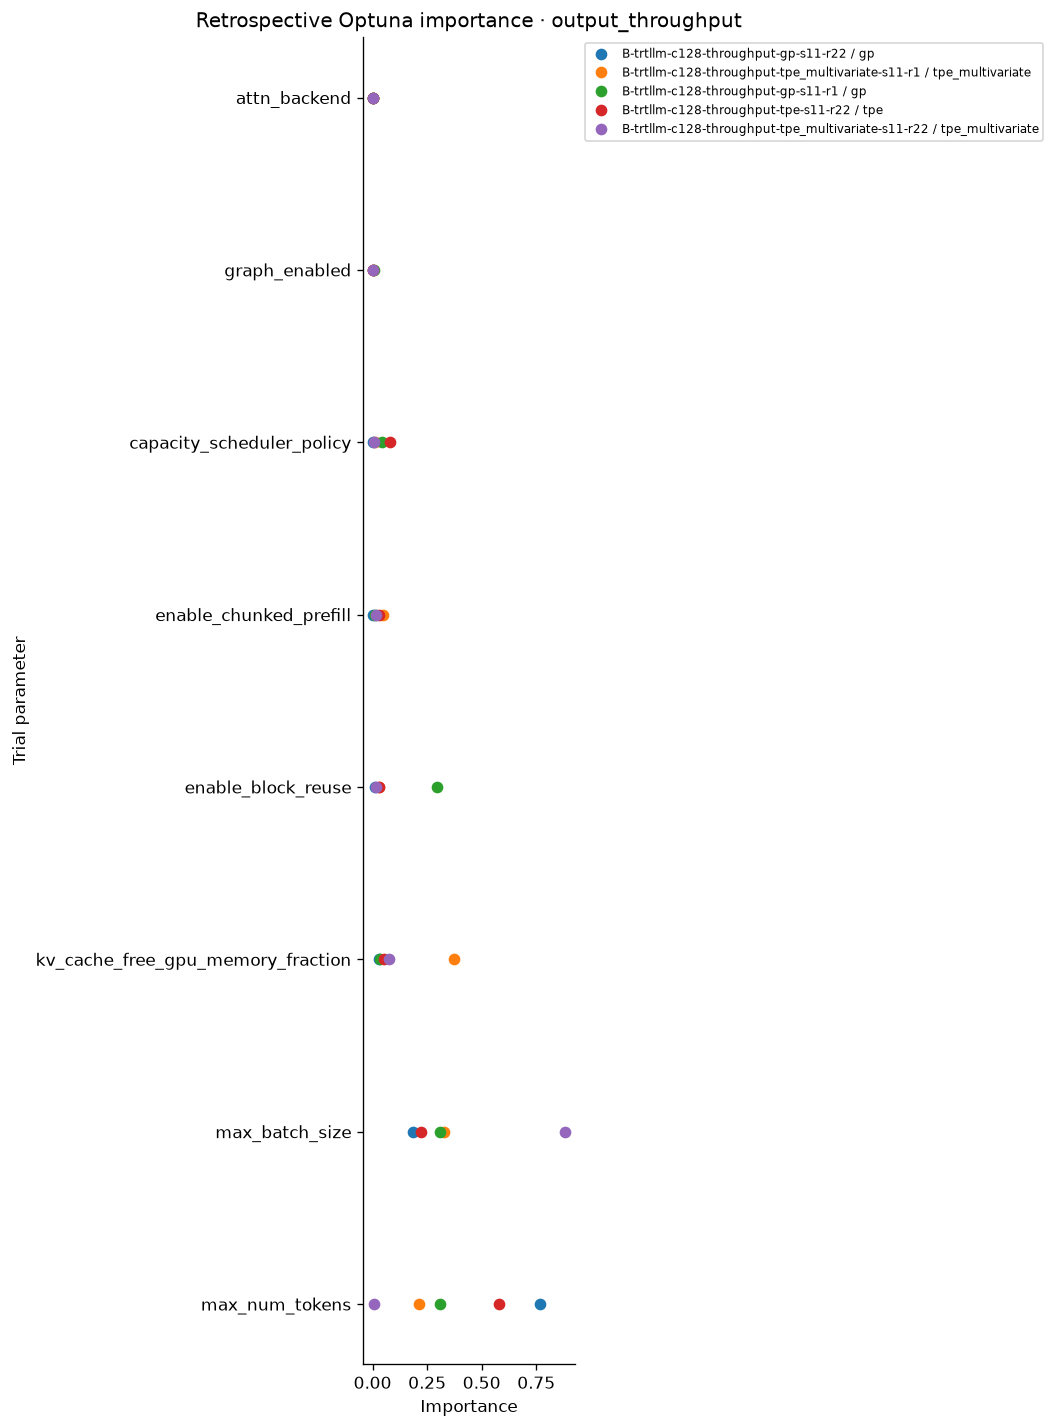

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 7.** Optimizer seeds: s11. Repeats: r1, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-pareto_throughput-gp-s11-r1`
- `B-trtllm-c128-pareto_throughput-gp-s11-r22`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r22`
- `B-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-pareto_throughput-gp-s11-r22,optuna-phase-b-v1,867reo7m,pareto_throughput,C09,gp,53.35,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 6656,10,7772.859679,2303.878451,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-gp-s11-r22,optuna-phase-b-v1,867reo7m,pareto_throughput,C09,gp,53.35,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 128max_num_tokens: 32768,18,7776.706094,2388.278669,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,89h6ig16,pareto_throughput,C04,tpe_multivariate,57.85,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,5,4297.197488,3833.011336,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,89h6ig16,pareto_throughput,C04,tpe_multivariate,57.85,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,10,4295.909169,3830.874704,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,suhvn561,pareto_throughput,C04,gp,52.23,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,11,4288.341401,3831.061007,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,i7ygpr6d,pareto_throughput,C04,nsga2,51.56,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 32max_num_tokens: 2048,15,3296.749123,5065.204020,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C09,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5,7634.273221,3230.299452,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C09,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 88max_num_tokens: 27392,9,7107.487535,3042.284144,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C09,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 96max_num_tokens: 31744,11,7265.57

##### Matching context C04

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

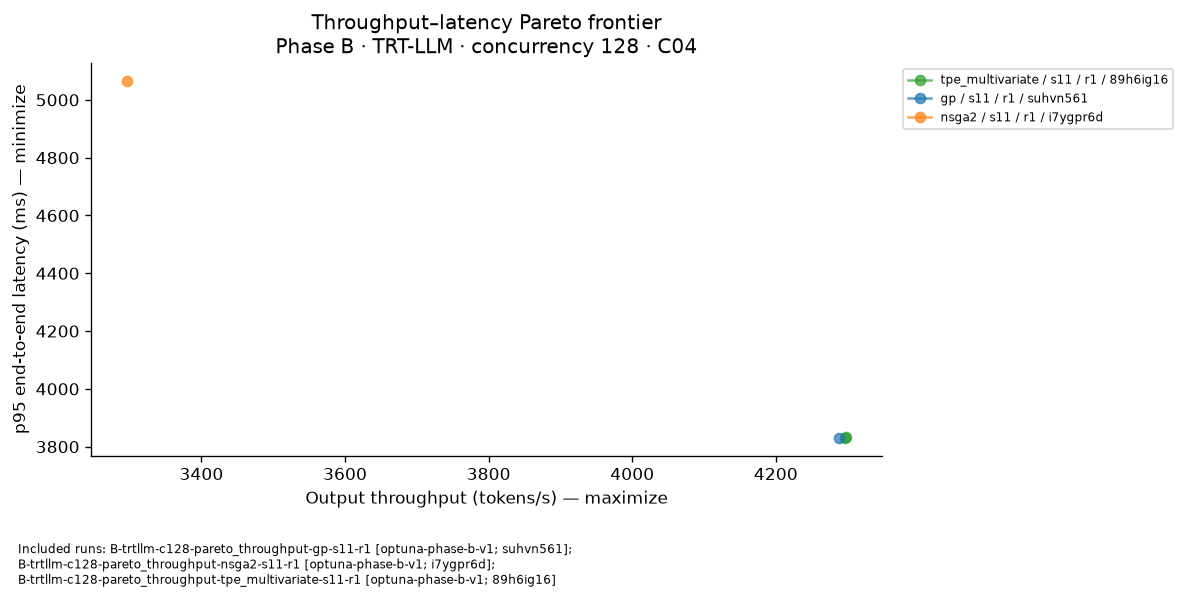

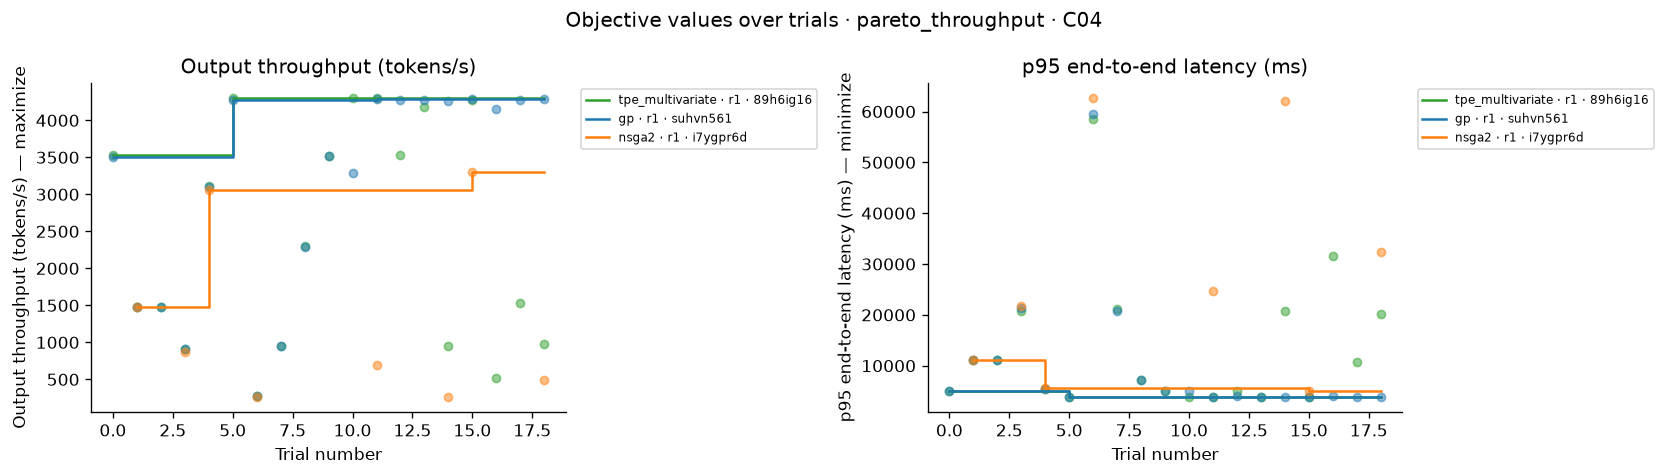

##### Matching context C09

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

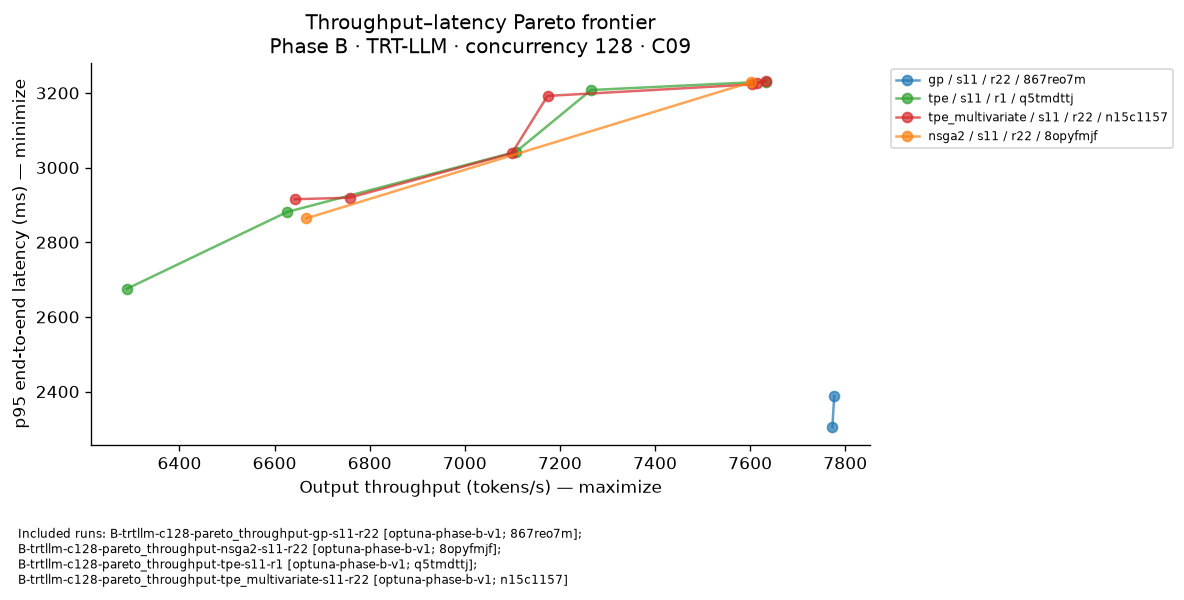

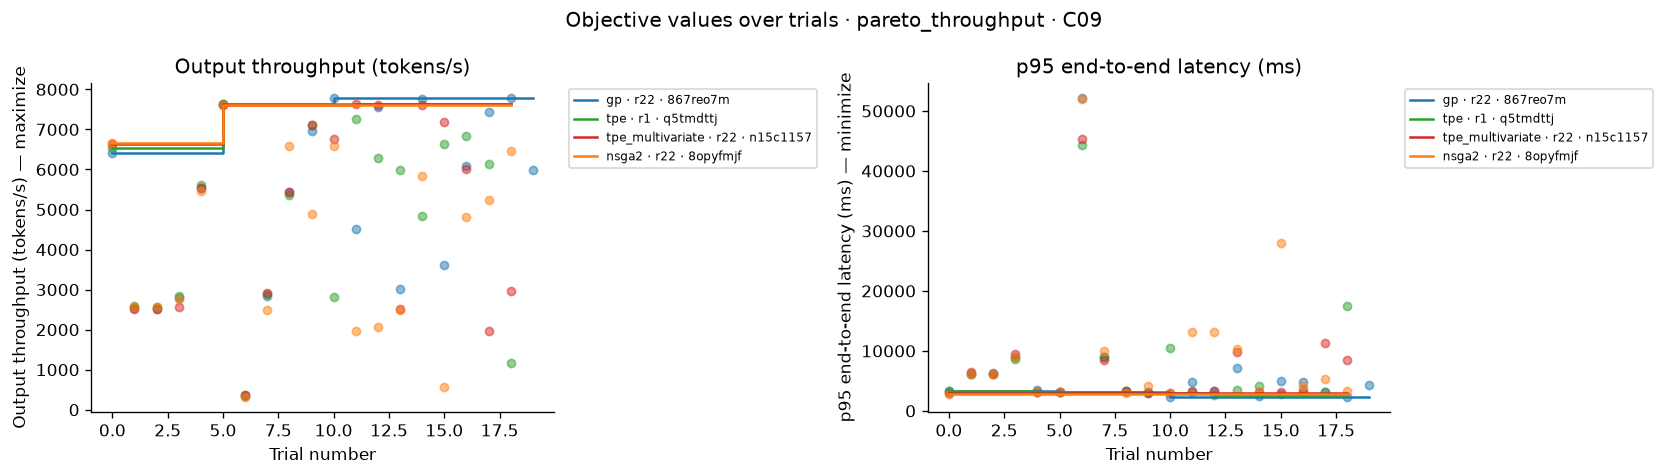

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
32,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,1,max_num_tokens,0.294373
33,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,2,max_batch_size,0.294373
34,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,3,enable_block_reuse,0.285060
35,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,4,kv_cache_free_gpu_memory_fraction,0.056908
36,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,5,enable_chunked_prefill,0.055028
37,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,6,capacity_scheduler_policy,0.009740
38,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,7,graph_enabled,0.004517
39,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,8,attn_backend,0.000000
40,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,1,max_num_tokens,0.294373
41,B-trtllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_batch_size,0.294373


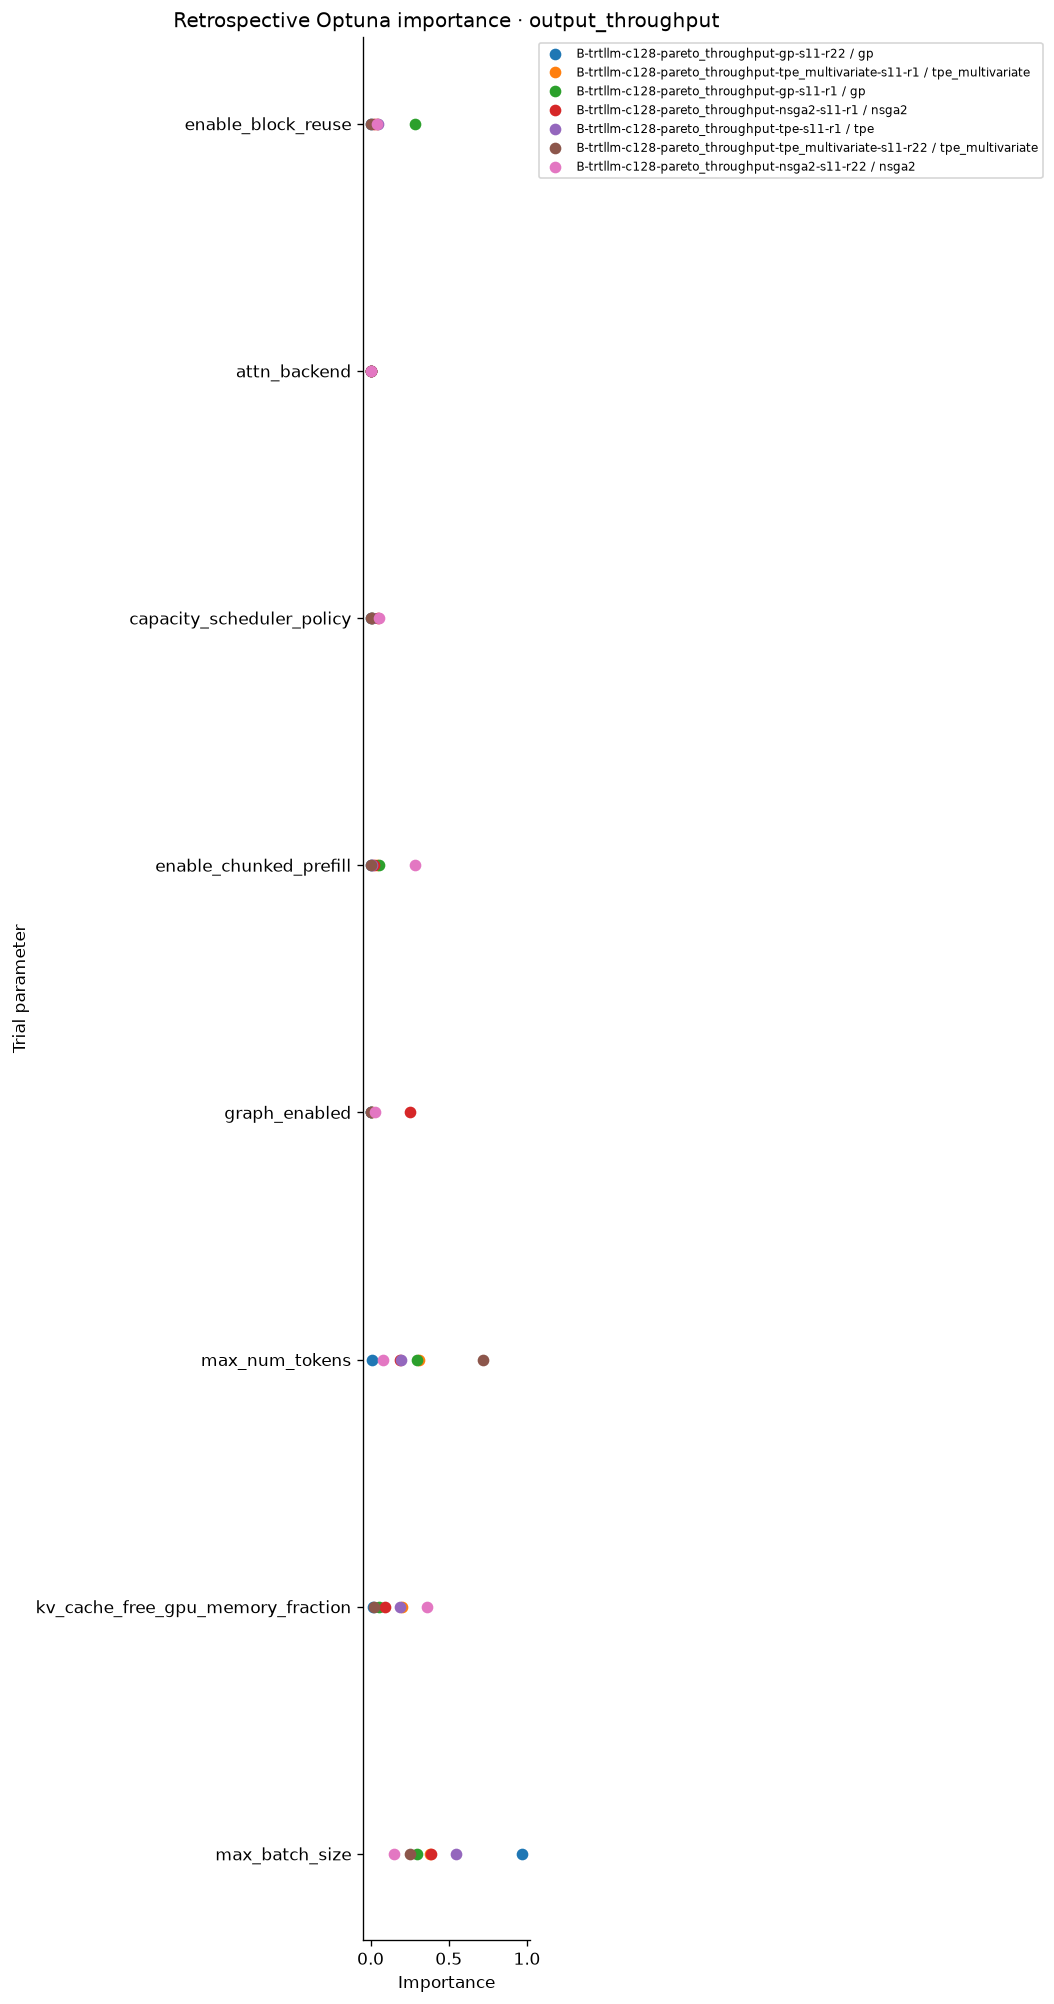

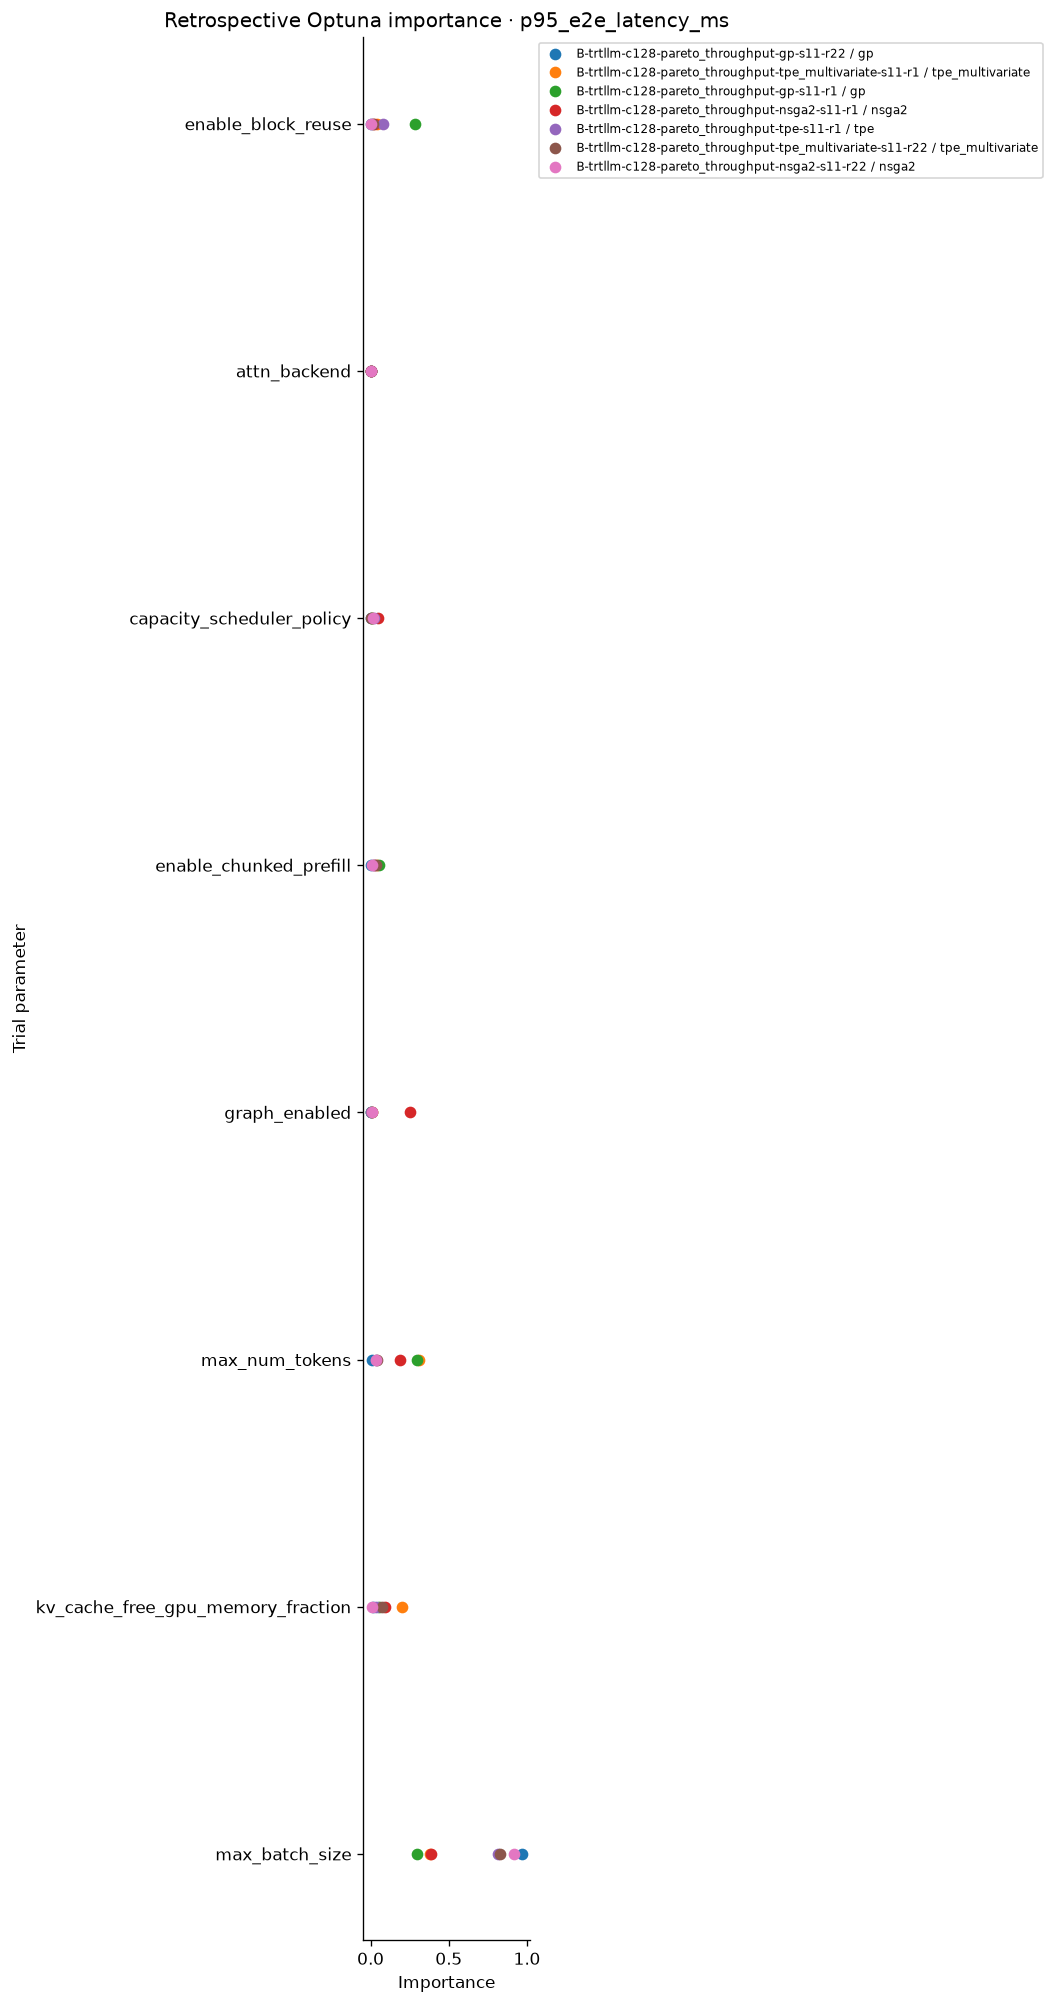

In [27]:
show_framework("B", "trtllm")

### SGLang

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Phase B {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase B / SGLang: 22 included runs; cutoff 5 minutes


**Runs included: 22.** Optimizer seeds: s11. Repeats: r1, r21, r22, r3, r8.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r1`
- `B-sglang-c128-e2e-gp-s11-r22`
- `B-sglang-c128-e2e-grid-s11-r3`
- `B-sglang-c128-e2e-tpe-s11-r1`
- `B-sglang-c128-e2e-tpe-s11-r22`
- `B-sglang-c128-e2e-tpe-s11-r8`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r22`
- `B-sglang-c128-pareto_throughput-gp-s11-r1`
- `B-sglang-c128-pareto_throughput-gp-s11-r21`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r1`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r3`
- `B-sglang-c128-throughput-tpe-s11-r21`
- `B-sglang-c128-throughput-tpe-s11-r3`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r3`

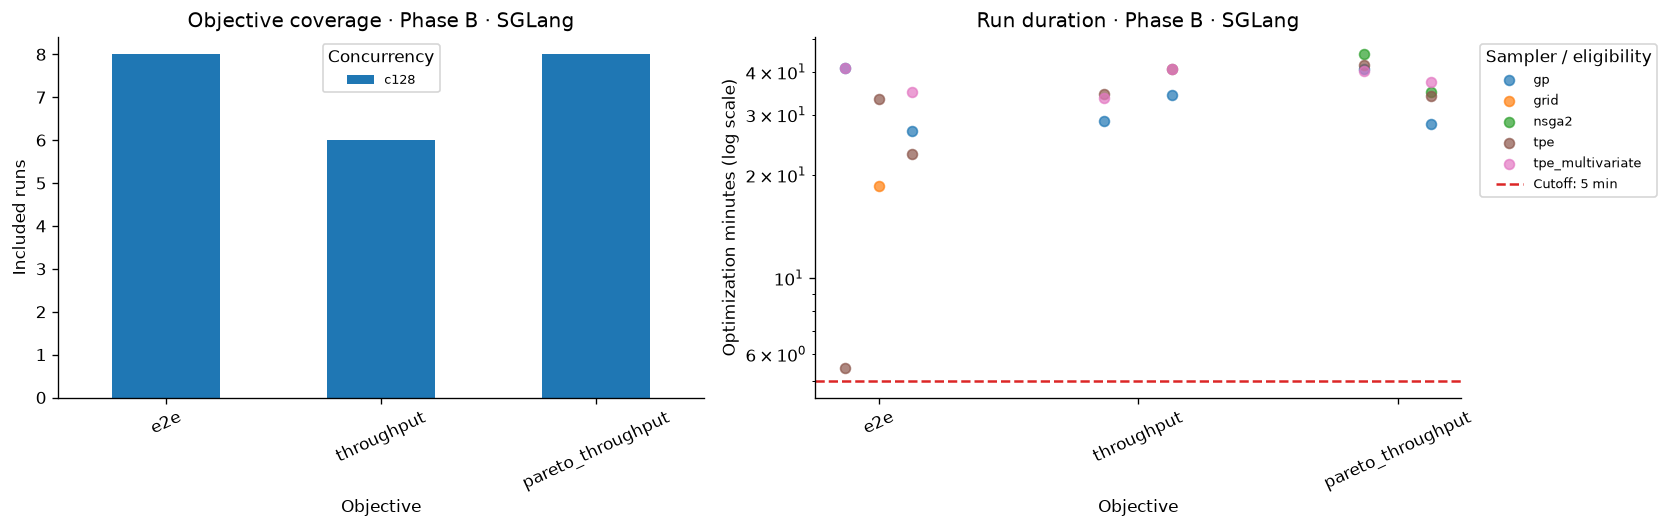

,state,trials
0,COMPLETE,320
1,FAIL,75


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 8.** Optimizer seeds: s11. Repeats: r1, r22, r3, r8.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r1`
- `B-sglang-c128-e2e-gp-s11-r22`
- `B-sglang-c128-e2e-grid-s11-r3`
- `B-sglang-c128-e2e-tpe-s11-r1`
- `B-sglang-c128-e2e-tpe-s11-r22`
- `B-sglang-c128-e2e-tpe-s11-r8`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-e2e-tpe-s11-r8,optuna-phase-b-v1,jw6spotx,e2e,C17,tpe,23.10,attention_backend: flashinferchunked_prefill_size: 6144cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Falseenable_mixed_chunk: Truemax_prefill_tokens: 32768max_running_requests: 16mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: lpm,5,7837.002605,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r1,optuna-phase-b-v1,5n8lx4d0,e2e,C17,tpe_multivariate,40.99,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,12,5399.345671,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r1,optuna-phase-b-v1,3q8960rp,e2e,C17,gp,41.14,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,5395.039771,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r22,optuna-phase-b-v1,8hidg674,e2e,C18,tpe,33.32,attention_backend: tritonchunked_prefill_size: 24320cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 88mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: lpm,14,4255.839024,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r22,optuna-phase-b-v1,cukx0dj0,e2e,C18,tpe_multivariate,34.93,attention_backend: tritonchunked_prefill_size: 27904cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 32768max_running_requests: 88mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: lpm,17,4370.083186,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r22,optuna-phase-b-v1,b9tye6iv,e2e,C18,gp,26.94,attention_backend: flashinferchunked_prefill_size: 22016cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 24576max_running_requests: 80mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: lpm,5,4632.404322,False,all local COMPLETE trials
B-sglang-c128-e2e-grid-s11-r3,optuna-phase-b-v1,9zaa26sm,e2e,C17,grid,18.53,attention_backend: fa3chunked_prefill_size: 8192disable_radix_cache: Falsegraph_enabled: Falsemax_prefill_tokens: 16384max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 1.0schedule_policy: lpm,1,16458.152183,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,sd333o4y,e2e,C17,tpe,5.47,attention_backend: tritonchunked_prefill_size: 6144disable_radix_cache: Truegraph_enabled: Falsemax_prefill_tokens: 32768max_running_requests: 24mem_fraction_static: 0.8schedule_conservativeness: 1.5schedule_policy: lpm,0,19964.462329,False,all local COMPLETE trials


##### Matching context C17

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

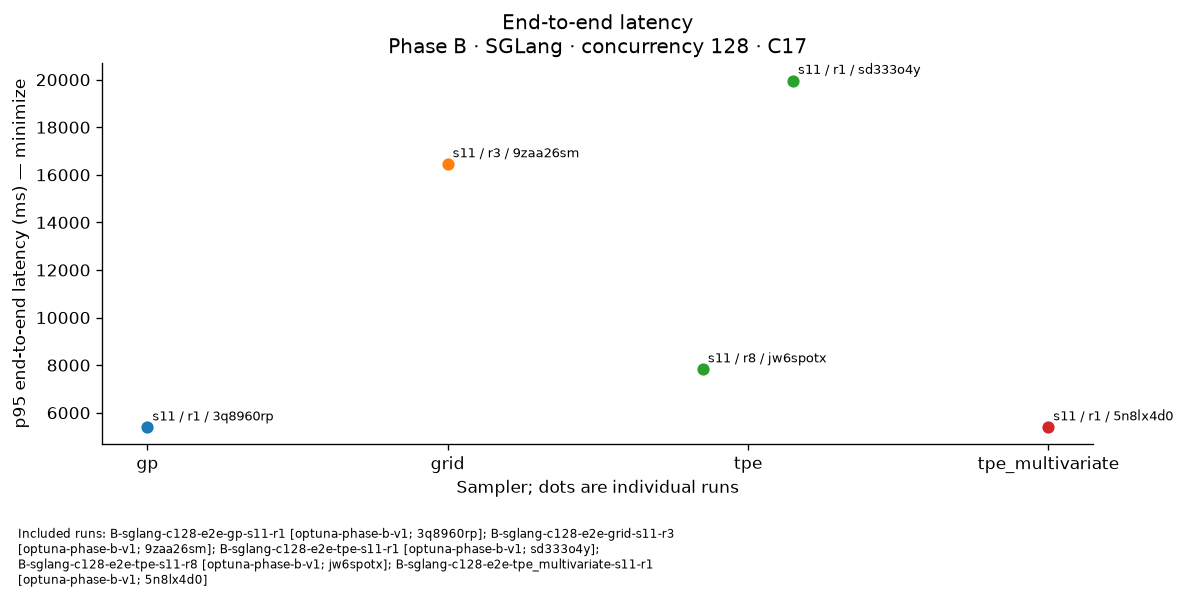

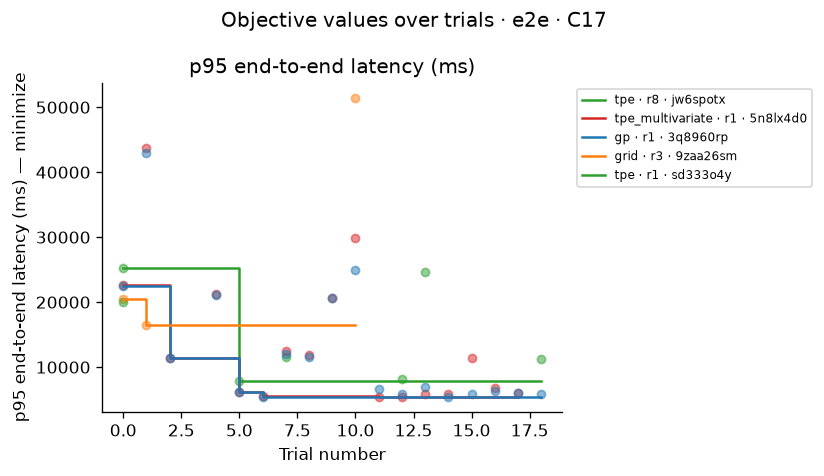

##### Matching context C18

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

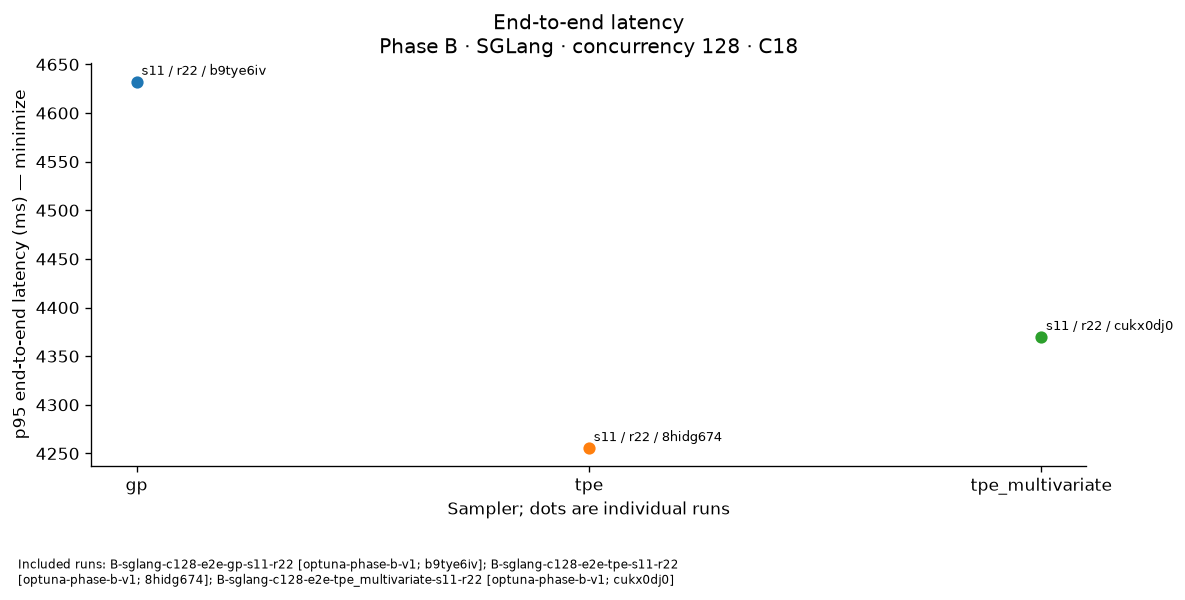

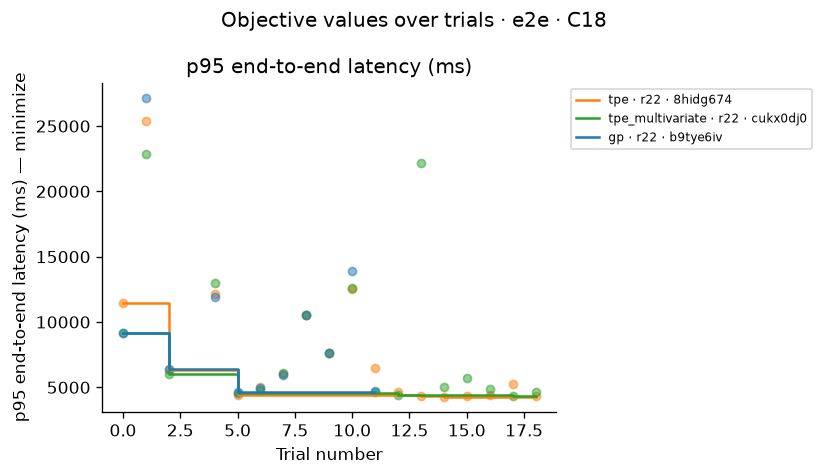

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
24,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,1,max_running_requests,0.373825
25,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_prefill_tokens,0.252513
26,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,3,schedule_conservativeness,0.180290
27,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,4,mem_fraction_static,0.065219
28,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,5,chunked_prefill_size,0.053042
29,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,6,enable_mixed_chunk,0.049896
30,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,7,disable_radix_cache,0.009640
31,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,8,cuda_graph_backend_decode,0.006238
32,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,9,schedule_policy,0.005986
33,B-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,10,disable_overlap_schedule,0.003124


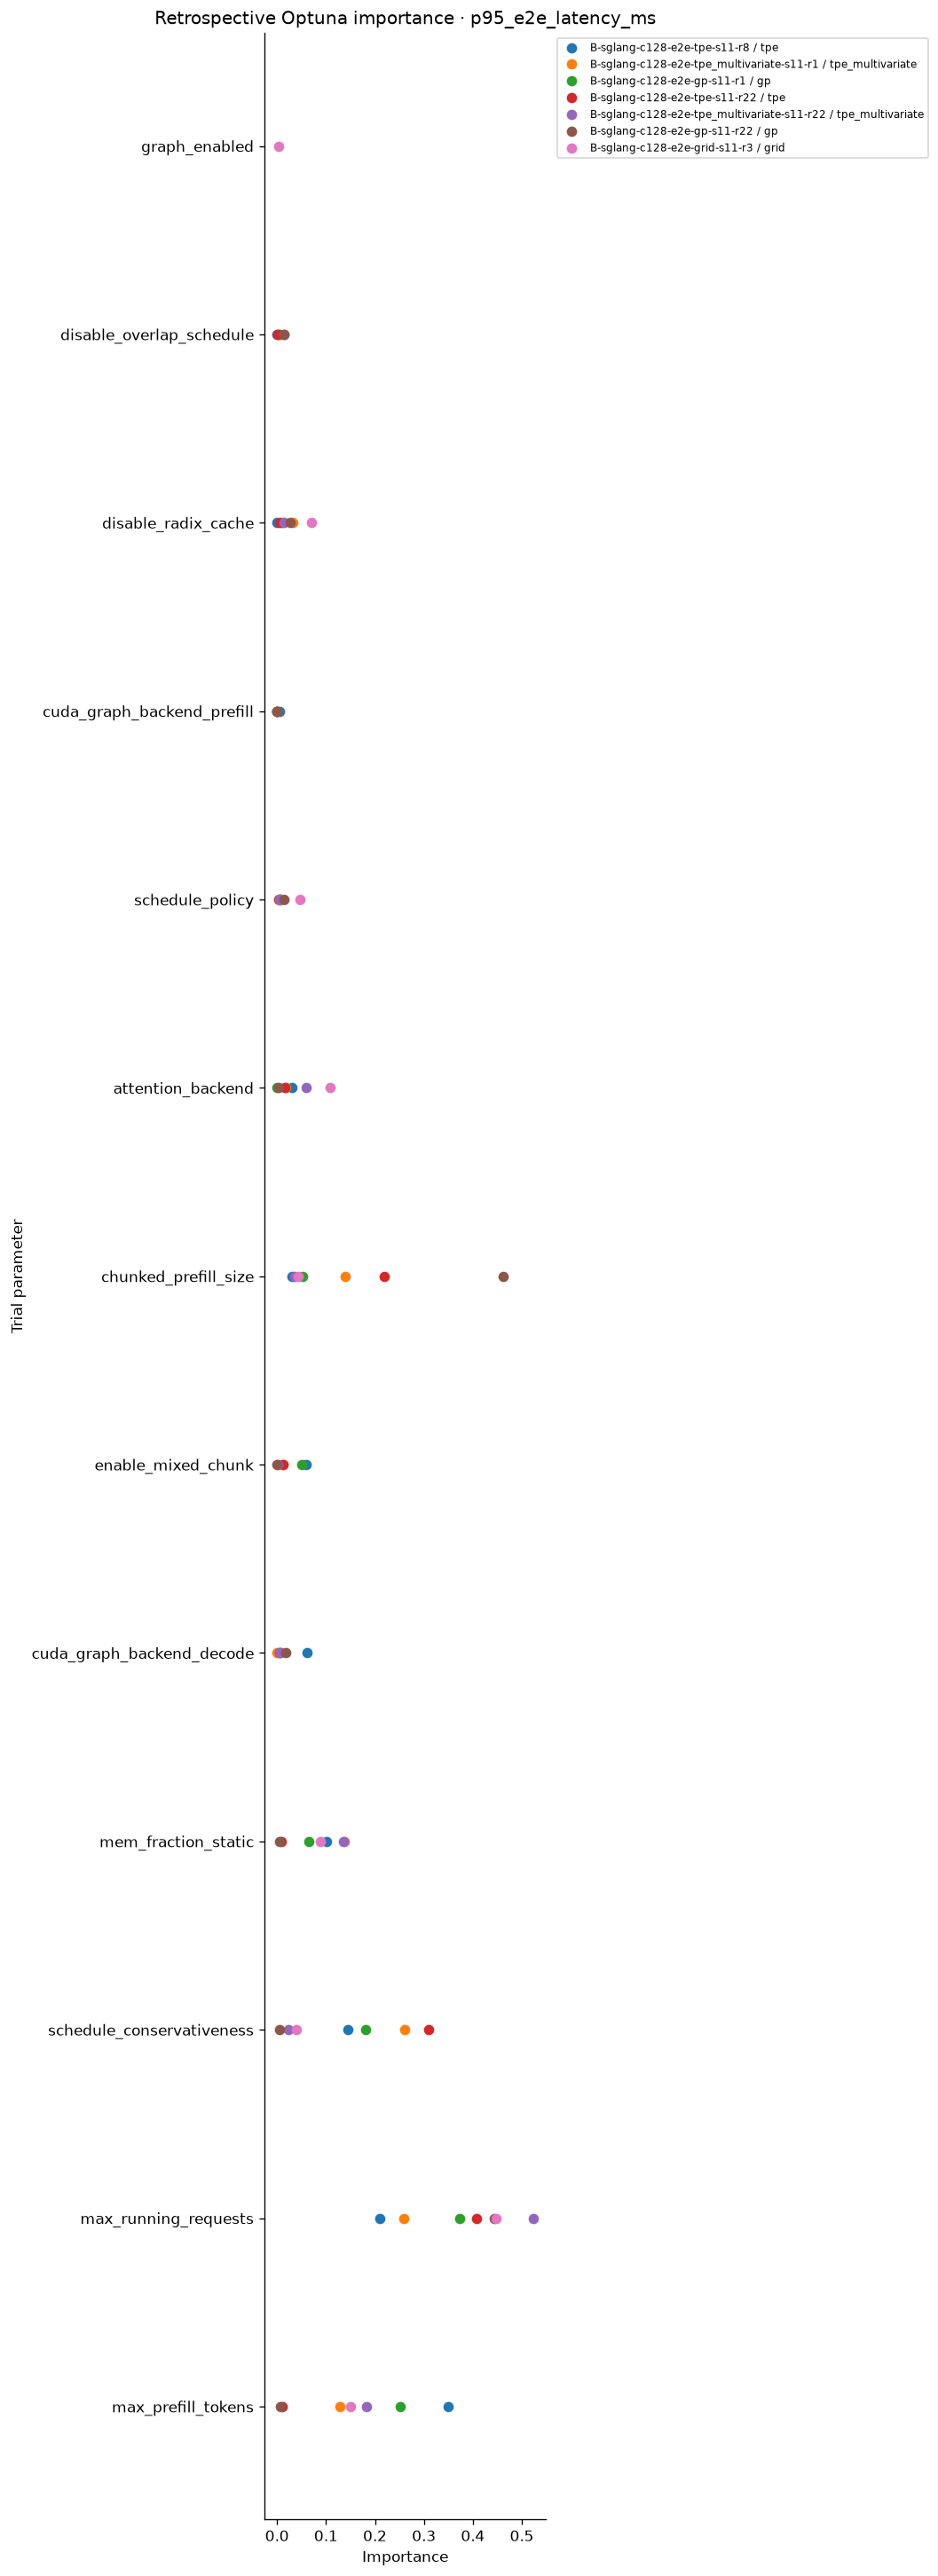

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r21, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-gp-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r3`
- `B-sglang-c128-throughput-tpe-s11-r21`
- `B-sglang-c128-throughput-tpe-s11-r3`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-sglang-c128-throughput-tpe-s11-r3,optuna-phase-b-v1,h313kk2n,throughput,C11,tpe,40.90,attention_backend: tritonchunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,13,3861.071881,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r3,optuna-phase-b-v1,l654dzh5,throughput,C11,tpe_multivariate,40.74,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,3851.183121,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-r3,optuna-phase-b-v1,4n071923,throughput,C11,gp,34.19,attention_backend: fa3chunked_prefill_size: 6144cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: lpm,12,3860.950269,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r21,optuna-phase-b-v1,tz0bzitz,throughput,C12,tpe,34.40,attention_backend: tritonchunked_prefill_size: 32512cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: fcfs,13,6323.834874,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r21,optuna-phase-b-v1,tvgcy76k,throughput,C12,tpe_multivariate,33.54,attention_backend: fa3chunked_prefill_size: 21248cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 120mem_fraction_static: 0.75schedule_conservativeness: 1.0schedule_policy: fcfs,15,6261.418054,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-r21,optuna-phase-b-v1,97y1fl5s,throughput,C12,gp,28.74,attention_backend: fa3chunked_prefill_size: 19712cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: fcfs,11,6243.542049,False,all local COMPLETE trials


##### Matching context C11

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

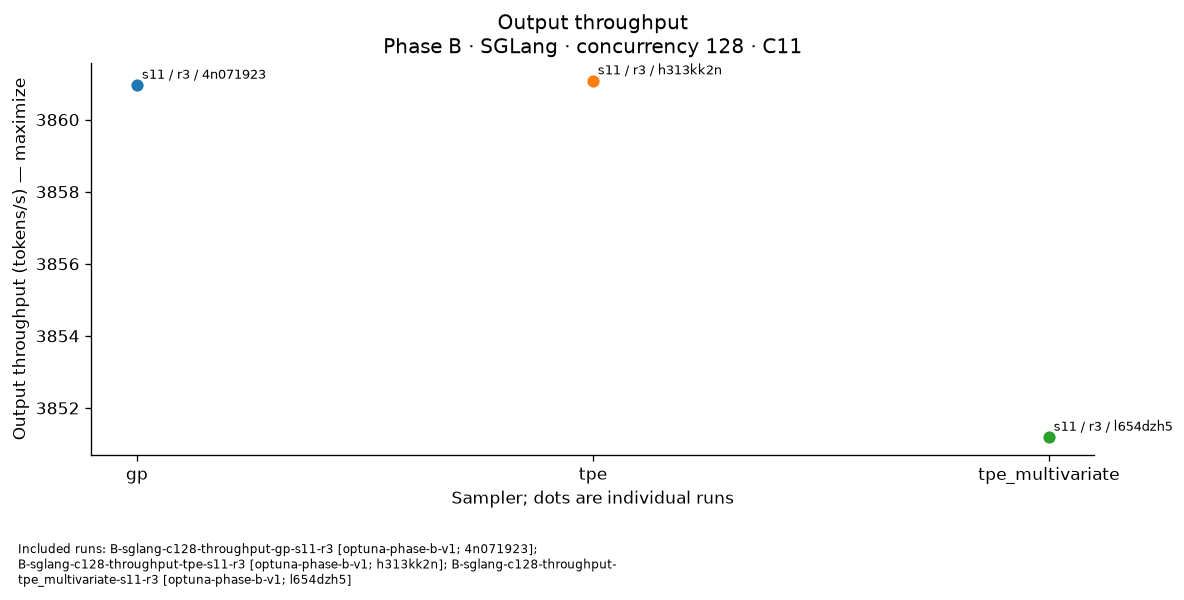

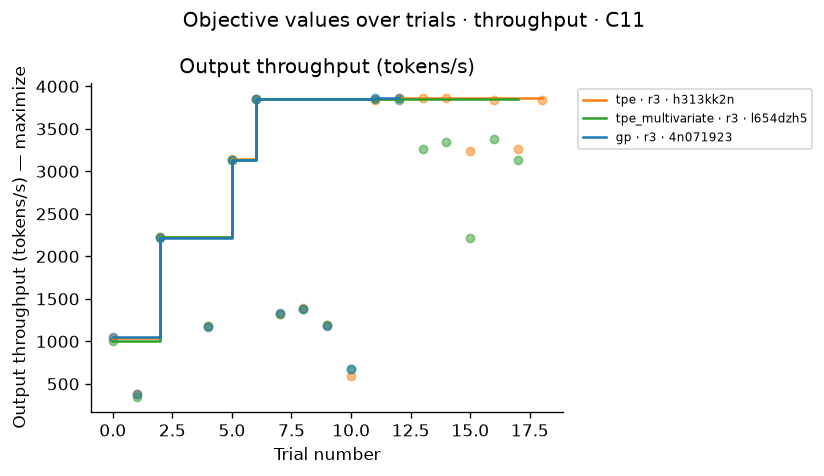

##### Matching context C12

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

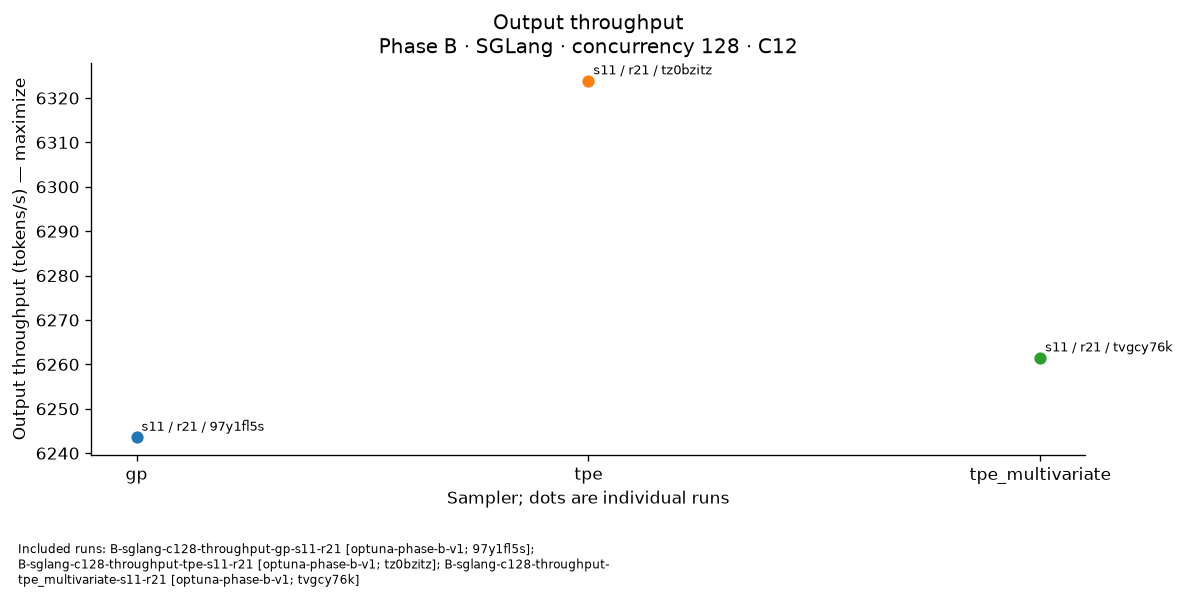

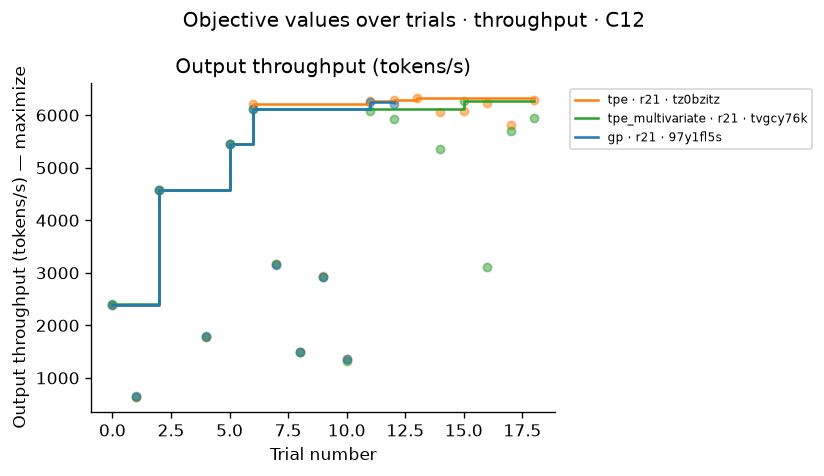

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
60,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,1,max_running_requests,0.539257
61,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,2,chunked_prefill_size,0.245471
62,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,3,schedule_conservativeness,0.141519
63,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,4,max_prefill_tokens,0.038864
64,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,5,enable_mixed_chunk,0.008781
65,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,6,disable_radix_cache,0.008781
66,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,7,attention_backend,0.005991
67,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,8,disable_overlap_schedule,0.004631
68,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,9,schedule_policy,0.004391
69,B-sglang-c128-throughput-gp-s11-r21,gp,output_throughput,10,mem_fraction_static,0.001404


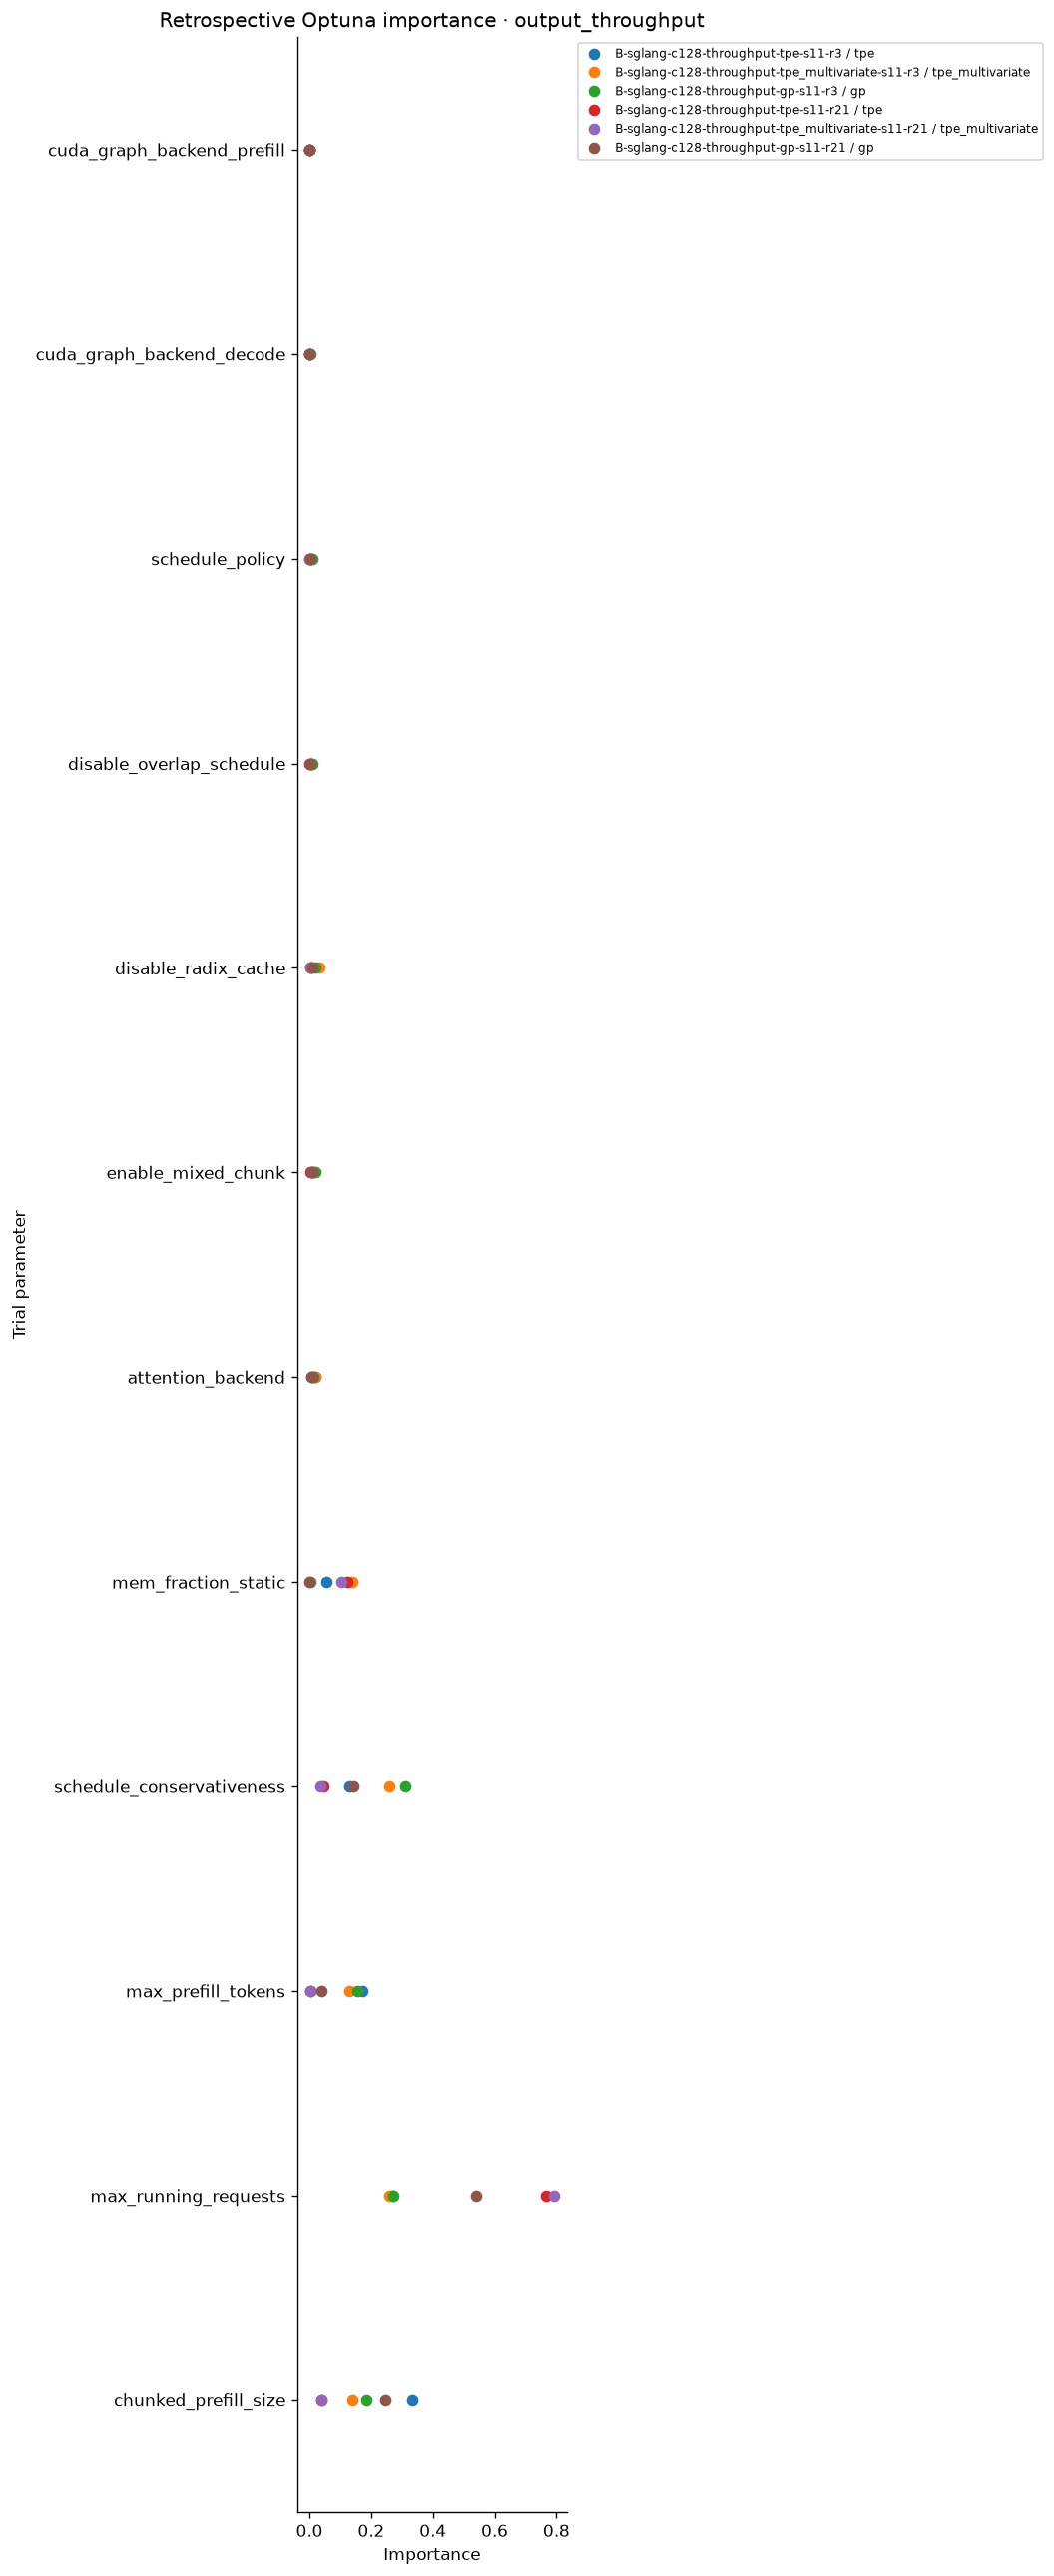

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 8.** Optimizer seeds: s11. Repeats: r1, r21.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-pareto_throughput-gp-s11-r1`
- `B-sglang-c128-pareto_throughput-gp-s11-r21`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r1`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r21`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,i0vlp43e,pareto_throughput,C07,tpe,41.84,attention_backend: tritonchunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: fcfs,12,3859.633514,5366.787615,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,qj630sqc,pareto_throughput,C07,tpe_multivariate,40.13,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: fcfs,12,3851.938033,5365.730979,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,ugshe19v,pareto_throughput,C07,gp,40.88,attention_backend: tritonchunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: fcfs,17,3860.544160,5377.993359,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,ugshe19v,pareto_throughput,C07,gp,40.88,attention_backend: fa3chunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: fcfs,18,3878.047210,5384.490891,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,h2m48aoo,pareto_throughput,C07,nsga2,45.25,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,3846.076633,5432.923475,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-tpe-s11-r21,optuna-phase-b-v1,6j9jv683,pareto_throughput,C08,tpe,33.99,attention_backend: tritonchunked_prefill_size: 30976cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: lpm,12,6320.867922,5050.372058,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-tpe-s11-r21,optuna-phase-b-v1,6j9jv683,pareto_throughput,C08,tpe,33.99,attention_backend: tritonchunked_prefill_size: 31488cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 96mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: lpm,13,5954.547801,4678.644679,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-tpe-s11-r21,optuna-phase-b-v1,6j9jv683,pareto_throughput,C08,tpe,33.99,attention_backend: tritonchunked_prefill_size: 32512cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 104mem_fraction_static: 0.75s

##### Matching context C07

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

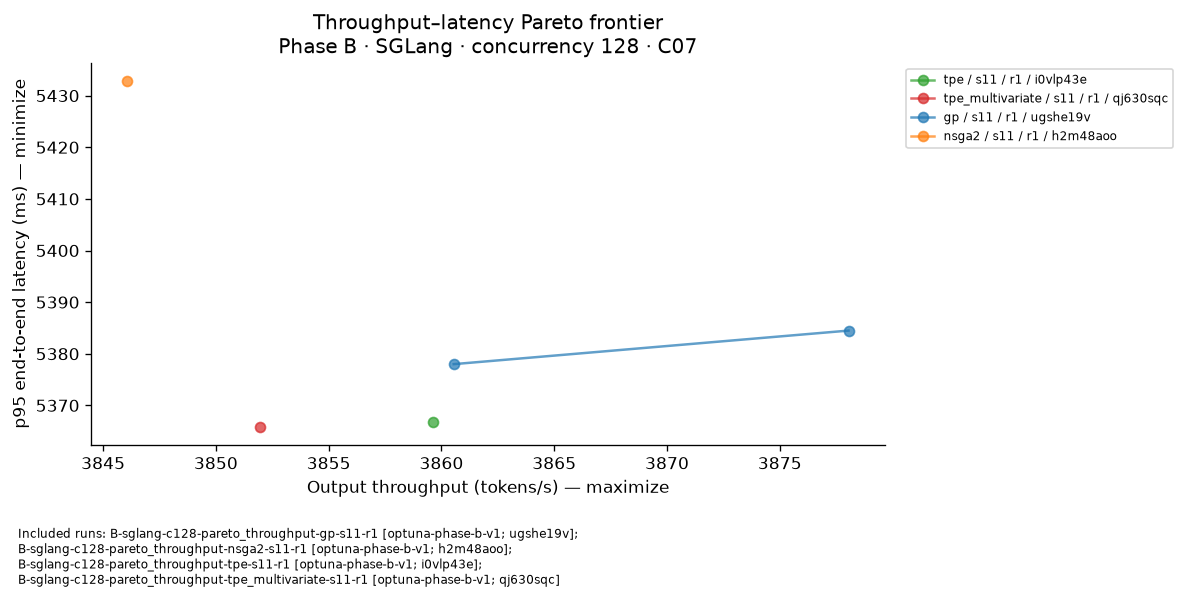

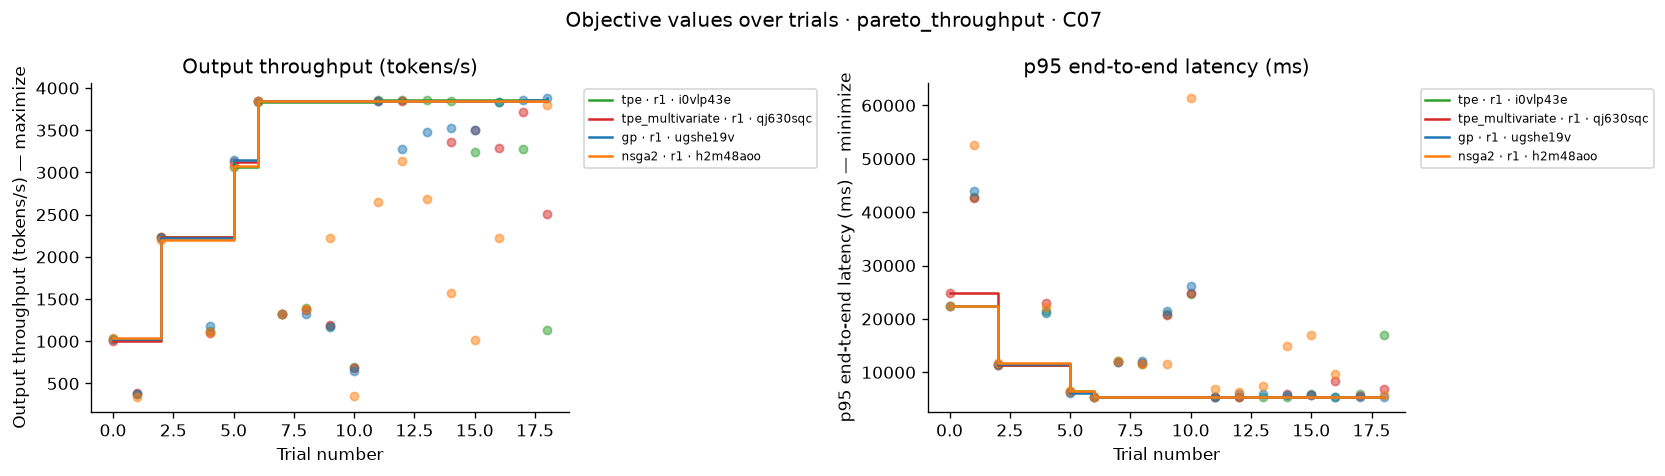

##### Matching context C08

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-4B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

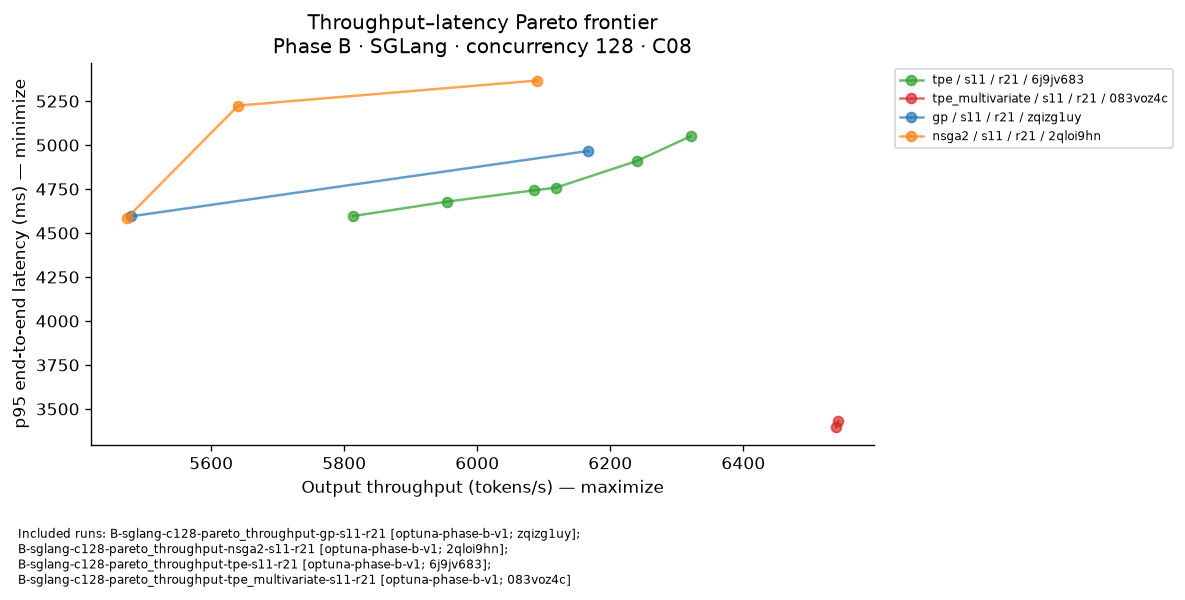

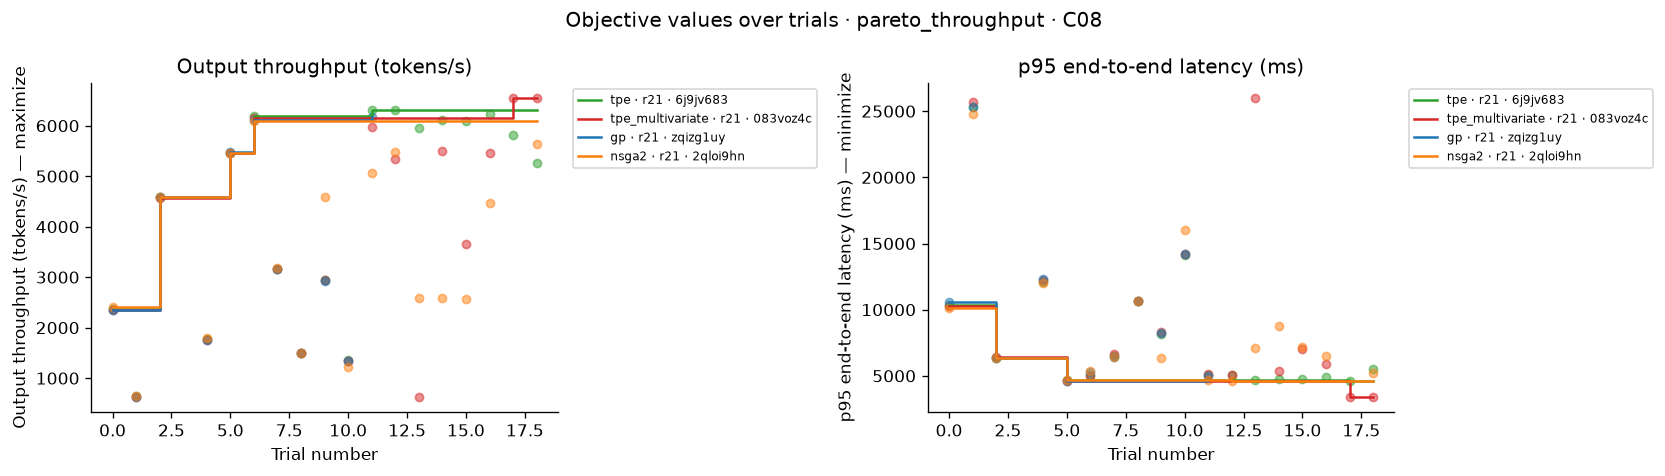

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
48,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,1,chunked_prefill_size,0.440620
49,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,2,mem_fraction_static,0.263962
50,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,3,max_running_requests,0.130995
51,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,4,max_prefill_tokens,0.107178
52,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,5,attention_backend,0.037128
53,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,6,enable_mixed_chunk,0.008446
54,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,7,disable_radix_cache,0.004163
55,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,8,schedule_policy,0.002585
56,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,9,schedule_conservativeness,0.002291
57,B-sglang-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,10,disable_overlap_schedule,0.001349


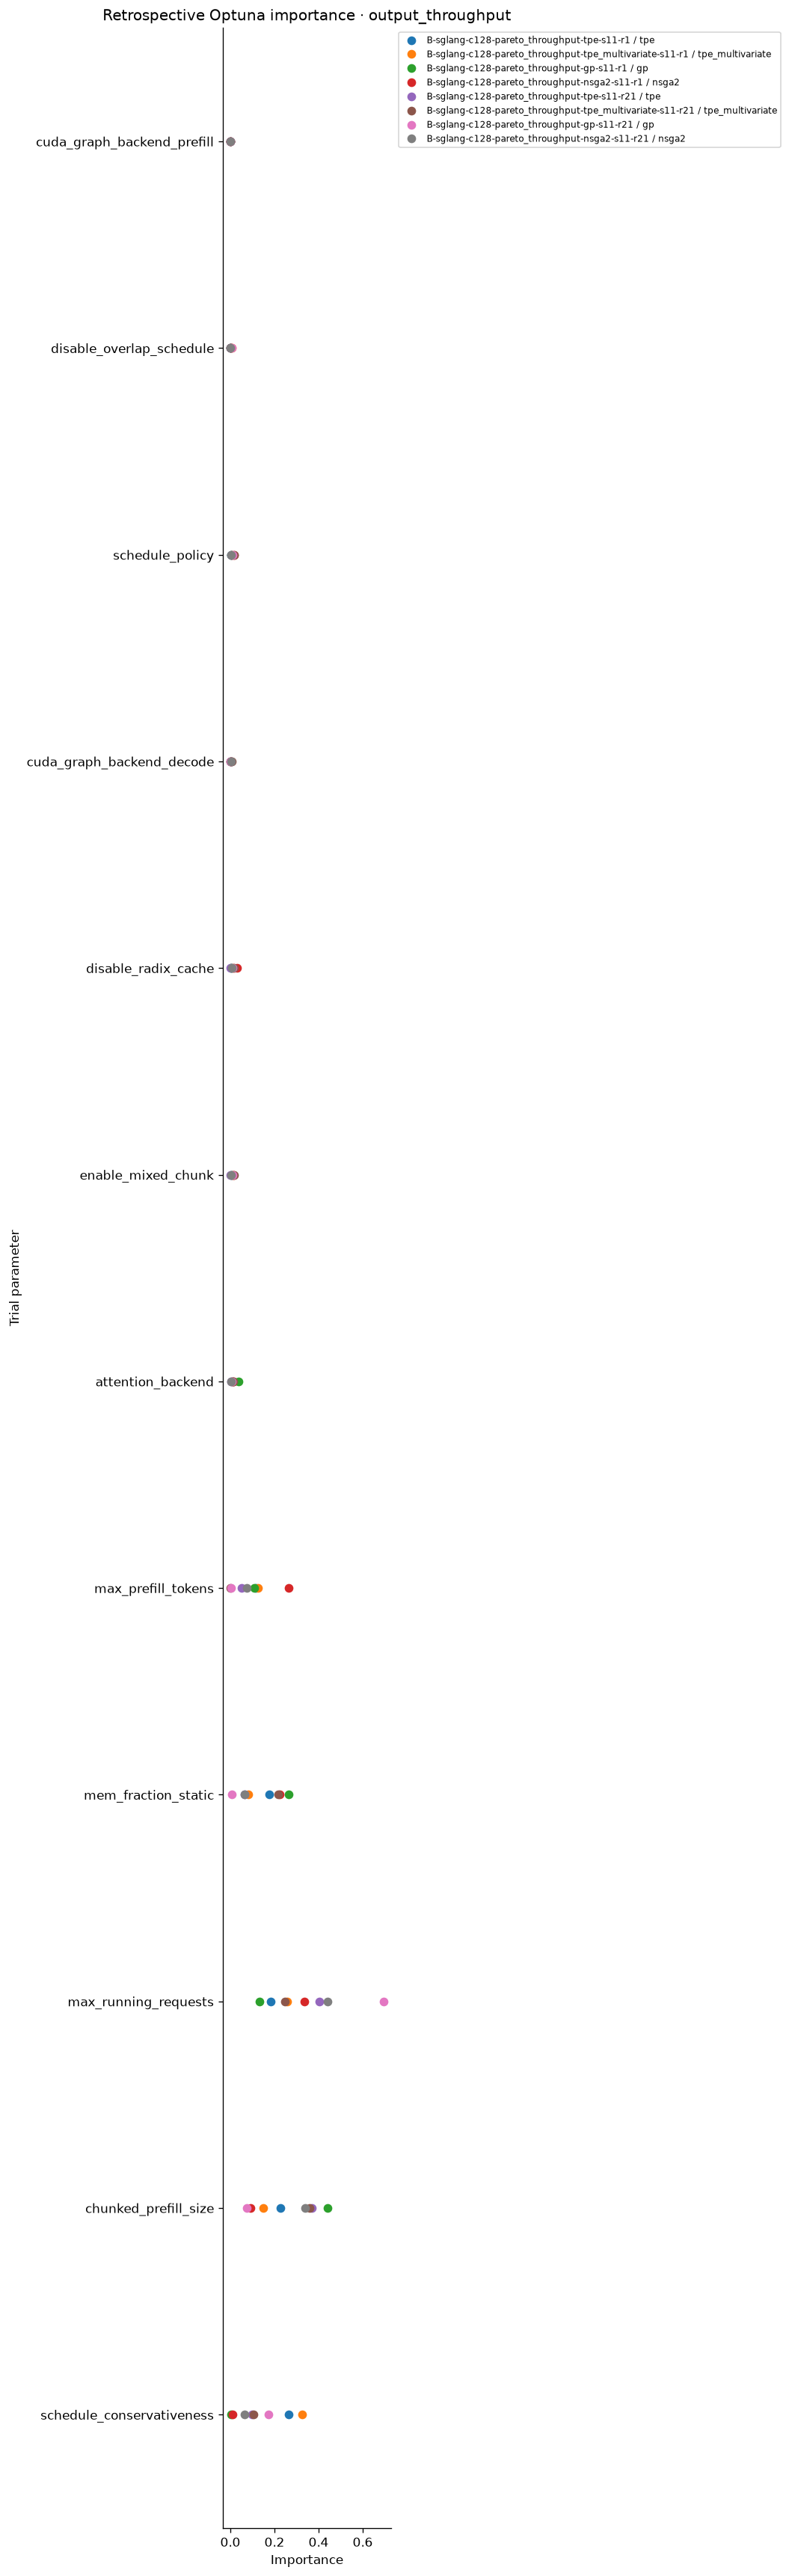

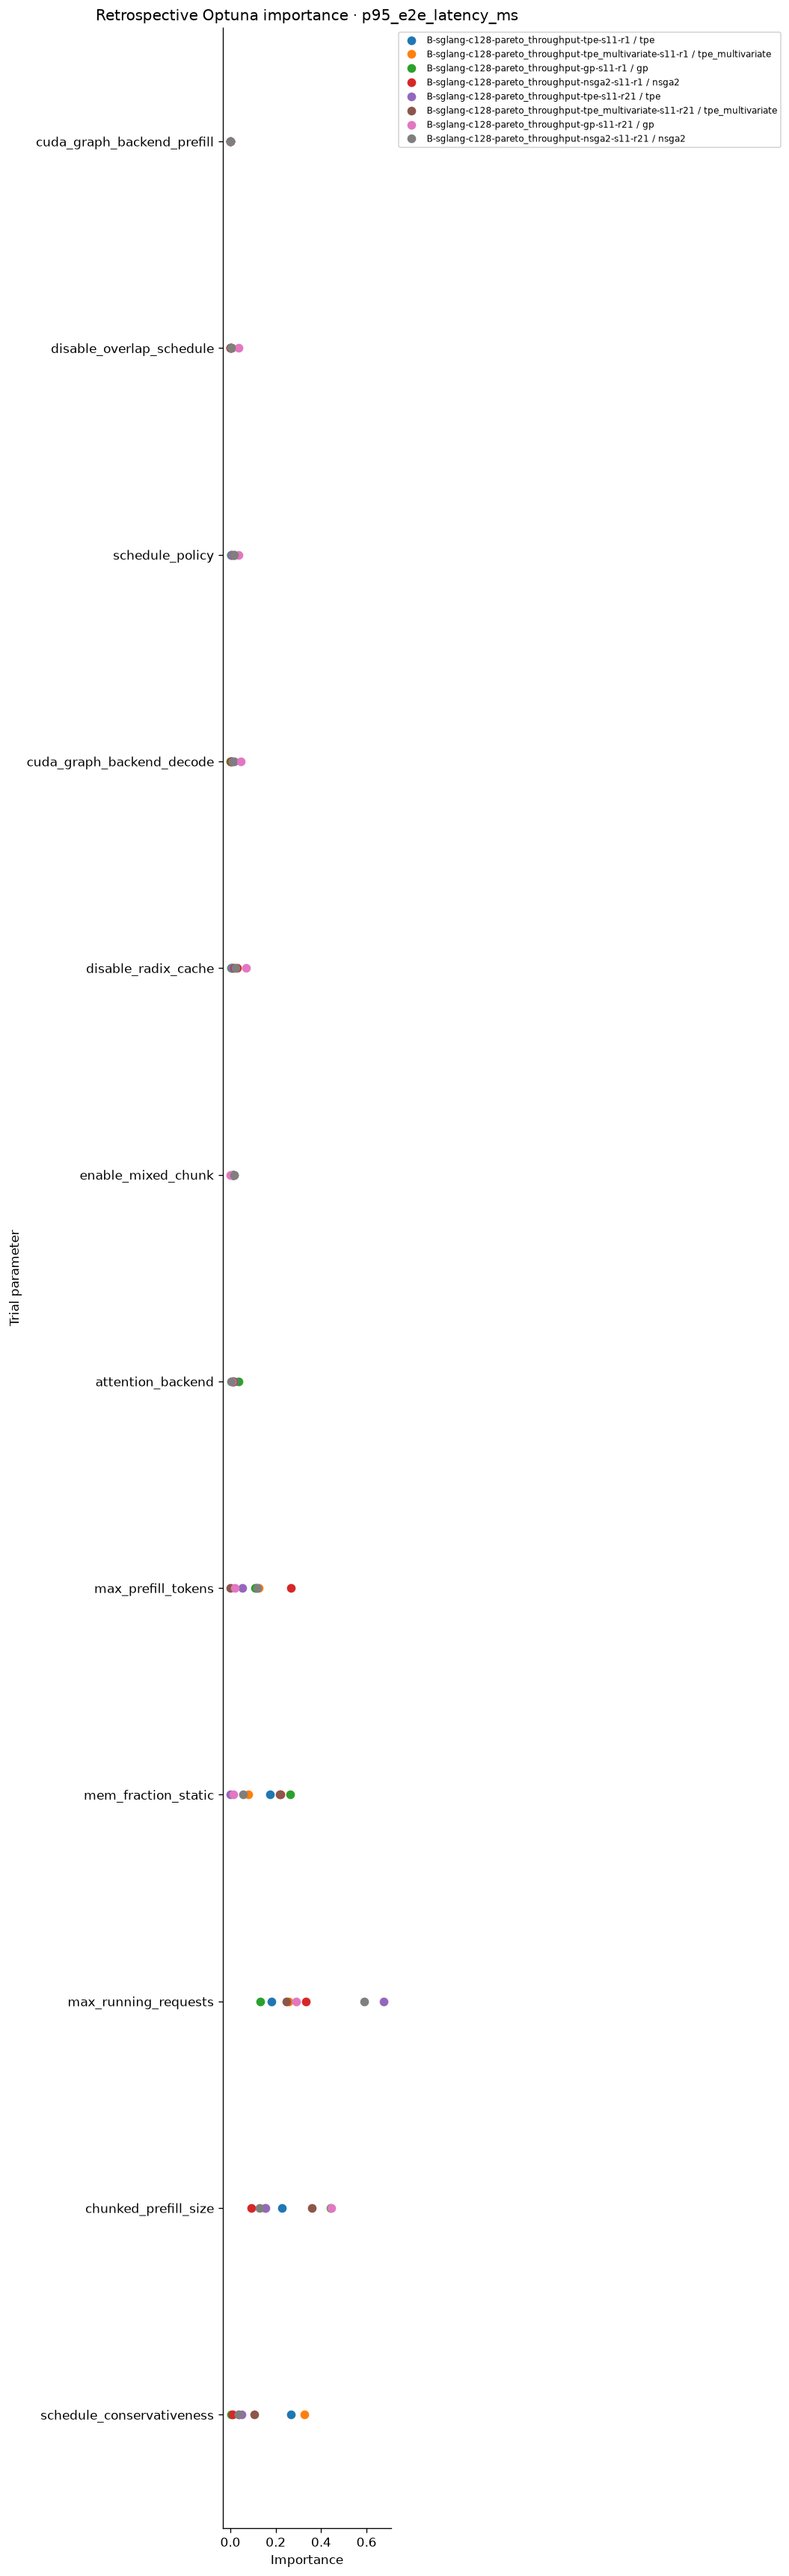

In [28]:
show_framework("B", "sglang")

## Phase A

Each framework has its own run list, metadata and objective-specific results. Compare samplers and repeats only within the matching context. Scalar plots show per-run best values; Pareto plots preserve paired trial values and configurations. Missing results, different search budgets and recorded environment placeholders limit comparisons. Search results are not independently validated recommendations.

### vLLM

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Early Phase A vLLM latency inventory

In [29]:
show_early_vllm_latency()

#### Phase A vLLM: early and first-repeat latency runs

Original groups and W&B IDs distinguish runs sharing an `r1` study name. The earliest concurrency-128 E2E group is `optuna-inference-lab-idcgg3zn`; `optuna-inference-lab-p0lfaev2` contains later same-name repeats. These rows use the same five-minute inclusion rule and remain in the objective sections below; they are not counted twice.

**Recorded best / Pareto results for these r1 runs**

Remote-only entries are W&B candidate summaries; local entries use completed SQLite trials. Compare within the listed matching context, not across workloads.

,run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source,p95_ttft_ms
3,A-vllm-c1-e2e-grid-s11-r1,optuna-inference-lab-ct_91ft_,5nei8053,e2e,C01,grid,5.86,<b>cuda_graph_on</b>: 1<br><b>max_num_batched_tokens</b>: 1024,0,324.783551,True,all local COMPLETE trials,NaN
9,A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-idcgg3zn / gz1r6mo8],optuna-inference-lab-idcgg3zn,gz1r6mo8,e2e,C24,gp,12.59,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,5,2251.113067,False,W&B candidate summary only,NaN
4,A-vllm-c128-e2e-grid-s11-r1,optuna-inference-lab-idcgg3zn,10bj2xwx,e2e,C24,grid,93.80,<b>gpu_memory_utilization</b>: 0.9<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,25,2239.116174,False,W&B candidate summary only,NaN
6,A-vllm-c128-e2e-qmc-s11-r1,optuna-inference-lab-idcgg3zn,ohwjiiyv,e2e,C24,qmc,12.62,<b>gpu_memory_utilization</b>: 0.8<br><b>max_num_batched_tokens</b>: 6144<br><b>max_num_seqs</b>: 32,2,2311.201523,False,W&B candidate summary only,NaN
5,A-vllm-c128-e2e-random-s11-r1,optuna-inference-lab-idcgg3zn,ksgwxqzo,e2e,C24,random,12.50,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,5,2292.550333,False,W&B candidate summary only,NaN
7,A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-idcgg3zn / aarrc9iq],optuna-inference-lab-idcgg3zn,aarrc9iq,e2e,C24,tpe,12.58,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,5,2268.280409,False,W&B candidate summary only,NaN
8,A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-idcgg3zn / yvfxh5yx],optuna-inference-lab-idcgg3zn,yvfxh5yx,e2e,C24,tpe_multivariate,12.59,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,5,2251.856940,False,W&B candidate summary only,NaN
2,A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-p0lfaev2 / ipqq6aa3],optuna-inference-lab-p0lfaev2,ipqq6aa3,e2e,C25,gp,39.43,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 6144<br><b>max_num_seqs</b>: 32,4,2061.378252,False,all local COMPLETE trials,NaN
0,A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-p0lfaev2 / frli9q3o],optuna-inference-lab-p0lfaev2,frli9q3o,e2e,C25,tpe,43.62,<b>gpu_memory_utilization</b>: 0.8<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,15,2007.965752,False,all local COMPLETE trials,NaN
1,A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-p0lfaev2 / 2wg9v2w7],optuna-inference-lab-p0lfaev2,2wg9v2w7,e2e,C25,tpe_multivariate,40.44,<b>gpu_memory_utilization</b>: 0.75<br><b>max_num_batched_tokens</b>: 8192<br><b>max_num_seqs</b>: 32,5,2097.456085,False,all local COMPLETE trials,NaN


#### Phase A {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase A / vLLM: 29 included runs; cutoff 5 minutes


**Runs included: 26.** Optimizer seeds: s11. Repeats: r1, r2.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-e2e-gp-s11-r2`
- `A-vllm-c1-e2e-grid-s11-r1`
- `A-vllm-c1-e2e-grid-s11-r2`
- `A-vllm-c1-e2e-qmc-s11-r2`
- `A-vllm-c1-e2e-random-s11-r2`
- `A-vllm-c1-e2e-tpe-s11-r2`
- `A-vllm-c1-e2e-tpe_multivariate-s11-r2`
- `A-vllm-c1-ttft-gp-s11-r1`
- `A-vllm-c1-ttft-grid-s11-r1`
- `A-vllm-c1-ttft-qmc-s11-r1`
- `A-vllm-c1-ttft-random-s11-r1`
- `A-vllm-c1-ttft-tpe-s11-r1`
- `A-vllm-c1-ttft-tpe_multivariate-s11-r1`
- `A-vllm-c128-e2e-gp-s11-r1`
- `A-vllm-c128-e2e-grid-s11-r1`
- `A-vllm-c128-e2e-qmc-s11-r1`
- `A-vllm-c128-e2e-random-s11-r1`
- `A-vllm-c128-e2e-tpe-s11-r1`
- `A-vllm-c128-e2e-tpe_multivariate-s11-r1`
- `A-vllm-c128-pareto_throughput-gp-s11-r1`
- `A-vllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `A-vllm-c128-throughput-gp-s11-r1`
- `A-vllm-c128-throughput-tpe-s11-r1`
- `A-vllm-c128-throughput-tpe_multivariate-s11-r1`

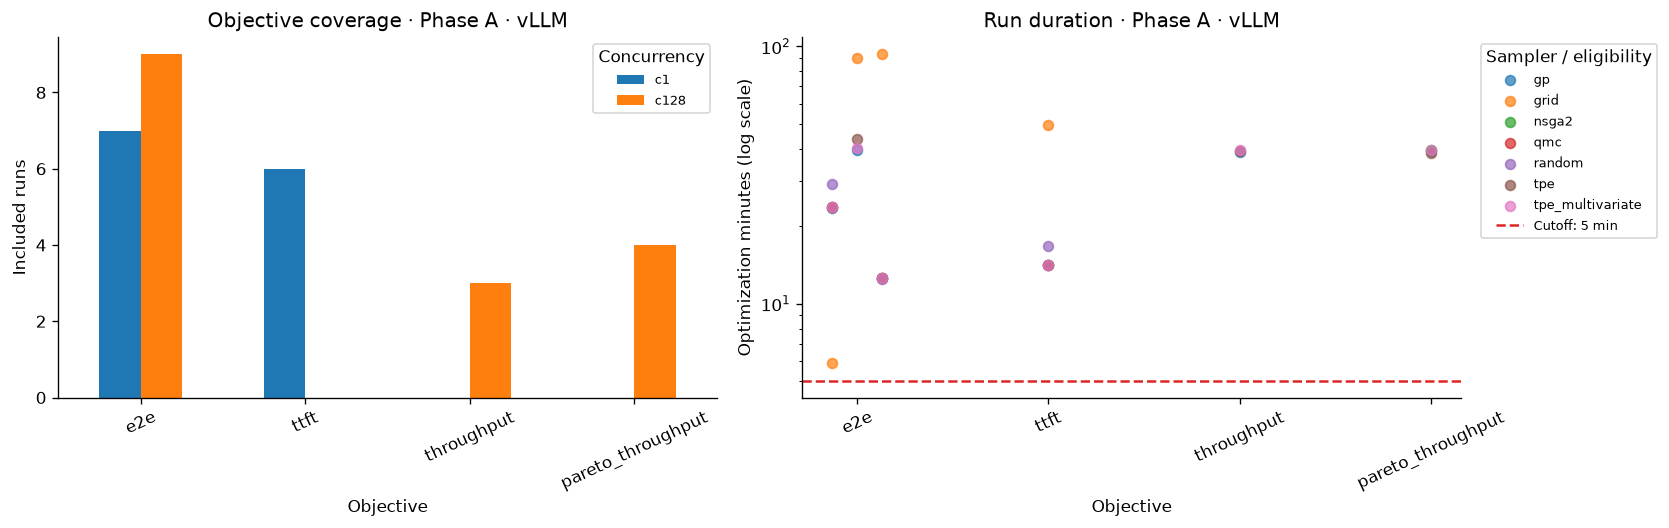

,state,trials
0,COMPLETE,488
1,FAIL,1
2,RUNNING,1


Runs without recorded outcome counts: 0


#### Concurrency 1 · Phase A · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 7.** Optimizer seeds: s11. Repeats: r1, r2.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-e2e-gp-s11-r2`
- `A-vllm-c1-e2e-grid-s11-r1`
- `A-vllm-c1-e2e-grid-s11-r2`
- `A-vllm-c1-e2e-qmc-s11-r2`
- `A-vllm-c1-e2e-random-s11-r2`
- `A-vllm-c1-e2e-tpe-s11-r2`
- `A-vllm-c1-e2e-tpe_multivariate-s11-r2`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c1-e2e-grid-s11-r2,optuna-inference-lab-k59lf6t5,jhp575i2,e2e,C01,grid,89.84,cuda_graph_on: 1max_num_batched_tokens: 1024,0,318.423983,True,all local COMPLETE trials
A-vllm-c1-e2e-random-s11-r2,optuna-inference-lab-k59lf6t5,ox1v6gg2,e2e,C01,random,29.23,cuda_graph_on: 1max_num_batched_tokens: 5120,0,323.455537,True,all local COMPLETE trials
A-vllm-c1-e2e-qmc-s11-r2,optuna-inference-lab-k59lf6t5,jiam85ja,e2e,C01,qmc,23.78,cuda_graph_on: 1max_num_batched_tokens: 5120,0,324.887006,True,all local COMPLETE trials
A-vllm-c1-e2e-tpe-s11-r2,optuna-inference-lab-k59lf6t5,o8lrmftt,e2e,C01,tpe,23.81,cuda_graph_on: 1max_num_batched_tokens: 8192,4,321.652873,True,all local COMPLETE trials
A-vllm-c1-e2e-tpe_multivariate-s11-r2,optuna-inference-lab-k59lf6t5,d9w96v9e,e2e,C01,tpe_multivariate,23.80,cuda_graph_on: 1max_num_batched_tokens: 5120,0,319.413708,True,all local COMPLETE trials
A-vllm-c1-e2e-grid-s11-r1,optuna-inference-lab-ct_91ft_,5nei8053,e2e,C01,grid,5.86,cuda_graph_on: 1max_num_batched_tokens: 1024,0,324.783551,True,all local COMPLETE trials
A-vllm-c1-e2e-gp-s11-r2,optuna-inference-lab-k59lf6t5,opn2e3xt,e2e,C01,gp,23.63,cuda_graph_on: 1max_num_batched_tokens: 5120,0,318.072937,True,all local COMPLETE trials


##### Matching context C01

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 256, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

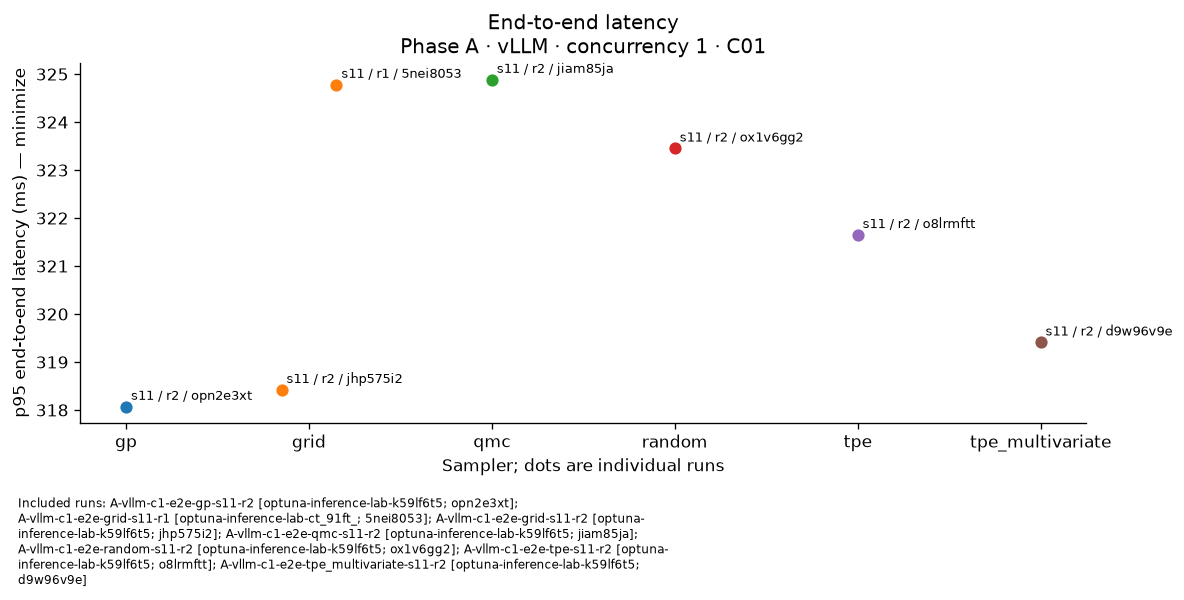

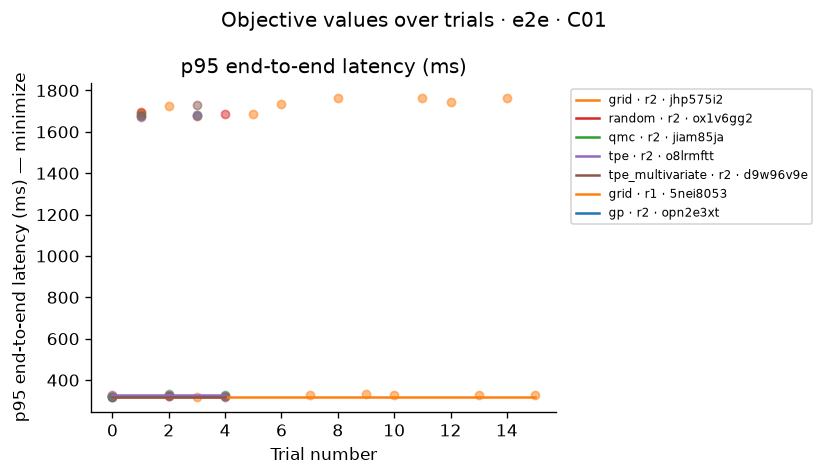

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
0,A-vllm-c1-e2e-grid-s11-r2,grid,p95_e2e_latency_ms,1,max_num_batched_tokens,0.545483
1,A-vllm-c1-e2e-grid-s11-r2,grid,p95_e2e_latency_ms,2,cuda_graph_on,0.454517
4,A-vllm-c1-e2e-qmc-s11-r2,qmc,p95_e2e_latency_ms,1,cuda_graph_on,0.876651
5,A-vllm-c1-e2e-qmc-s11-r2,qmc,p95_e2e_latency_ms,2,max_num_batched_tokens,0.123349
2,A-vllm-c1-e2e-random-s11-r2,random,p95_e2e_latency_ms,1,cuda_graph_on,0.555556
3,A-vllm-c1-e2e-random-s11-r2,random,p95_e2e_latency_ms,2,max_num_batched_tokens,0.444444
6,A-vllm-c1-e2e-tpe-s11-r2,tpe,p95_e2e_latency_ms,1,cuda_graph_on,0.543450
7,A-vllm-c1-e2e-tpe-s11-r2,tpe,p95_e2e_latency_ms,2,max_num_batched_tokens,0.456550
8,A-vllm-c1-e2e-tpe_multivariate-s11-r2,tpe_multivariate,p95_e2e_latency_ms,1,max_num_batched_tokens,0.543687
9,A-vllm-c1-e2e-tpe_multivariate-s11-r2,tpe_multivariate,p95_e2e_latency_ms,2,cuda_graph_on,0.456313


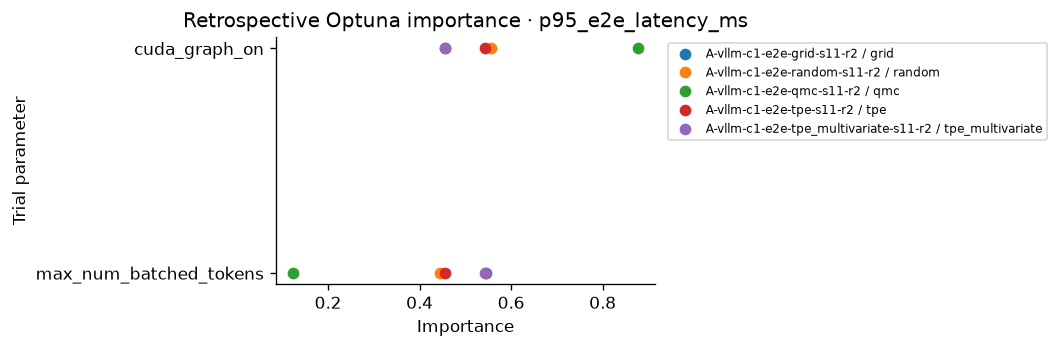

##### Time to first token (`ttft`)

Minimize p95 time to first token (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-ttft-gp-s11-r1`
- `A-vllm-c1-ttft-grid-s11-r1`
- `A-vllm-c1-ttft-qmc-s11-r1`
- `A-vllm-c1-ttft-random-s11-r1`
- `A-vllm-c1-ttft-tpe-s11-r1`
- `A-vllm-c1-ttft-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_ttft_ms,SLO feasible,result source
A-vllm-c1-ttft-grid-s11-r1,optuna-inference-lab-z7kb01i6,0ye31grd,ttft,C02,grid,49.65,cuda_graph_on: 1max_num_batched_tokens: 7168,7,32.987721,True,W&B candidate summary only
A-vllm-c1-ttft-random-s11-r1,optuna-inference-lab-z7kb01i6,c6tvli0k,ttft,C02,random,16.72,cuda_graph_on: 1max_num_batched_tokens: 5120,0,33.515670,True,W&B candidate summary only
A-vllm-c1-ttft-qmc-s11-r1,optuna-inference-lab-z7kb01i6,syas1k1d,ttft,C02,qmc,14.14,cuda_graph_on: 1max_num_batched_tokens: 5120,2,32.793124,True,W&B candidate summary only
A-vllm-c1-ttft-tpe-s11-r1,optuna-inference-lab-z7kb01i6,4yxy65wf,ttft,C02,tpe,14.17,cuda_graph_on: 1max_num_batched_tokens: 5120,0,33.217431,True,W&B candidate summary only
A-vllm-c1-ttft-tpe_multivariate-s11-r1,optuna-inference-lab-z7kb01i6,538umr4q,ttft,C02,tpe_multivariate,14.11,cuda_graph_on: 1max_num_batched_tokens: 4096,2,33.234949,True,W&B candidate summary only
A-vllm-c1-ttft-gp-s11-r1,optuna-inference-lab-z7kb01i6,rmowxrah,ttft,C02,gp,14.15,cuda_graph_on: 1max_num_batched_tokens: 8192,4,33.429065,True,W&B candidate summary only


##### Matching context C02

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 128, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

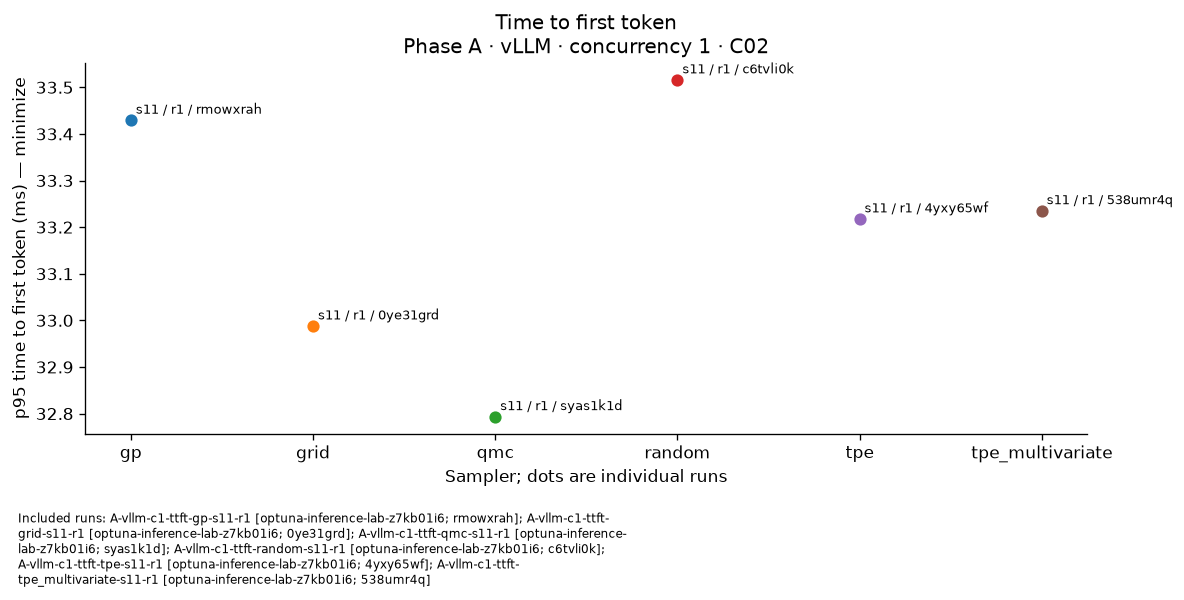

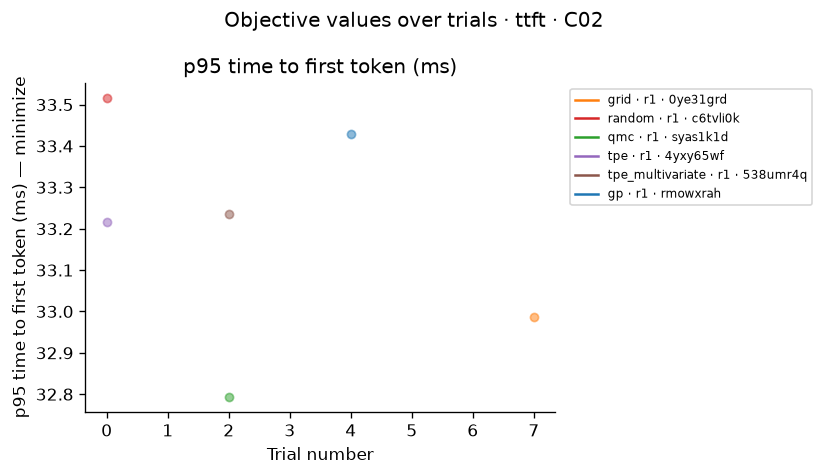

No local runs have enough varied completed trials for retrospective importance.
W&B summary-only runs do not contain trial histories for this calculation.


#### Concurrency 128 · Phase A · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-e2e-gp-s11-r1`
- `A-vllm-c128-e2e-grid-s11-r1`
- `A-vllm-c128-e2e-qmc-s11-r1`
- `A-vllm-c128-e2e-random-s11-r1`
- `A-vllm-c128-e2e-tpe-s11-r1`
- `A-vllm-c128-e2e-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-p0lfaev2 / frli9q3o],optuna-inference-lab-p0lfaev2,frli9q3o,e2e,C25,tpe,43.62,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,15,2007.965752,False,all local COMPLETE trials
A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-p0lfaev2 / 2wg9v2w7],optuna-inference-lab-p0lfaev2,2wg9v2w7,e2e,C25,tpe_multivariate,40.44,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2097.456085,False,all local COMPLETE trials
A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-p0lfaev2 / ipqq6aa3],optuna-inference-lab-p0lfaev2,ipqq6aa3,e2e,C25,gp,39.43,gpu_memory_utilization: 0.75max_num_batched_tokens: 6144max_num_seqs: 32,4,2061.378252,False,all local COMPLETE trials
A-vllm-c128-e2e-grid-s11-r1,optuna-inference-lab-idcgg3zn,10bj2xwx,e2e,C24,grid,93.80,gpu_memory_utilization: 0.9max_num_batched_tokens: 8192max_num_seqs: 32,25,2239.116174,False,W&B candidate summary only
A-vllm-c128-e2e-random-s11-r1,optuna-inference-lab-idcgg3zn,ksgwxqzo,e2e,C24,random,12.50,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2292.550333,False,W&B candidate summary only
A-vllm-c128-e2e-qmc-s11-r1,optuna-inference-lab-idcgg3zn,ohwjiiyv,e2e,C24,qmc,12.62,gpu_memory_utilization: 0.8max_num_batched_tokens: 6144max_num_seqs: 32,2,2311.201523,False,W&B candidate summary only
A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-idcgg3zn / aarrc9iq],optuna-inference-lab-idcgg3zn,aarrc9iq,e2e,C24,tpe,12.58,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2268.280409,False,W&B candidate summary only
A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-idcgg3zn / yvfxh5yx],optuna-inference-lab-idcgg3zn,yvfxh5yx,e2e,C24,tpe_multivariate,12.59,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2251.856940,False,W&B candidate summary only
A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-idcgg3zn / gz1r6mo8],optuna-inference-lab-idcgg3zn,gz1r6mo8,e2e,C24,gp,12.59,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2251.113067,False,W&B candidate summary only


##### Matching context C24

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

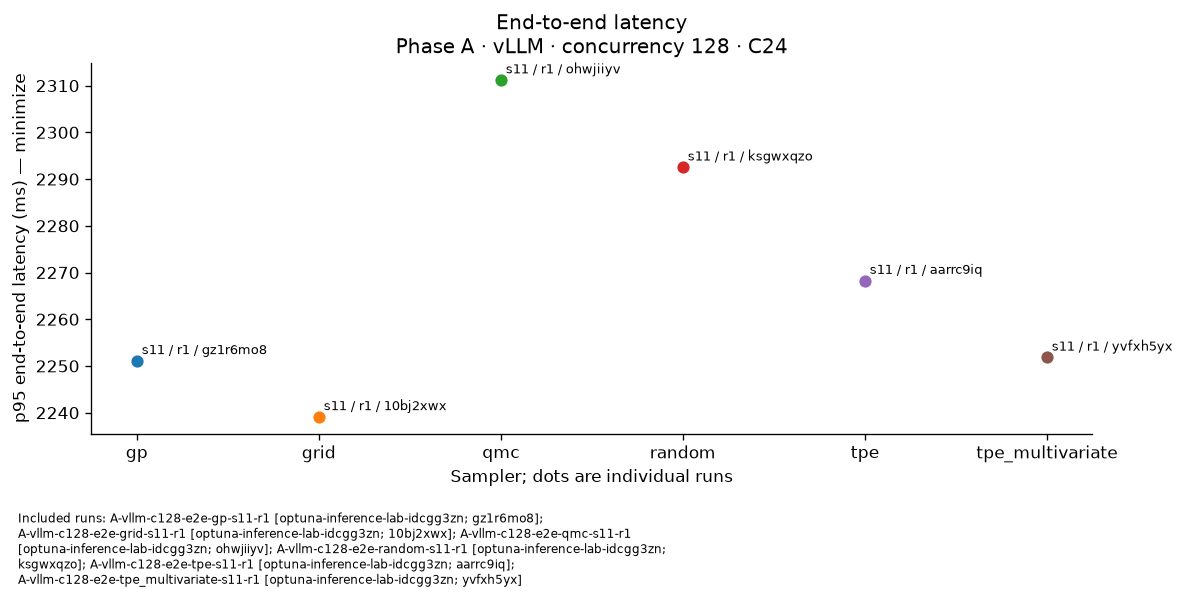

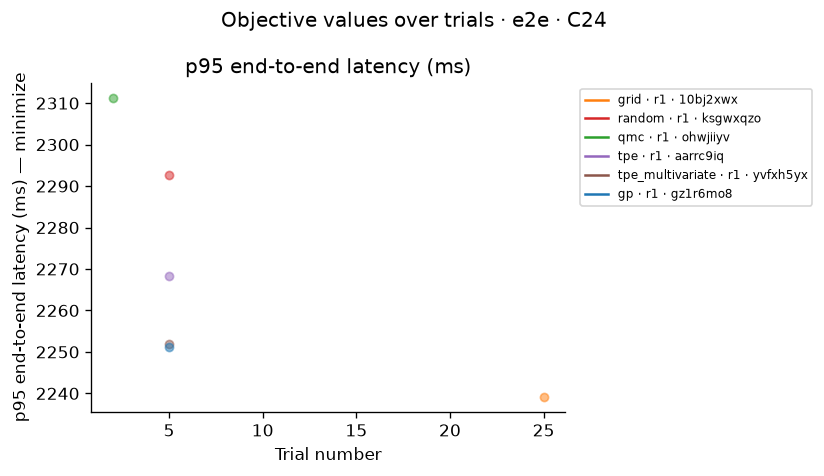

##### Matching context C25

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

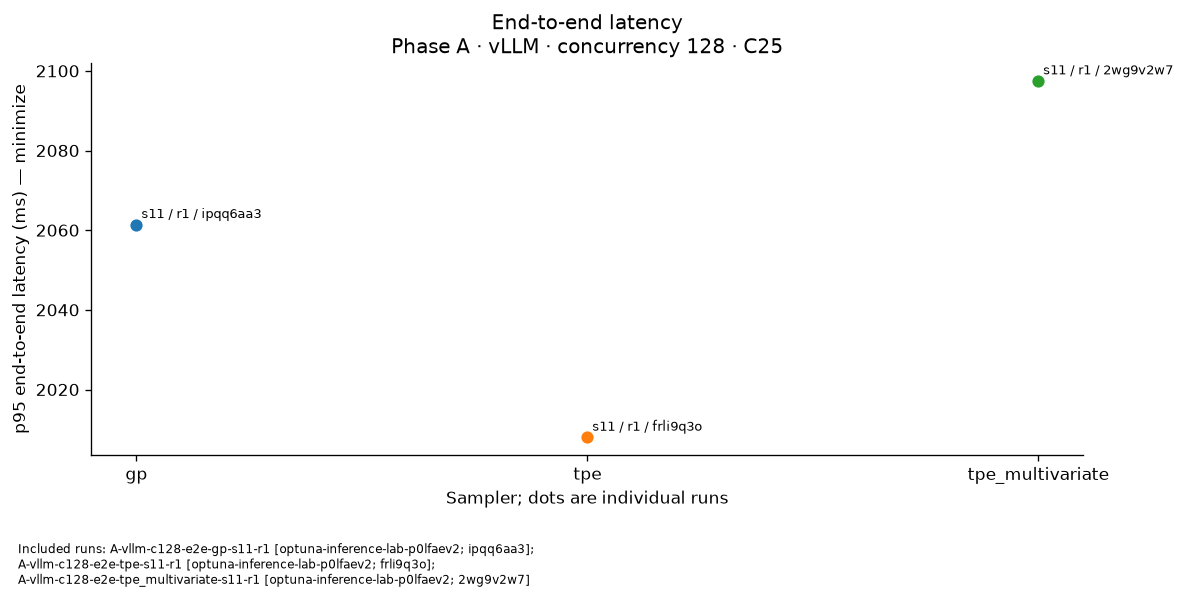

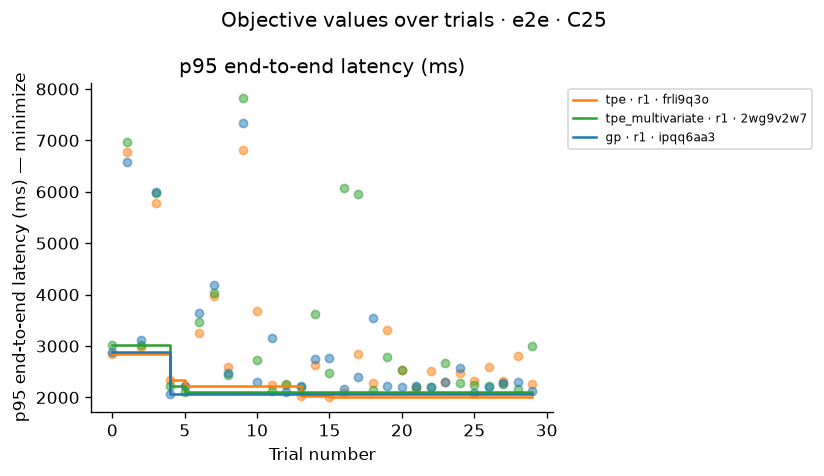

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
6,A-vllm-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,1,max_num_seqs,0.563967
7,A-vllm-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_num_batched_tokens,0.393718
8,A-vllm-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,3,gpu_memory_utilization,0.042315
0,A-vllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,1,max_num_seqs,0.610006
1,A-vllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,2,max_num_batched_tokens,0.241195
2,A-vllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,3,gpu_memory_utilization,0.148799
3,A-vllm-c128-e2e-tpe_multivariate-s11-r1,tpe_multivariate,p95_e2e_latency_ms,1,max_num_seqs,0.651929
4,A-vllm-c128-e2e-tpe_multivariate-s11-r1,tpe_multivariate,p95_e2e_latency_ms,2,gpu_memory_utilization,0.179908
5,A-vllm-c128-e2e-tpe_multivariate-s11-r1,tpe_multivariate,p95_e2e_latency_ms,3,max_num_batched_tokens,0.168163


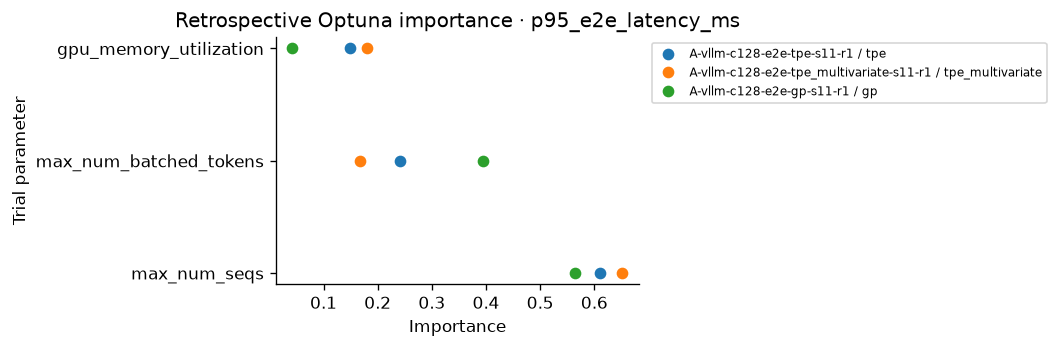

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-throughput-gp-s11-r1`
- `A-vllm-c128-throughput-tpe-s11-r1`
- `A-vllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
A-vllm-c128-throughput-tpe-s11-r1,optuna-inference-lab-p0lfaev2,ese3iqsy,throughput,C23,tpe,39.15,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,11,7998.110003,False,all local COMPLETE trials
A-vllm-c128-throughput-tpe_multivariate-s11-r1,optuna-inference-lab-p0lfaev2,fjff3da4,throughput,C23,tpe_multivariate,39.52,gpu_memory_utilization: 0.75max_num_batched_tokens: 6144max_num_seqs: 32,4,8033.775681,False,all local COMPLETE trials
A-vllm-c128-throughput-gp-s11-r1,optuna-inference-lab-p0lfaev2,fj4tc735,throughput,C23,gp,38.87,gpu_memory_utilization: 0.9max_num_batched_tokens: 8192max_num_seqs: 32,14,8052.185340,False,all local COMPLETE trials


##### Matching context C23

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

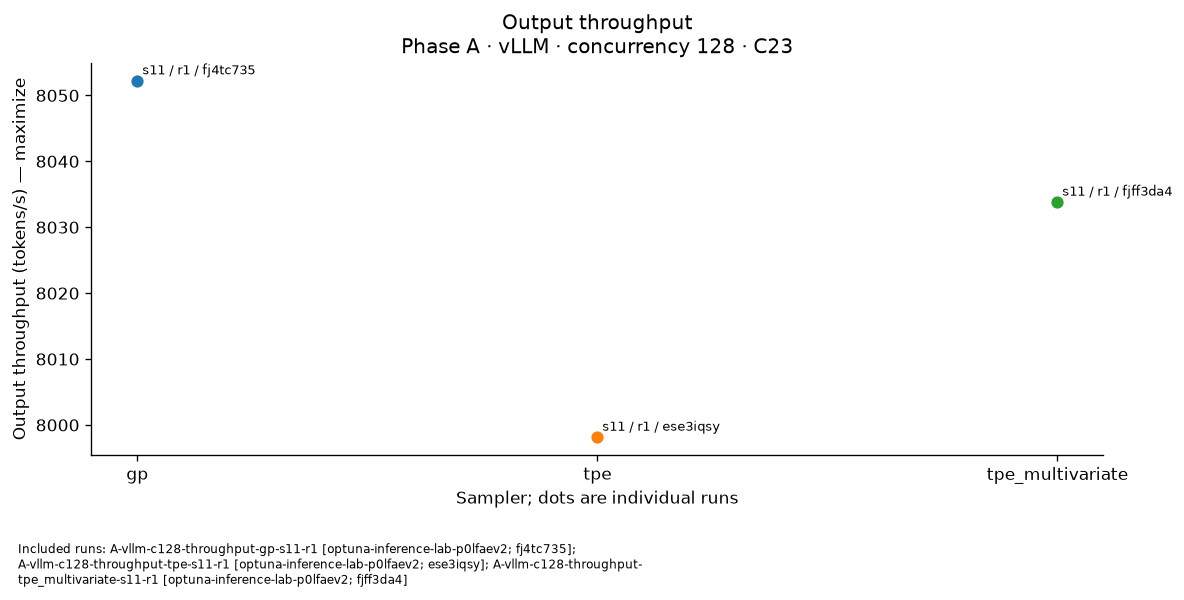

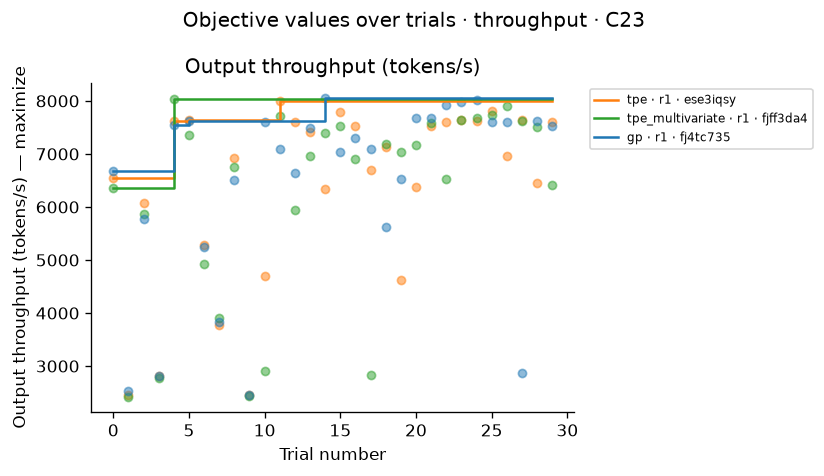

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
6,A-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,1,max_num_seqs,0.485110
7,A-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,2,max_num_batched_tokens,0.367353
8,A-vllm-c128-throughput-gp-s11-r1,gp,output_throughput,3,gpu_memory_utilization,0.147537
0,A-vllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,1,max_num_batched_tokens,0.559872
1,A-vllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,2,max_num_seqs,0.365110
2,A-vllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,3,gpu_memory_utilization,0.075018
3,A-vllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,1,max_num_batched_tokens,0.584763
4,A-vllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,2,max_num_seqs,0.237106
5,A-vllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,3,gpu_memory_utilization,0.178130


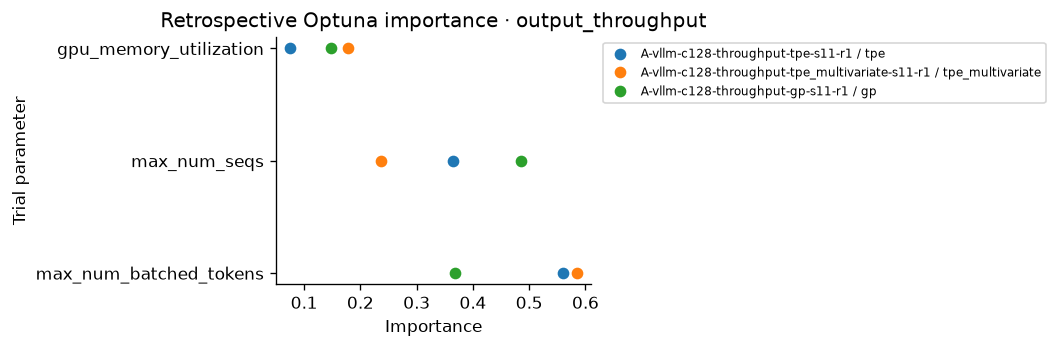

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-pareto_throughput-gp-s11-r1`
- `A-vllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c128-pareto_throughput-tpe-s11-r1,optuna-inference-lab-p0lfaev2,25o6iogc,pareto_throughput,C22,tpe,38.58,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,12,8023.542870,2089.006049,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-inference-lab-p0lfaev2,lmy4u5xz,pareto_throughput,C22,tpe_multivariate,39.48,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,21,8342.212417,2008.666799,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-gp-s11-r1,optuna-inference-lab-p0lfaev2,vpdy77nz,pareto_throughput,C22,gp,39.25,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,21,7811.656519,2147.946572,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-nsga2-s11-r1,optuna-inference-lab-p0lfaev2,22nnu8tm,pareto_throughput,C22,nsga2,39.40,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,29,8126.203358,2059.168171,False,all local COMPLETE trials


##### Matching context C22

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

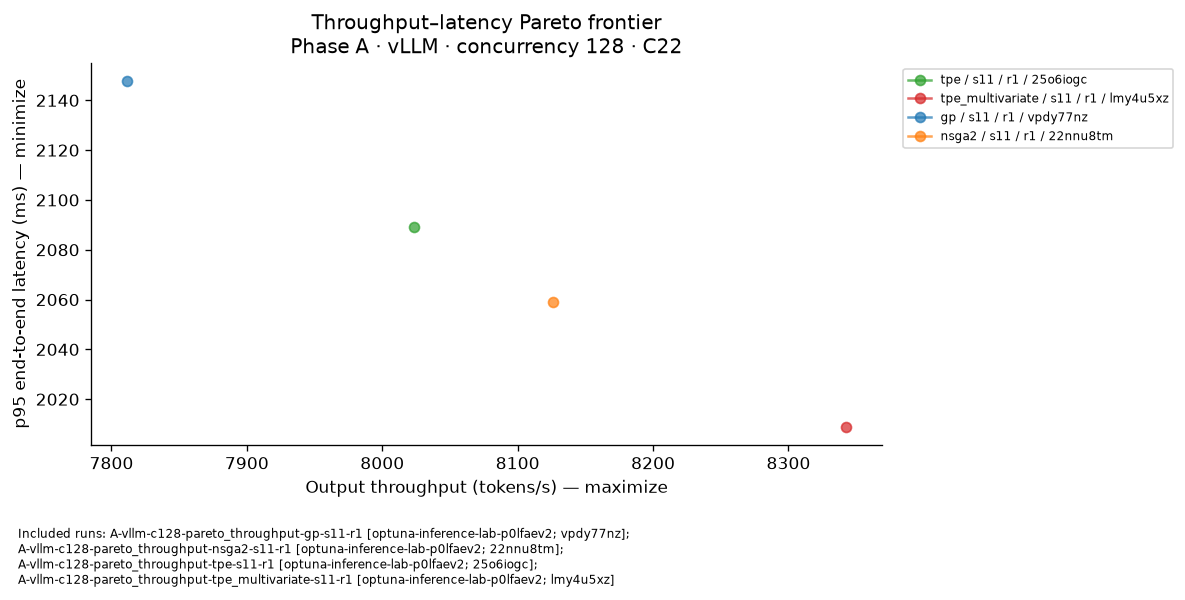

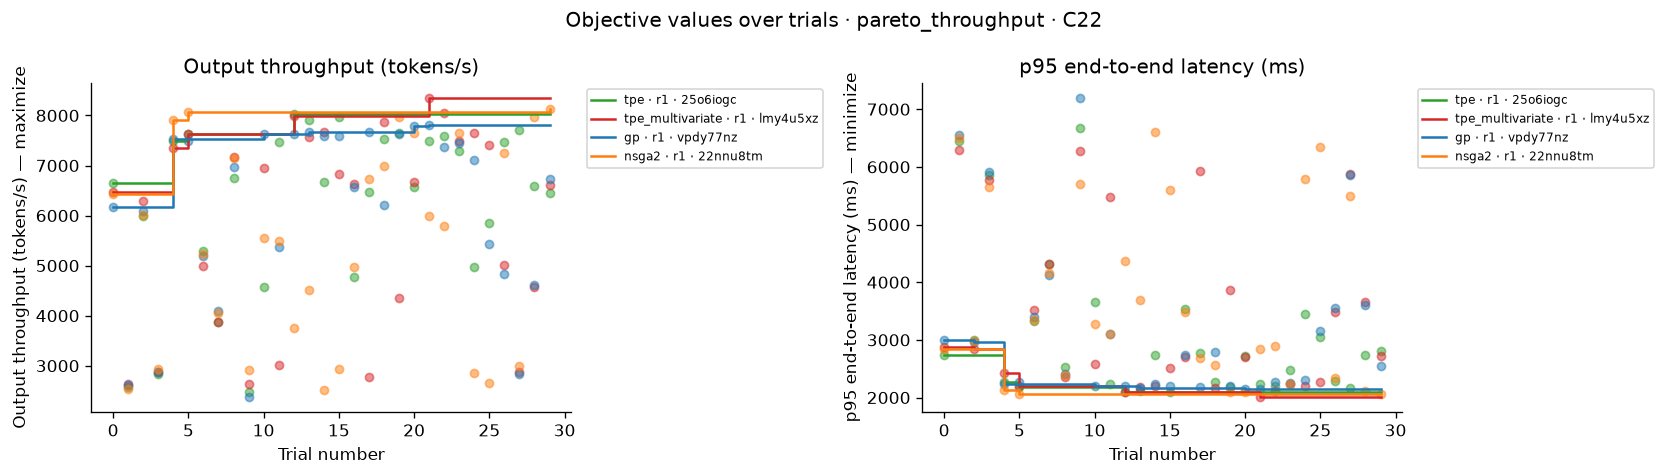

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
12,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,1,max_num_batched_tokens,0.669644
13,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,2,max_num_seqs,0.305501
14,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,3,gpu_memory_utilization,0.024855
15,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,1,max_num_batched_tokens,0.669644
16,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_num_seqs,0.305501
17,A-vllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,3,gpu_memory_utilization,0.024855
18,A-vllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,1,max_num_batched_tokens,0.626389
19,A-vllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,2,max_num_seqs,0.313734
20,A-vllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,3,gpu_memory_utilization,0.059877
21,A-vllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,p95_e2e_latency_ms,1,max_num_batched_tokens,0.626389


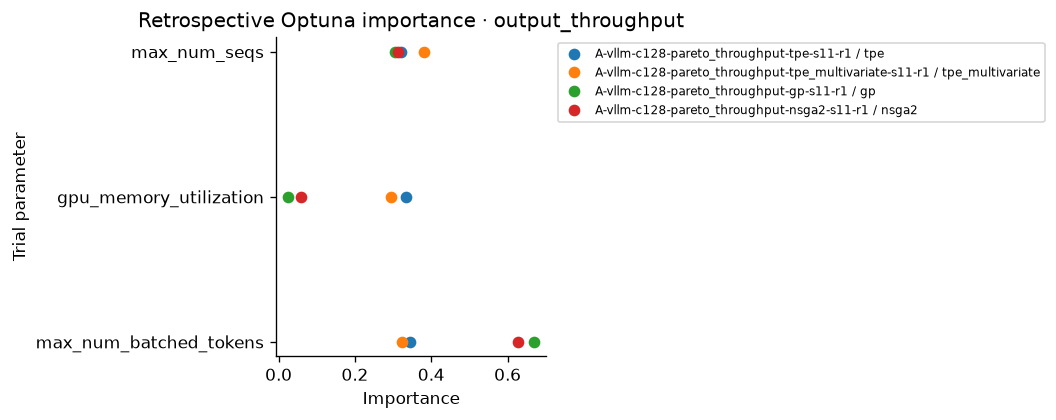

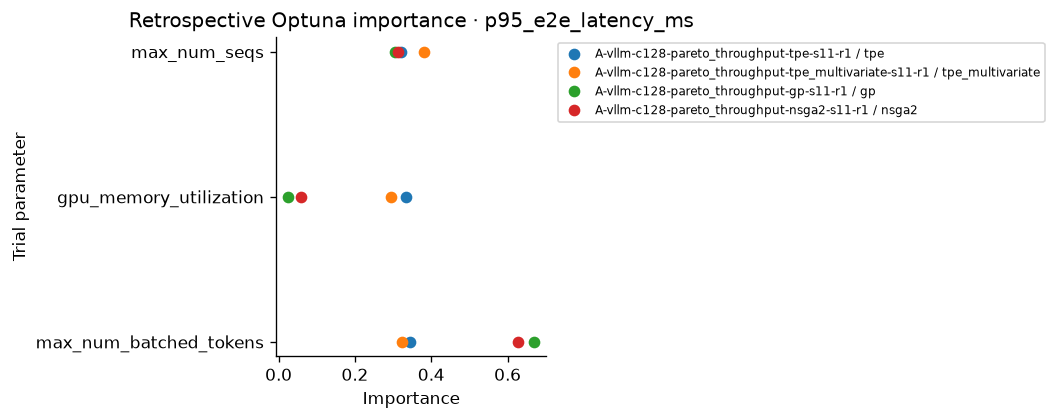

In [30]:
show_framework("A", "vllm")

#### First-repeat vLLM latency highlight


### TRT-LLM

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Phase A {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase A / TRT-LLM: 13 included runs; cutoff 5 minutes


**Runs included: 12.** Optimizer seeds: s11. Repeats: r1, r11, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-e2e-gp-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r1`
- `A-trtllm-c128-e2e-tpe-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r3`
- `A-trtllm-c128-e2e-tpe_multivariate-s11-r11`
- `A-trtllm-c128-pareto_throughput-gp-s11-r1`
- `A-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `A-trtllm-c128-throughput-gp-s11-r1`
- `A-trtllm-c128-throughput-tpe-s11-r1`
- `A-trtllm-c128-throughput-tpe_multivariate-s11-r1`

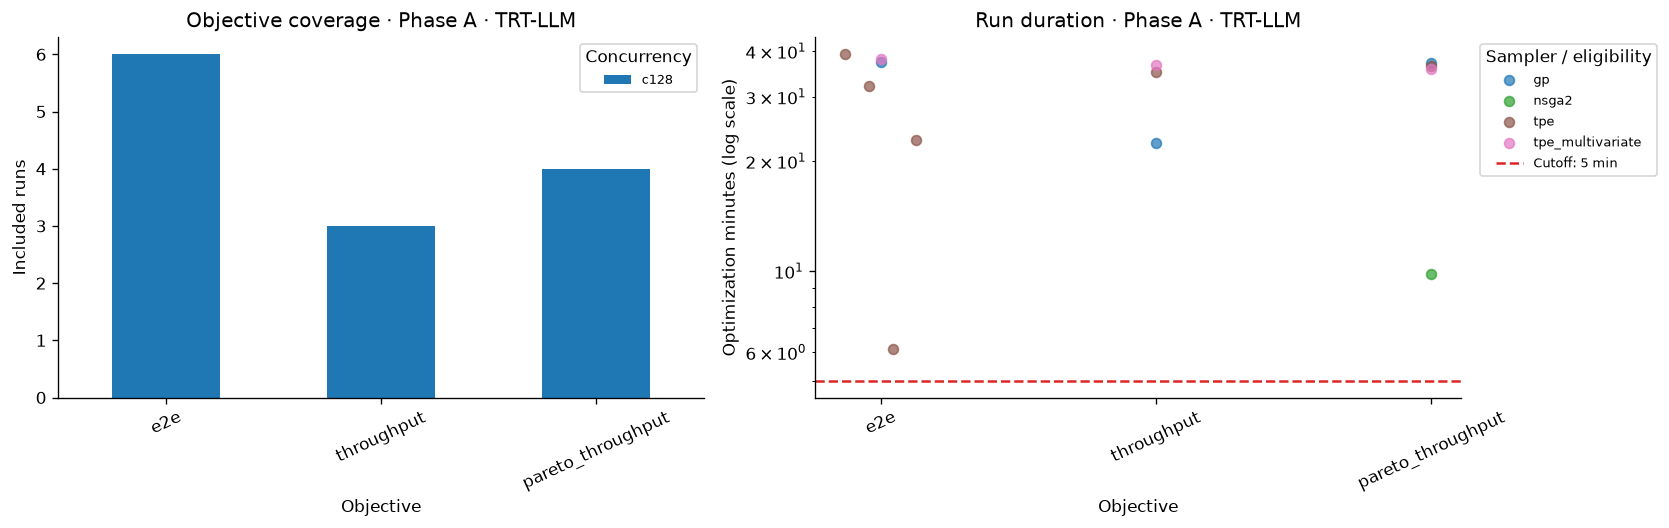

,state,trials
0,COMPLETE,204
1,FAIL,20


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase A · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: s11. Repeats: r1, r11, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-e2e-gp-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r1`
- `A-trtllm-c128-e2e-tpe-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r3`
- `A-trtllm-c128-e2e-tpe_multivariate-s11-r11`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-trtllm-c128-e2e-tpe-s11-r11 [optuna-phase-b-v1 / 527entdy],optuna-phase-b-v1,527entdy,e2e,C19,tpe,32.16,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,9.0,1640.474848,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe_multivariate-s11-r11,optuna-phase-b-v1,rvxd6m2z,e2e,C19,tpe_multivariate,38.12,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5.0,1750.887099,False,all local COMPLETE trials
A-trtllm-c128-e2e-gp-s11-r11,optuna-phase-b-v1,kj512kft,e2e,C19,gp,37.27,kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 32max_num_tokens: 8192,13.0,1758.793908,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,eqz0km99,e2e,C19,tpe,39.39,kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 24max_num_tokens: 4096,2.0,2685.101275,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r3,optuna-phase-b-v1,ei7h522s,e2e,NaN,tpe,22.85,—,NaN,NaN,None,no eligible result
A-trtllm-c128-e2e-tpe-s11-r11 [optuna-phase-b-v1 / bxkkbjmk],optuna-phase-b-v1,bxkkbjmk,e2e,NaN,tpe,6.11,—,NaN,NaN,None,no eligible result


##### Matching context C19

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

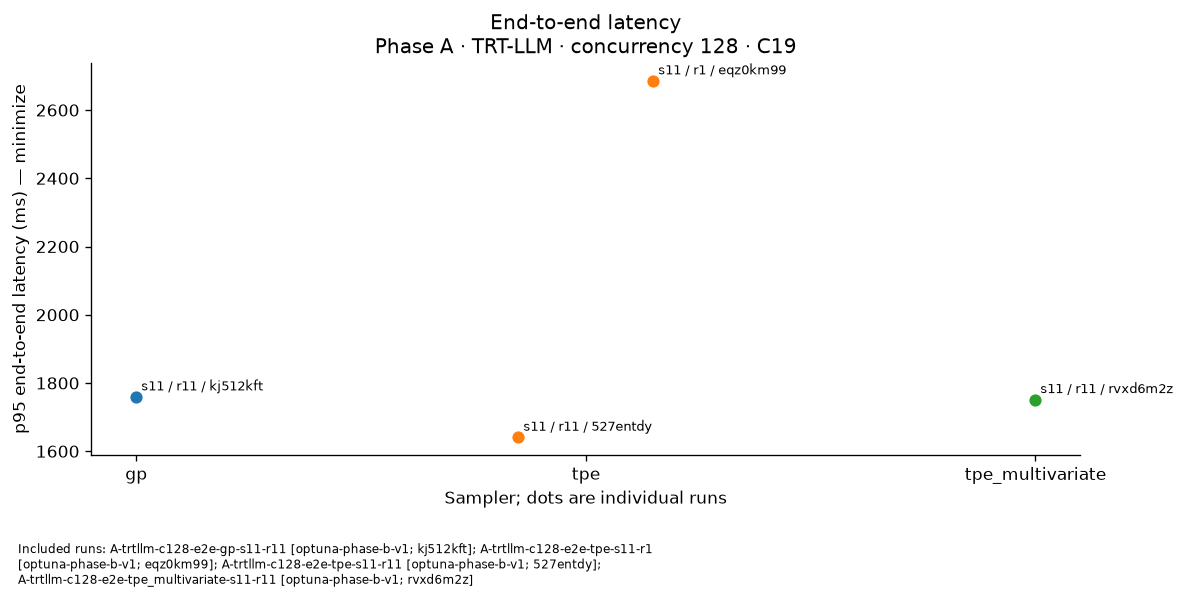

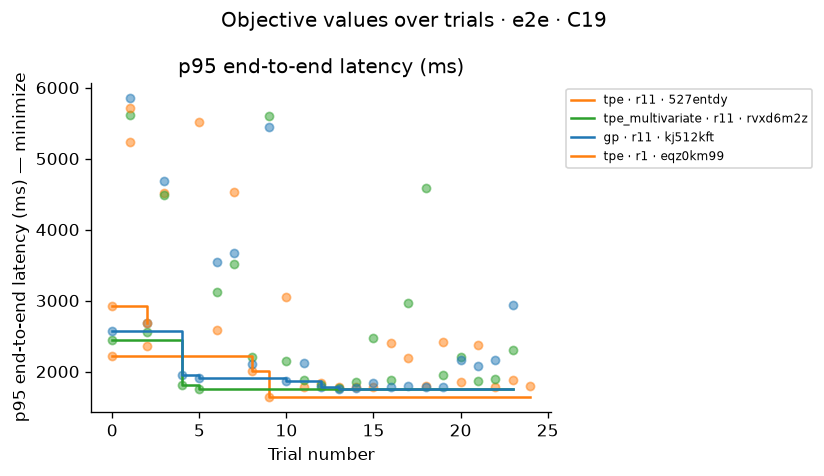

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
6,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,1,max_num_tokens,0.665722
7,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,2,max_batch_size,0.173509
8,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.160769
9,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,1,max_batch_size,0.825395
10,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,2,max_num_tokens,0.106737
11,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.067868
0,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,1,max_batch_size,0.807060
1,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,2,max_num_tokens,0.191203
2,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.001736
3,A-trtllm-c128-e2e-tpe_multivariate-s11-r11,tpe_multivariate,p95_e2e_latency_ms,1,max_num_tokens,0.538539


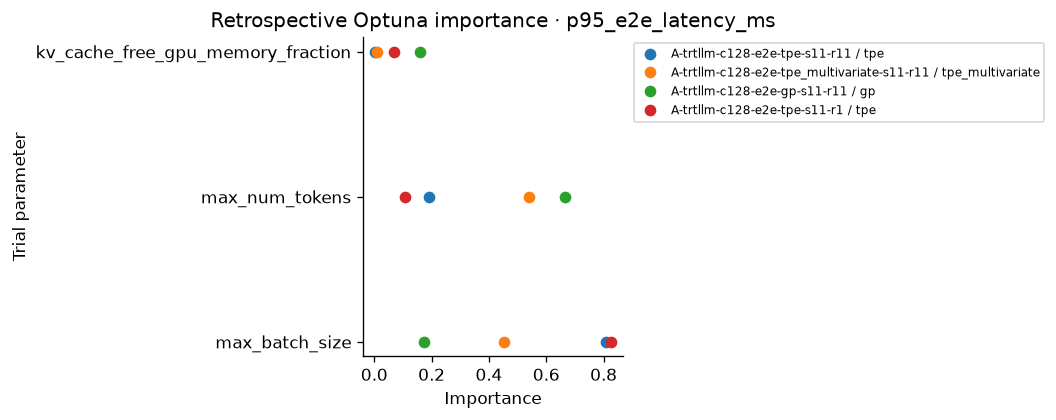

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-throughput-gp-s11-r1`
- `A-trtllm-c128-throughput-tpe-s11-r1`
- `A-trtllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
A-trtllm-c128-throughput-tpe-s11-r1,optuna-phase-b-v1,orj0zbj4,throughput,C13,tpe,35.00,kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 32max_num_tokens: 6144,15,9635.181631,False,all local COMPLETE trials
A-trtllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,7v4tnc4r,throughput,C13,tpe_multivariate,36.64,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,9677.333780,False,all local COMPLETE trials
A-trtllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,gtjdz49d,throughput,C13,gp,22.36,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9204.285247,False,all local COMPLETE trials


##### Matching context C13

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

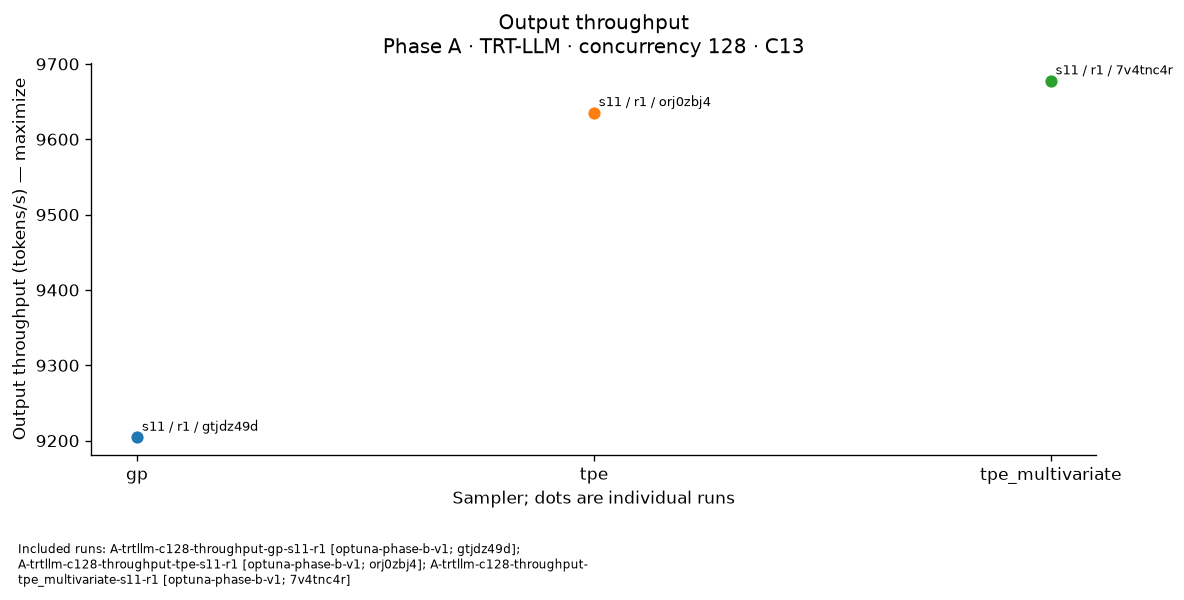

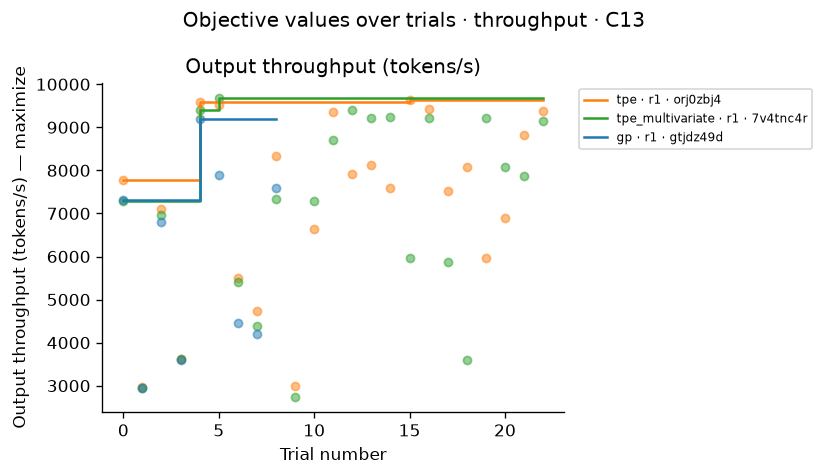

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
6,A-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,1,kv_cache_free_gpu_memory_fraction,0.352002
7,A-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,2,max_batch_size,0.352002
8,A-trtllm-c128-throughput-gp-s11-r1,gp,output_throughput,3,max_num_tokens,0.295996
0,A-trtllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,1,max_batch_size,0.635744
1,A-trtllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,2,max_num_tokens,0.228800
2,A-trtllm-c128-throughput-tpe-s11-r1,tpe,output_throughput,3,kv_cache_free_gpu_memory_fraction,0.135456
3,A-trtllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,1,max_batch_size,0.702644
4,A-trtllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,2,max_num_tokens,0.245189
5,A-trtllm-c128-throughput-tpe_multivariate-s11-r1,tpe_multivariate,output_throughput,3,kv_cache_free_gpu_memory_fraction,0.052166


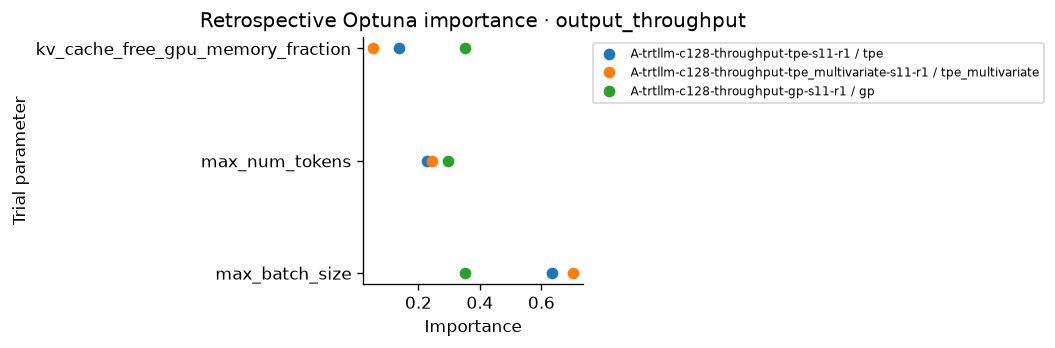

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-pareto_throughput-gp-s11-r1`
- `A-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
A-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,zjniw2qc,pareto_throughput,C03,tpe,36.50,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,15,9698.764238,1784.890725,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cl9btqz4,pareto_throughput,C03,tpe_multivariate,35.78,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9515.403342,1900.893107,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cl9btqz4,pareto_throughput,C03,tpe_multivariate,35.78,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,9473.159753,1834.726378,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,0scnkia6,pareto_throughput,C03,gp,37.22,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9059.514597,1944.418541,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,0scnkia6,pareto_throughput,C03,gp,37.22,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,8960.386219,1905.267489,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,1gnoh54k,pareto_throughput,C03,nsga2,9.83,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,8471.195193,2029.029433,False,all local COMPLETE trials


##### Matching context C03

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

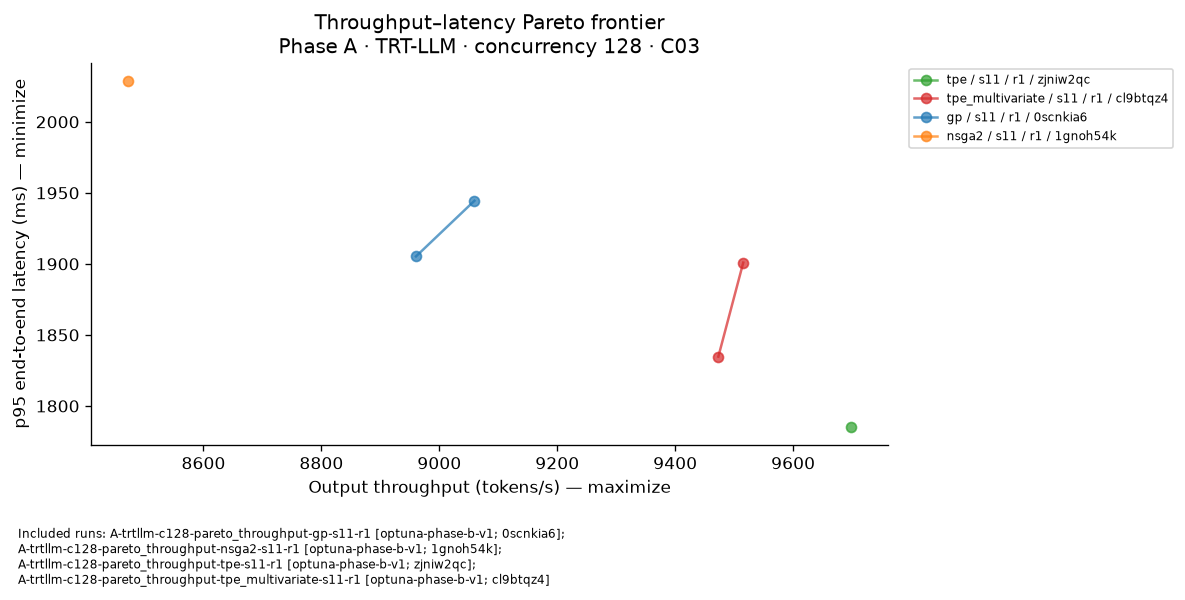

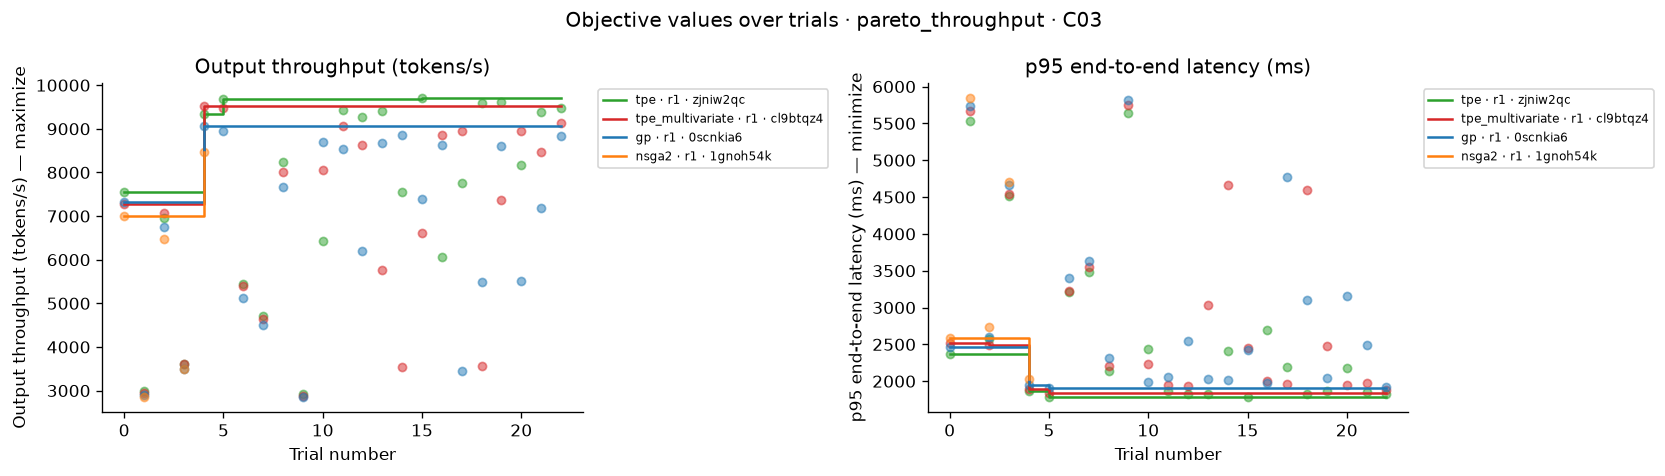

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
12,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,1,kv_cache_free_gpu_memory_fraction,0.528540
13,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,2,max_batch_size,0.356629
14,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,output_throughput,3,max_num_tokens,0.114831
15,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,1,kv_cache_free_gpu_memory_fraction,0.520489
16,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_batch_size,0.351197
17,A-trtllm-c128-pareto_throughput-gp-s11-r1,gp,p95_e2e_latency_ms,3,max_num_tokens,0.128314
18,A-trtllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,1,max_num_tokens,0.694932
19,A-trtllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,2,max_batch_size,0.295974
20,A-trtllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,output_throughput,3,kv_cache_free_gpu_memory_fraction,0.009094
21,A-trtllm-c128-pareto_throughput-nsga2-s11-r1,nsga2,p95_e2e_latency_ms,1,max_num_tokens,0.694932


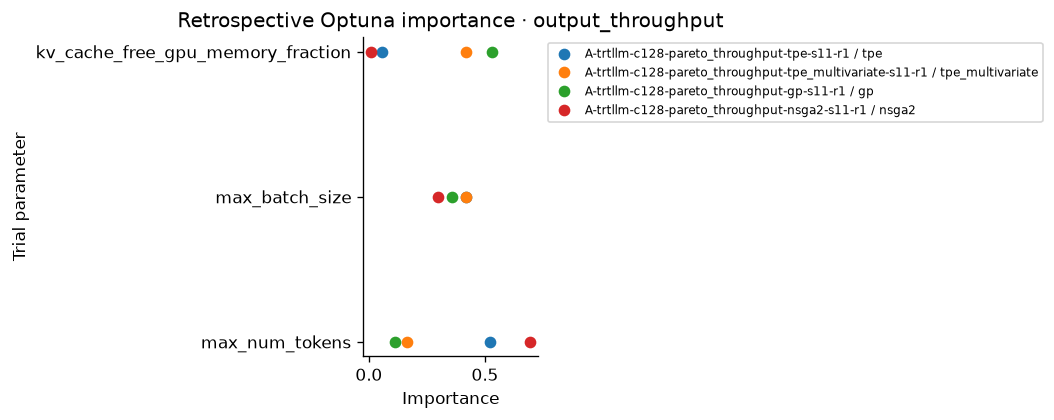

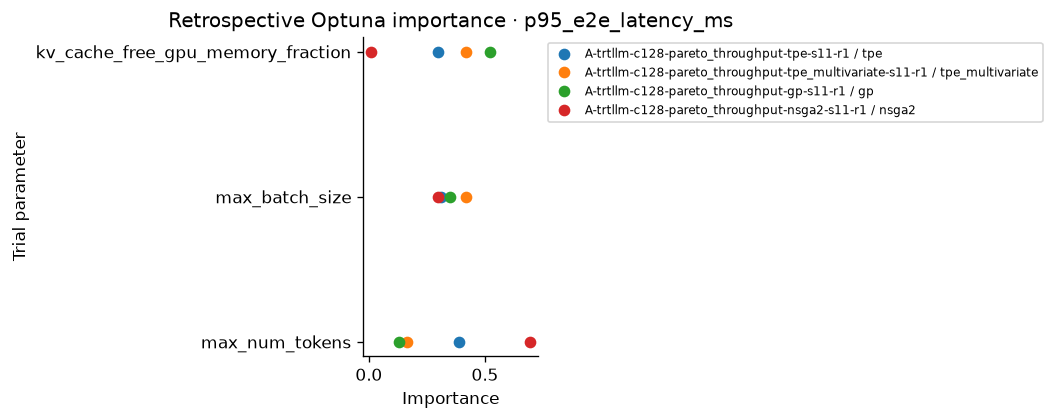

In [31]:
show_framework("A", "trtllm")

### SGLang

Run inventories, metadata, and objective results below belong only to this framework in the current phase. Seeds and repeats are listed from the actual study names, never assumed.

#### Phase A {'vllm': 'vLLM', 'trtllm': 'TRT-LLM', 'sglang': 'SGLang'} report cell

Phase A / SGLang: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-sglang-c128-e2e-gp-s11-r1`
- `A-sglang-c128-e2e-grid-s11-r1`
- `A-sglang-c128-e2e-qmc-s11-r1`
- `A-sglang-c128-e2e-random-s11-r1`
- `A-sglang-c128-e2e-tpe-s11-r1`
- `A-sglang-c128-e2e-tpe_multivariate-s11-r1`

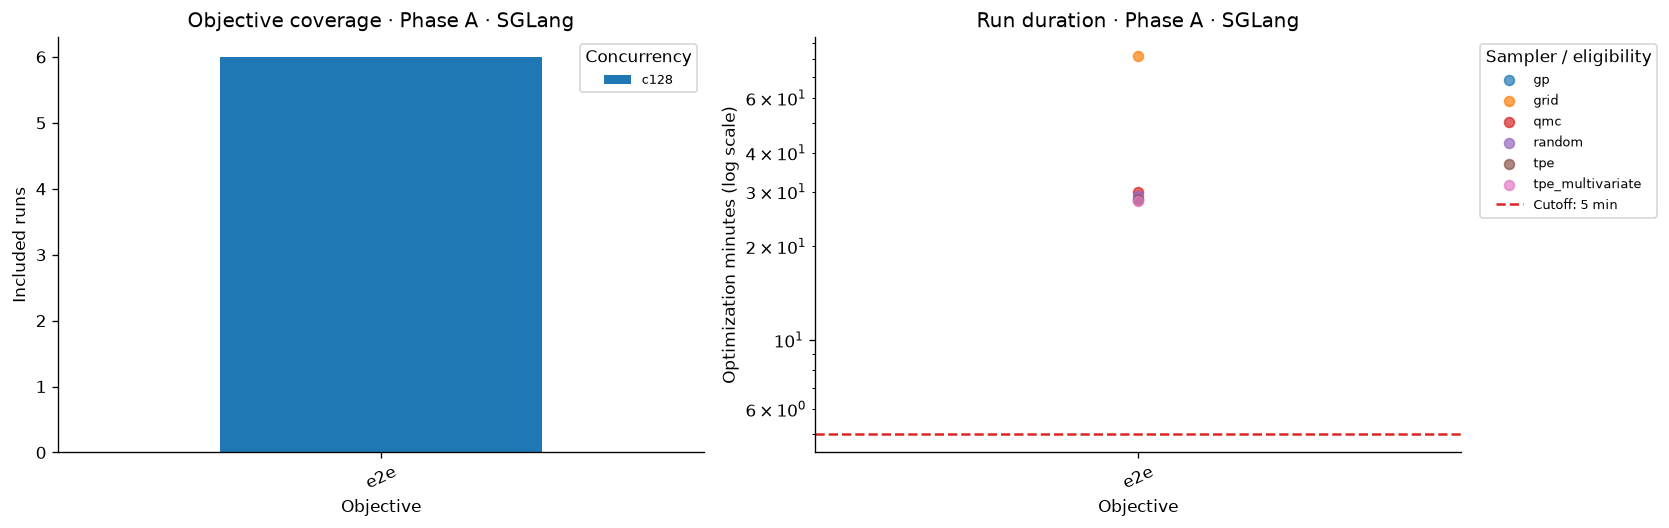

,state,trials
0,COMPLETE,184


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase A · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-sglang-c128-e2e-gp-s11-r1`
- `A-sglang-c128-e2e-grid-s11-r1`
- `A-sglang-c128-e2e-qmc-s11-r1`
- `A-sglang-c128-e2e-random-s11-r1`
- `A-sglang-c128-e2e-tpe-s11-r1`
- `A-sglang-c128-e2e-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-sglang-c128-e2e-grid-s11-r1,optuna-phase-b-v1,g7myirzj,e2e,C16,grid,81.89,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,38,1623.698405,False,all local COMPLETE trials
A-sglang-c128-e2e-random-s11-r1,optuna-phase-b-v1,8jlxzlfd,e2e,C16,random,29.11,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,5,1616.353535,False,all local COMPLETE trials
A-sglang-c128-e2e-qmc-s11-r1,optuna-phase-b-v1,t9955t18,e2e,C16,qmc,29.83,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,18,1613.971431,False,all local COMPLETE trials
A-sglang-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,f0b03wlc,e2e,C16,tpe,28.23,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,11,1612.223303,False,all local COMPLETE trials
A-sglang-c128-e2e-tpe_multivariate-s11-r1,optuna-phase-b-v1,ieltqkx2,e2e,C16,tpe_multivariate,28.09,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,5,1610.241877,False,all local COMPLETE trials
A-sglang-c128-e2e-gp-s11-r1,optuna-phase-b-v1,l010bsj9,e2e,C16,gp,28.48,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.8,18,1602.007511,False,all local COMPLETE trials


##### Matching context C16

**Matched workload and environment**

**model:** `"Qwen/Qwen3.5-0.8B"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

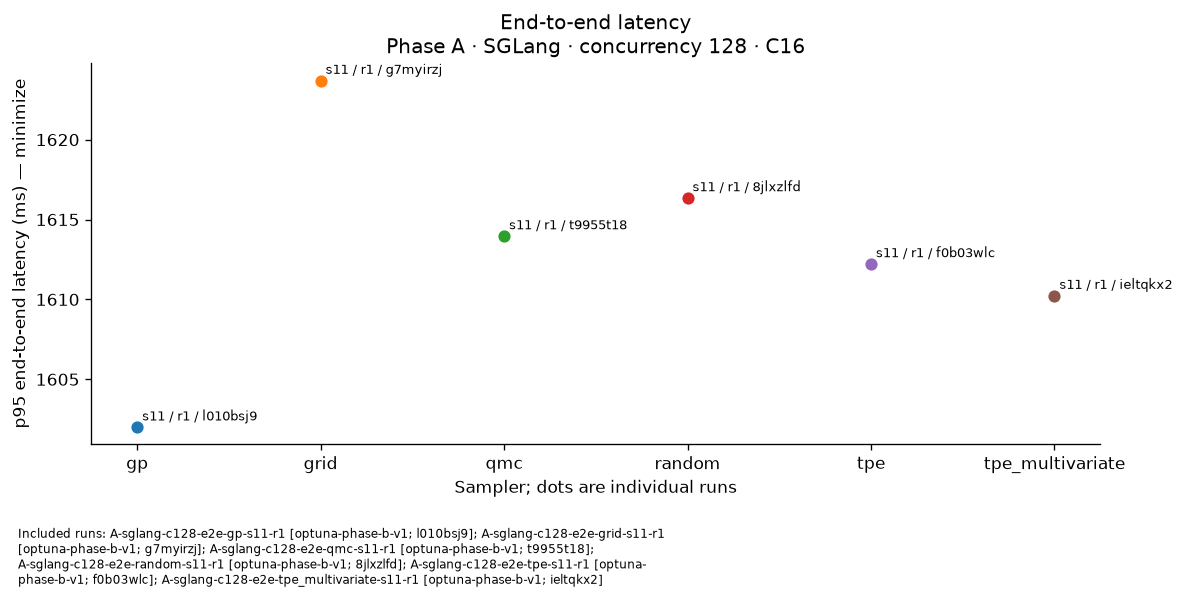

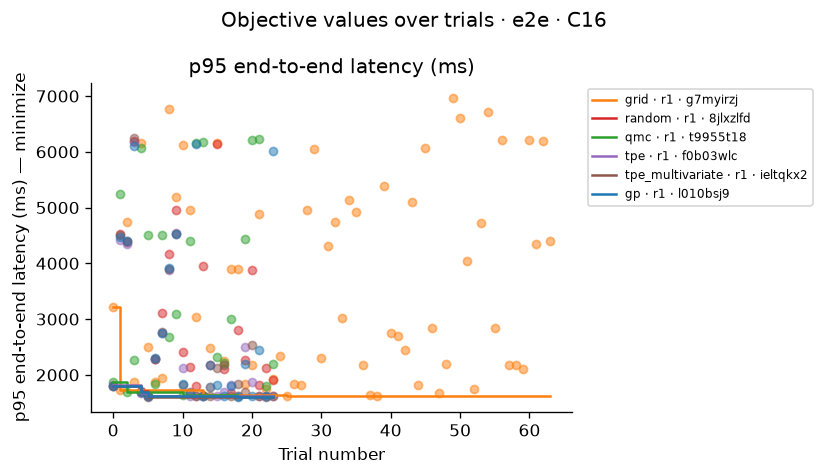

/tmp/ipykernel_194393/674171864.py:26: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_194393/674171864.py:27: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(


,run,sampler,metric,rank,parameter,importance
15,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,1,chunked_prefill_size,0.465810
16,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_running_requests,0.327400
17,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,3,mem_fraction_static,0.206790
0,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,1,max_running_requests,0.749077
1,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,2,chunked_prefill_size,0.249846
2,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,3,mem_fraction_static,0.001077
6,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,1,max_running_requests,0.700645
7,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,2,chunked_prefill_size,0.297469
8,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,3,mem_fraction_static,0.001886
3,A-sglang-c128-e2e-random-s11-r1,random,p95_e2e_latency_ms,1,max_running_requests,0.644521


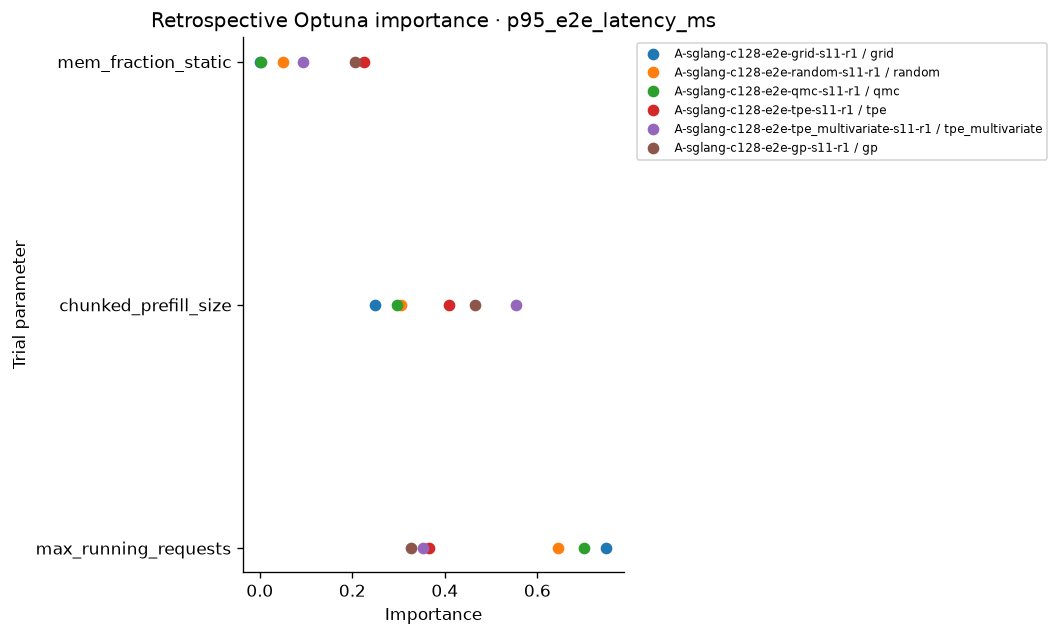

In [32]:
show_framework("A", "sglang")

## Audit: exclusions and source coverage

These tables explain runs that did not contribute. No excluded run is used by the framework plots. W&B-only candidate summaries cannot establish full search histories.

### Excluded runs and source issues


In [33]:
print(f"Excluded runs: {len(excluded)}")
excluded_runs = manifest(excluded)
excluded_runs["exclusion_reason"] = [exclusion(r) for r in excluded]
display(excluded_runs)
source_issues = pd.DataFrame(issues, columns=["source", "issue"])
display(source_issues)

display(pd.DataFrame(result_issues, columns=["study_name", "issue"]))

Excluded runs: 104


,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files,exclusion_reason
0,A,vllm,A-vllm-c128-e2e-grid-s11-r2,0.098282,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,wcgim3ga,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/wcgim3ga,finished,optuna-phase-b-v1,[],under five minutes
1,A,vllm,A-vllm-c128-e2e-random-s11-r2,0.028633,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,ypzfoa1l,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ypzfoa1l,finished,optuna-phase-b-v1,[],under five minutes
2,A,vllm,A-vllm-c128-e2e-qmc-s11-r2,0.024561,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,rfs7oeyf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/rfs7oeyf,finished,optuna-phase-b-v1,[],under five minutes
3,A,vllm,A-vllm-c128-e2e-tpe-s11-r2,0.026064,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,svhs7c1d,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/svhs7c1d,finished,optuna-phase-b-v1,[],under five minutes
4,A,vllm,A-vllm-c128-e2e-tpe_multivariate-s11-r2,0.025857,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,mots6tmu,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/mots6tmu,finished,optuna-phase-b-v1,[],under five minutes
5,A,vllm,A-vllm-c128-e2e-gp-s11-r2,0.026023,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,hfsyb4i3,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/hfsyb4i3,finished,optuna-phase-b-v1,[],under five minutes
6,B,sglang,B-sglang-c128-e2e-tpe-s11-r2,0.031121,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,7gwvubpf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwvubpf,finished,optuna-phase-b-v1,[],under five minutes
7,B,sglang,B-sglang-c128-e2e-tpe-s11-r3,0.029775,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,szsjx7ht,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/szsjx7ht,crashed,optuna-phase-b-v1,[],under five minutes
8,B,sglang,B-sglang-c128-e2e-tpe-s11-r4,0.027810,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,5w5betog,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/5w5betog,finished,optuna-phase-b-v1,[],under five minutes
9,B,sglang,B-sglang-c128-e2e-tpe-s11-r5,0.026836,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,tdqamjke,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/tdqamjke,finished,optuna-phase-b-v1,[],under five minutes


,source,issue
0,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/sglang/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-sglang-native
1,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/trtllm/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-trtllm-native
2,/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/vllm/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-vllm-native


,study_name,issue
0,A-trtllm-c128-e2e-tpe-s11-r3,No eligible completed objective results
1,A-trtllm-c128-e2e-tpe-s11-r11,No eligible completed objective results
2,B-trtllm-c128-e2e-tpe_multivariate-s11-r2,No eligible completed objective results


In [36]:
def show_phase_b_top_performance(top_n=10):
    """Rank eligible Phase B objective results across frameworks."""
    # report_runs reads from `included`, which already applies the 5-minute cutoff.
    runs = [
        run
        for framework in FRAMEWORK_NAMES
        for run in report_runs("B", framework)
    ]
    if not runs:
        print("No Phase B runs meet the runtime cutoff.")
        return

    def run_identity(run):
        return run["wandb_url"] or f'{run["database"]}::{run["study_name"]}'

    runs_by_identity = {run_identity(run): run for run in runs}
    included_ids = set(runs_by_identity)

    # Keep only stored objective candidates belonging to the selected Phase B runs.
    candidates = (
        study_candidates[study_candidates["run_identity"].isin(included_ids)].copy()
        if not study_candidates.empty
        else pd.DataFrame()
    )
    if candidates.empty:
        print("No eligible Phase B objective results for the selected runs.")
        return

    objectives = sorted(
        run["contract"].get("target")
        for run in runs
        if run["contract"].get("target")
    )

    for objective in objectives:
        objective_runs = [
            run for run in runs
            if run["contract"].get("target") == objective
        ]
        objective_ids = {run_identity(run) for run in objective_runs}
        objective_candidates = candidates[
            candidates["run_identity"].isin(objective_ids)
        ].copy()

        if objective_candidates.empty:
            continue

        # The contract stores metric directions as a list aligned with `metrics`.
        metrics = objective_runs[0]["contract"].get("metrics", [])
        raw_directions = objective_runs[0]["contract"].get("directions", [])
        directions = (
            raw_directions
            if isinstance(raw_directions, dict)
            else dict(zip(metrics, raw_directions or []))
        )

        if not metrics or metrics[0] not in objective_candidates:
            print(f"Skipping {objective}: its ranking metric is unavailable.")
            continue

        metric = metrics[0]
        objective_candidates = objective_candidates.dropna(subset=[metric])
        if objective_candidates.empty:
            continue

        direction = str(directions.get(metric, "MAXIMIZE")).upper()
        ascending = direction == "MINIMIZE"
        top_candidates = objective_candidates.sort_values(
            metric, ascending=ascending, na_position="last"
        ).head(top_n)

        # Pass only runs represented in the ranked results so the table cannot
        # add placeholder rows for runs with no eligible objective candidate.
        top_ids = set(top_candidates["run_identity"])
        top_runs = [
            run for run in objective_runs
            if run_identity(run) in top_ids
        ]

        display(Markdown(
            f"### Phase B · {OBJECTIVE_TITLES.get(objective, objective)}"
            f" · Top {len(top_candidates)} trials across frameworks"
        ))
        display(Markdown(
            f"Ranked by **{metric}** ({direction.lower()}). "
            f"Runs meet the {MIN_RUN_SECONDS / 60:g}-minute cutoff."
        ))
        display(Markdown(included_run_note(
            [run["study_name"] for run in top_runs]
        )))

        table = objective_result_table(top_runs, top_candidates, objective)
        display(HTML(table.to_html(escape=False, index=False)))

In [37]:
show_phase_b_top_performance(top_n=10)


### Phase B · End-to-end latency · Top 10 trials across frameworks

Ranked by **p95_e2e_latency_ms** (minimize). Runs meet the 5-minute cutoff.

**Runs included: 10.** Optimizer seeds: s11. Repeats: r1, r2, r22, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-gp-s11-r2`
- `B-trtllm-c128-e2e-gp-s11-r22`
- `B-trtllm-c128-e2e-tpe-s11-r1`
- `B-trtllm-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r22`
- `B-vllm-c128-e2e-gp-s11-r3`
- `B-vllm-c128-e2e-tpe-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-tpe-s11-r3,optuna-inference-lab-ezy2i4mn,15gvekae,e2e,C21,tpe,54.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: balanced,11,2597.275879,False,W&B candidate summary only
B-vllm-c128-e2e-tpe_multivariate-s11-r3,optuna-inference-lab-ezy2i4mn,e31bigam,e2e,C21,tpe_multivariate,45.48,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 30976max_num_seqs: 128performance_mode: interactivity,15,2419.543139,False,W&B candidate summary only
B-vllm-c128-e2e-gp-s11-r3,optuna-inference-lab-ezy2i4mn,a8ktejgz,e2e,C21,gp,48.74,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,13,2318.987960,False,W&B candidate summary only
B-trtllm-c128-e2e-tpe_multivariate-s11-r2,optuna-phase-b-v1,ul1h9fbn,e2e,C06,tpe_multivariate,14.41,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 32max_num_tokens: 6144,15,3752.892612,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r22,optuna-phase-b-v1,wkyxp7vs,e2e,C20,gp,57.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,10,2124.685405,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,nx5p83d3,e2e,C06,tpe,32.68,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,9,3816.721492,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r2,optuna-phase-b-v1,rigivcxx,e2e,C06,gp,52.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,5,3805.106405,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r22,optuna-phase-b-v1,hgilz7qb,e2e,C20,tpe,55.08,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5,2970.294046,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r22,optuna-phase-b-v1,gzn2ba1j,e2e,C20,tpe_multivariate,53.39,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 64max_num_tokens: 12032,10,2661.387811,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r22,optuna-phase-b-v1,8hidg674,e2e,C18,tpe,33.32,attention_backend: tritonchunked_prefill_size: 24320cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 88mem_fra

### Phase B · End-to-end latency · Top 10 trials across frameworks

Ranked by **p95_e2e_latency_ms** (minimize). Runs meet the 5-minute cutoff.

... (198 outputs left out)

### Phase B · Output throughput · Top 10 trials across frameworks

Ranked by **output_throughput** (maximize). Runs meet the 5-minute cutoff.

**Runs included: 10.** Optimizer seeds: s11. Repeats: r1, r21, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-gp-s11-r21`
- `B-sglang-c128-throughput-tpe-s11-r21`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r21`
- `B-trtllm-c128-throughput-gp-s11-r22`
- `B-trtllm-c128-throughput-tpe-s11-r22`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r22`
- `B-vllm-c128-throughput-gp-s11-r1`
- `B-vllm-c128-throughput-tpe-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-tpe-s11-r1,optuna-phase-b-v1,43sekwr7,throughput,C15,tpe,37.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 15104max_num_seqs: 128performance_mode: throughput,18,7216.036606,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,4hxfaxio,throughput,C15,tpe_multivariate,37.69,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: balanced,16,7338.657147,False,all local COMPLETE trials
B-vllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,2f2gjeil,throughput,C15,gp,37.70,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,17,7258.913112,False,all local COMPLETE trials
B-trtllm-c128-throughput-gp-s11-r22,optuna-phase-b-v1,9y5kjcb9,throughput,C14,gp,58.51,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 22016,13,7911.503773,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cwsqjp3c,throughput,C05,tpe_multivariate,55.45,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,10,4311.995156,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r22,optuna-phase-b-v1,oggia3g4,throughput,C14,tpe,53.66,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 28672,17,7798.318941,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r22,optuna-phase-b-v1,qbbdfr6u,throughput,C14,tpe_multivariate,55.65,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 25856,10,7756.766881,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r21,optuna-phase-b-v1,tz0bzitz,throughput,C12,tpe,34.40,attention_backend: tritonchunked_prefill_size: 32512cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: fcfs,13,6323.834874,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r21,optuna-phase-b-v1,tvgcy76k,throughput,C12,tpe_multivariate,33.54,attention_backend: fa3chunked_prefill_size: 21248cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 120mem_fraction_static: 0.75schedule_conservativeness: 1.0schedule_policy: fcfs,15,6261.418054,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-